# Medical Image Encoding

In [1]:
import quimb.tensor as qtn
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

yikes did i delete all of joshs code here? make sure to copy it back in.

In [2]:
import quimb.tensor as qtn
import quimb as qu
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from math import cos, sin, pi
from autoray import do
from scipy.linalg import qr, null_space
from typing import Dict, List, Tuple, Optional
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from collections import Counter
import autoray as ar
import jax.numpy as jnp
from skimage import data
from skimage.transform import resize
from scipy.stats import unitary_group
#import geoopt
#import geotorch
import math
import torch
import torch.nn as nn
from torch.nn.utils import parametrize

from functools import partial

'''This is the contraction method for the tensor networks ie For all future tensor contractions, automatically search for a high-quality contraction path (using a slower but smarter optimizer), so that contractions run efficiently on large networks '''
qtn.set_contract_strategy('auto-hq')

import mps_to_circuit as mtc
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator


''' This allows us to get the information from the qiskit circuit '''
def get_qiskit_gate_info(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for ci in qc.data:                      # ci is a CircuitInstruction
        instr = ci.operation                # was: instr
        qargs = ci.qubits                   # was: qargs
        qubits = [qc.find_bit(q).index for q in qargs]

        try:
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")

    return gates


'''Ensures the indicies of the TN are lrp'''
def ensure_mps_shape_lrp(mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Return a copy of `mps` whose site tensors have a consistent axis order:
      - interior sites: (vL, vR, p)
      - left edge:      (vR, p)
      - right edge:     (vL, p)

    This is the default 'lrp' format used by quimb.
    """
    mps = mps.copy()
    N = mps.L

    for i in range(N):
        T = mps[i]
        p = mps.site_ind(i)
        # all non-physical indices on this site
        virt = [ix for ix in T.inds if ix != p]

        if i == 0:
            # left edge: single virtual = vR
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vR = virt[0]
            T.transpose(vR, p, inplace=True)

        elif i == N - 1:
            # right edge: single virtual = vL
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vL = virt[0]
            T.transpose(vL, p, inplace=True)

        else:
            # interior: two virtuals; identify left vs right by neighbor sharing
            assert len(virt) == 2, f"Site {i} expected 2 virtual legs, found {len(virt)}."
            left_neighbor_inds = set(mps[i - 1].inds)
            right_neighbor_inds = set(mps[i + 1].inds)

            # the bond shared with the left/right neighbor
            vL = next(ix for ix in virt if ix in left_neighbor_inds)
            vR = next(ix for ix in virt if ix in right_neighbor_inds)

            T.transpose(vL, vR, p, inplace=True)

    return mps


'''Make the circuit in qiskit then map to quimb'''
def mps_to_circuit_quimb(mps: qtn.MatrixProductState) -> qtn.Circuit:
    """ Functionality thanks to https://github.com/qiskit-community/mps-to-circuit. MPS must have shape (vL,vR, phys) unless shape is specified. """
    
    psi = ensure_mps_shape_lrp(mps.copy())
    psi.left_canonicalize(inplace=True)

    arrays = [np.asarray(A, dtype=np.complex128) for A in psi.arrays]

    qiskit_qc = mtc.mps_to_circuit(arrays, shape='lrp',method='exact')

    gates_info = get_qiskit_gate_info(qiskit_qc)

    qc = qtn.Circuit(mps.L)
   
    for gate in gates_info:
        name, qubits, U = gate
        qubits.reverse()
        qc.apply_gate(U, *qubits)

    return qc

"""def optimise_to_zero(n: int,eps: float = 1e-2):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    
    to_opt = qc.uni

    targ_qc = qtn.Circuit(n)
    I4 = qu.eye(4)  # two-qubit identity (4×4)
    for i in range(n - 1): targ_qc.apply_gate(I4, i, i + 1, tags=['SU4'])
    targ_uni = targ_qc.uni 

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ_uni},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    #opt_uni = tnopt.optimize_basinhopping(n=600,tol=1e-14,nhop=100)

    params = opt_uni.get_params()

    return params"""


'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_identity(eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(np.eye(4).reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    return params


'''Gives the paramters of a complete unity circuit not just a gate'''
def optimise_to_zero(n: int,eps: float = 1e-2):
    params = optimise_su4_gate_to_identity(eps=eps)[2]
        
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params


'''Gives the parameterised identity circ'''
def near_zero_parametrized_circ_layer(n: int, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised near-identity """

    #params = optimise_to_zero(n)
    params = GLOBAL_IDENTITY_LAYER_PARAMS ###--what is this????
    qc = qtn.Circuit(n)
    #for idx in range(n-1):
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc

'''Using the optimised identity params this becomes an idenity circuit layer'''
def parametrized_circ_layer(n: int, params: np.ndarray, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised with params. """
    qc = qtn.Circuit(n)
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc


'''Computes the Schmidt coefficients (or their squares, i.e. entanglement spectrum) for a bipartition of a quantum state, given the left and right Gram matrices'''
'''def schmidt_from_gram(L,R,square: bool = True, cut_zeros: bool = True) -> torch.Tensor:
    L = (L + L.conj().T) / 2
    R = (R + R.conj().T) / 2

    # 2) eigensqrt of L
    w, U = torch.linalg.eigh(L)
    w = torch.clip(w, 0, None)
    Lh = (U * torch.sqrt(w)[None, :]) @ U.conj().T

    # 3) build A and solve
    A = Lh @ R @ Lh
    A = (A + A.conj().T) / 2
    mu = torch.linalg.eigvalsh(A)
    mu = torch.clip(mu.real, 0, None)

    # Schmidt coefficients
    s = torch.sqrt(mu).flip(0)

    if square:
        s = s**2

    if cut_zeros:
        s = s[s > 1e-14]
        
    return s'''
import torch
from typing import Tuple, Optional

def schmidt_from_gram(
    L: torch.Tensor,
    R: torch.Tensor,
    square: bool = True,
    cut_zeros: bool = True,
    *,
    eps_abs: float = 1e-16,
    eps_rel: float = 1e-12,
    cond_limit: float = 1e10,
    jitter: float = 1e-8,
    return_info: bool = False,
) -> torch.Tensor:
    """
    Compute Schmidt coefficients from Gram matrices L, R in a numerically robust way.

    L, R: (..., N, N) complex or real tensors. Supports batching.
    eps_abs: absolute minimum eigenvalue (very tiny floor).
    eps_rel: relative floor as a fraction of the max eigenvalue per matrix.
    cond_limit: maximum allowed condition number ~ max_eig / min_allowed_eig.
                If cond_limit is finite, min_allowed_eig = max(max_eig/cond_limit, eps_rel*max_eig, eps_abs)
    jitter: extra additive jitter to the diagonal (useful to force PD for cholesky; typically 0).
    return_info: if True returns (s, info_dict) where info_dict contains diagnostics.

    Returns:
      s: Schmidt coefficients (descending), optionally squared if square=True and filtered if cut_zeros=True.
    """
    # 0) basic checks and symmetrize
    if L.shape[-2] != L.shape[-1] or R.shape[-2] != R.shape[-1]:
        raise ValueError("L and R must be square matrices (..., N, N).")
    if L.shape[-2] != R.shape[-2]:
        raise ValueError("L and R must be same size.")
    if not torch.isfinite(L).all() or not torch.isfinite(R).all():
        raise ValueError("L or R contains NaN/Inf.")
    
    # Hermitize (works for complex data too)
    herm = lambda X: (X + X.conj().transpose(-2, -1)) / 2
    L = herm(L)
    R = herm(R)

    # Optionally add tiny jitter first (keeps reconstruction stable)
    if jitter > 0:
        N = L.shape[-1]
        eye = torch.eye(N, device=L.device, dtype=L.dtype)
        L = L + jitter * eye

    # eigendecompose L
    # PREVIOUS 06/11
    '''w, U = torch.linalg.eigh(L)   # w: (..., N) ascending order by torch convention

    # diagnostics
    max_w = w.amax(dim=-1, keepdim=True)   # (..., 1)
    max_w_safe = torch.clamp(max_w, min=1e-30)  # avoid divide-by-zero
    # compute allowed minimum eigenvalue per matrix (batched)
    min_allowed = torch.maximum(
        torch.full_like(max_w_safe, eps_abs),
        torch.maximum(eps_rel * max_w_safe, max_w_safe / cond_limit)
    )  # (..., 1)

    # clamp eigenvalues (relative threshold)
    w_clamped = torch.clamp(w, min=min_allowed.squeeze(-1))

    # optional info
    num_clamped = (w < w_clamped).to(torch.int64).sum(dim=-1)  # count per batch
    frac_clamped = num_clamped.to(torch.get_default_dtype()) / w.shape[-1]

    # build sqrt(L) = U diag(sqrt(w_clamped)) U^†
    sqrt_w = torch.sqrt(w_clamped)
    # broadcasting: (.., N) -> (.., 1, N) for left-multiplication on U
    Lh = (U * sqrt_w.unsqueeze(-2)) @ U.conj().transpose(-2, -1)


    # construct A and symmetrize
    A = Lh @ R @ Lh
    A = herm(A)'''

    # ----- NEW: Cholesky-based "square root" (no eigenvectors; phase-safe) -----
    # We already hermitized L above and added optional jitter.
    # Make sure L is PD enough for Cholesky by adapting jitter if needed.
    def chol_with_adaptive_jitter(M: torch.Tensor, base_jitter: float):
        N = M.shape[-1]
        eye = torch.eye(N, device=M.device, dtype=M.dtype)
        jitter = base_jitter
        for _ in range(6):  # try a few times, up to ~1e-6 if starting at 1e-12
            try:
                return torch.linalg.cholesky(M + (jitter * eye)), jitter
            except RuntimeError:
                jitter = max(jitter * 10.0, 1e-12) if jitter > 0 else 1e-12
        # final attempt with cholesky_ex to get info
        C, info = torch.linalg.cholesky_ex(M + (jitter * eye))
        if (info > 0).any():
            raise RuntimeError("Cholesky failed: L not PD even after jitter.")
        return C, jitter

    C, used_jitter = chol_with_adaptive_jitter(L, jitter)

    # Build A = C^H R C (Hermitian if R is Hermitian); this is
    # unitarily similar to L^{1/2} R L^{1/2} so it has the same eigenvalues.
    A = C.conj().transpose(-2, -1) @ R @ C
    A = (A + A.conj().transpose(-2, -1)) / 2  # re-hermitize numerically

    # eigenvalues of A (real, ascending)
    mu = torch.linalg.eigvalsh(A)
    # numerical safety: clamp small negatives to zero
    mu = torch.clip(mu.real, 0.0, None)

    # Schmidt coefficients: sqrt(mu) in descending order
    s = torch.sqrt(mu).flip(-1)

    if square:
        s = s**2

    if cut_zeros:
        # flatten last dimension and cut tiny entries
        # we'll return per-batch concatenated tensors, so handle batch case by converting to list
        out_list = []
        if s.ndim == 1:
            out_list = [s[s > 1e-14]]
        else:
            # batch handling: return a list of 1D tensors (one per batch)
            # but to keep same return type as before (tensor) we'll concatenate if batch size == 1,
            # otherwise return list if multiple batches (safer).
            batch_shape = s.shape[:-1]
            s_reshaped = s.reshape(-1, s.shape[-1])  # (B, N)
            for row in s_reshaped:
                out_list.append(row[row > 1e-14])
            if s_reshaped.shape[0] == 1:
                s = out_list[0]
            else:
                # when multiple batches present, return a list of tensors (doable) or pad to rectangular array.
                # Here we return a list for explicitness.
                if return_info:
                    info = {
                        "num_clamped": num_clamped,
                        "frac_clamped": frac_clamped,
                        "w_max": max_w.squeeze(-1),
                        "min_allowed": min_allowed.squeeze(-1),
                    }
                    return out_list, info
                return out_list

    if return_info:
        info = {
            "num_clamped": num_clamped,
            "frac_clamped": frac_clamped,
            "w_max": max_w.squeeze(-1),
            "min_allowed": min_allowed.squeeze(-1),
        }
        return s, info

    return s


'''Contruct the left and right contracted tensors so we are only looking at the required bypartition'''
def construct_L_R_Gram_matrices(tn: qtn.TensorNetwork, ind: str, *, device=None, dtype=None) -> qtn.TensorNetwork:
    """ Construct L_a,a' and R_a,a' Gram matrices. """
    ket = tn.copy()
    bra = ket.copy().conj()
    bra.reindex_({i: i + '_bra' for i in bra._inner_inds})

    comb = (bra|ket)

    #Find relevant tags of border tensors
    tidL, tidR = comb.ind_map[ind]
    L_tag = [tag for tag in comb.tensor_map[tidL].tags if tag.startswith('I')]
    R_tag = [tag for tag in comb.tensor_map[tidR].tags if tag.startswith('I')]
    if len(L_tag)!=1 or len(R_tag)!=1:
        print(comb)
        print(L_tag)
        print(R_tag)
    assert len(L_tag)==1 and len(R_tag)==1, "Tensors in combined TN should have unique identifying tag"
    L_tag = L_tag[0]
    R_tag = R_tag[0]

    L_tag_id = int(str(L_tag[1:]))
    R_tag_id = int(str(R_tag[1:]))

    L_tag = f'I{min(L_tag_id,R_tag_id)}'
    R_tag = f'I{max(L_tag_id,R_tag_id)}'
    assert R_tag_id > L_tag_id, "Right border unique tag should be greater than the left border unique tag"

    L_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])<=L_tag_id]
            
    R_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])>=R_tag_id]
    
    #Form subnetworks and contract
    L_subnetwork = comb.select(L_tags,which='any')
    R_subnetwork = comb.select(R_tags,which='any')

    output_inds = (ind, ind+'_bra')
    L_contracted = L_subnetwork.contract(all,output_inds=output_inds,backend='torch')
    R_contracted = R_subnetwork.contract(all,output_inds=output_inds,backend='torch')

    L_mat = L_contracted.data
    R_mat = R_contracted.data

    return L_mat, R_mat


'''Cumulated the above two functions as to find the scmidt coeffs'''
'''def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    s = schmidt_from_gram(L_mat,R_mat)
    return s'''

def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    # 2) Compute Schmidt coefficients using safe numerical parameters
    s = schmidt_from_gram(
        L_mat,
        R_mat,
        square=True,
        cut_zeros=True,
        eps_abs=1e-16,     # absolute floor
        eps_rel=1e-12,     # relative floor
        cond_limit=1e10,   # cap condition number
        jitter=1e-12,      # tiny diagonal regularization
        return_info=False, # only return s
    )
    return s



'''Is the code to apply the circuit to the mps ie does the contractions'''
def apply_single_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState, gauge: bool = False) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    for t in new:
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))

    if gauge:
        new.gauge_all(method='simple',inplace=True)
    
    """to_split = new.tensors[-1]
    num_phys = [i for i in to_split.inds if i.startswith('b')]
    if len(num_phys)>1:
        left_phys_idx = new.L-2
        virt = [i for i in to_split.inds if not i.startswith('b')][0]
        TL,TR = to_split.split(
            left_inds=(f'b{left_phys_idx}',virt),
            right_inds=(f'b{left_phys_idx+1}'),
            method='svd',
            absorb='both'
        )

        TL.add_tag(f"I{left_phys_idx}")
        TR.drop_tags()
        TR.add_tag(f"I{left_phys_idx+1}")
        new = qtn.TensorNetwork([new.tensors[:-1],TL,TR])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)"""

    return new
    #return ensure_mps_shape_lrp(new)

'''This is the same functinality as the above but might do it in a slightly differnt way'''
def apply_single_layer_to_mps(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    bL = f'b{mps.L-2}'
    bR = f'b{mps.L-1}'
    T = next(T for T in new.tensors if bL in T.inds and bR in T.inds)
    virt, = [ind for ind in T.inds if ind not in (bL,bR)]
    
    kept = []
    for t in new:
        if bL not in t.inds and bR not in t.inds:
            kept.append(t)
    
    TL,TR = T.split(
        left_inds=(bL,virt),
        right_inds=(bR,),
        method='svd',
        absorb='right'
    )
    
    ordered_list = []
    idx = 0
    while idx < mps.L:
        for t in kept+[TL,TR]:
            for ind in t.inds:
                if ind[0]=='b':
                    id = int(ind[1:])
                    if idx == id:
                        ordered_list.append(t)
                        break
        idx+=1

    new = qtn.TensorNetwork(ordered_list)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    
    for idx,t in enumerate(new):
        t.modify(tags=(f"I{idx}"))        
        if t.ndim==3:
            if f'k{new.L-2}' in t.inds:
                a,b,c = t.inds
                new_ind_ordering = (b,c,a)
                t.transpose(*new_ind_ordering, inplace=True)
            else:
                a,b,c = t.inds
                new_ind_ordering = (c,b,a)
                t.transpose(*new_ind_ordering, inplace=True)

    return new

def ordered_mps(tn: qtn.MatrixProductState):
    tn = tn.copy()
    tensors = []
    num_added = 0
    while num_added < tn.L:
        for t in tn:
            if f'k{num_added}' in t.inds:
                tensors.append(t)
                num_added+=1
                if f'k{num_added}' in t.inds:
                    num_added+=1
                break
    new = qtn.TensorNetwork(tensors)
    new.view_as(qtn.MatrixProductState, inplace=True, L=tn.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    return new


'''This applies the adjoint of the circuit we give to the mps'''
def apply_single_layer_to_mps(circ_tn: qtn.Circuit, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """ 
    
    Contract a circuit layer MPO with an MPS, reshaping it into an MPS form.

    Provide the circuit for which the adjoint is applied.
    
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    #circ_tn.reindex({f'b{x}': f't{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f'k{x}': f'b{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f't{x}': f'k{x}' for x in range(mps.L)},inplace=True)

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)
    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)

    if new.max_bond()==1:
        return new
    
    new.full_simplify(seq='ADCR',atol=0.0,inplace=True)
    
    new = ordered_mps(new)
    
    current_idx = 0
    last_tensor_inds = ()
    while current_idx < new.L:
        T = new.tensors[current_idx].copy()

        phys_inds = np.array([i for i in T.inds if i[0]=='k'])

        if len(phys_inds) == 1:
            last_tensor_inds = T.inds
            current_idx+=1 
            continue

        current_phys = f'k{current_idx}'
        left_inds = [i for i in T.inds if i in last_tensor_inds]
        left_inds = tuple(left_inds + [current_phys])

        if current_idx == mps.L-2:
            left_inds = tuple([i for i in T.inds if i != f'k{current_idx+1}'])
        
        right_inds = tuple([i for i in T.inds if i not in left_inds])
        
        #print(f'current phys = {current_phys}. left inds = {left_inds}. right inds = {right_inds}. All inds = {T.inds}. Prev inds = {last_tensor_inds}.')
        TL,TR = qtn.tensor_split(T, left_inds=left_inds, method='svd', absorb='left', cutoff=1e-14)

        new = qtn.TensorNetwork(new.tensors[:current_idx] + (TL,TR) + new.tensors[current_idx+1:])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
                
        last_tensor_inds = left_inds
        current_idx+=1

    for t in new:
        for i in t.inds:
            if i[0]=='k':
                idx = i[1:]
        t.modify(tags = {f'I{idx}'})

    new.compress(cutoff=1e-16)
    new.left_canonicalize(inplace=True)

    new_inds = (new.tensors[-1].inds[1],new.tensors[-1].inds[0])
    new.tensors[-1].transpose(*new_inds,inplace=True)
    new = ensure_mps_shape_lrp(new)

    return new


'''THis functions shows the fidelity of a chi = bond approximation of the MPS'''
def test_bond_accuracy(tn,bond):
    tn = tn.copy()
    x = tn.copy()
    x.compress(max_bond=bond)
    x/=x.norm()
    return abs((x.conj() | (tn / tn.norm())).contract(all))**2


'''ALLL BELOW ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''This function defines the loss function for the optimisation of layers, op = circuit, intit_tn = intial mps'''
'''def torch_schmidt_loss_fn(op: qtn.TensorNetwork, init_tn: qtn.MatrixProductState, target_bond_dim: int = 1, gamma: float = 4.0, alpha: float = 0.2) -> torch.Tensor:
    """
    C(lambda) = sum(w_i*lambda_i) + alpha (1 - sum(lambda_i^2)) + beta * RELU(m - (lambda_D - lambda_(D+1))) = tail mass + alpha*linear entropy + beta*gap penalty. w_i = (i-D)^gamma. D = target_bond_dim.
    """
    init_tn = init_tn.copy()
    op = op.copy()
    #op.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)#here we contact the mps with the circuit
    
    vals = []
    for ind in new_tn.inner_inds():
        schmidt_coeffs = schmidt_coeffs_from_ind(new_tn,ind)

        tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
        idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
        weights = idx**gamma

        C_tail_mass = (weights * tail).sum()
        #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

        loss = C_tail_mass #+ alpha*C_lin_entropy
        vals.append(loss)

    vals = torch.stack(vals)

    return vals.sum()'''

'''This is the entanglement as the loss function'''
'''def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = torch.finfo(torch.float64).tiny  # ~2e-308
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0
        p = p / (p.sum() + eps)                                        # normalize
        Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0:
            Tj = 1.0 - (p[0] + p[1] + p[2] + p[3]) ###FIND ME HERE #Immediate compressibility proxy
            Cj = (1.0-g)*Sj + g*Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum() 

import math'''

def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = 1e-12
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0, p_i =  λ_i^2
        
        d = p.numel()
        if d== 0:
            continue
        p = torch.clamp(p, min=0.0)

        p = p / p.sum()

        # --- Entropy (use change-of-base to avoid log2 instability under AMP) ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        
        #ADDED NORMALISATION
        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max #normalise in [0,1] 

        #Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0: #1-(p_1^2+p_2^2) 
            #print(len(p))
            #print(p.numel())
            topk = min(2, p.numel())
            Tj = 1.0 - p.narrow(0, 0, topk).sum()
            Cj = (1.0 - g) * Sj + g * Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum()

def new_torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.5,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-parameter loss aligned with final chi=2 fidelity.

    For each internal bond, let p be the normalised Schmidt probabilities
    (lambda^2 / sum lambda^2), sorted in descending order.

      T_j      = 1 - (p_1 + p_2)                   # tail mass (chi=2 infidelity)
      r_i      = p_i / T_j for i >= 3             # tail distribution (if T_j > 0)
      H_tail   = -sum_{i>=3} r_i log2 r_i         # entropy of tail
      H_tail_n = H_tail / log2(d_tail) in [0,1]   # d_tail = len(tail), if >= 2

    Per-cut cost:
      C_j(g) = T_j * (1 + g * H_tail_n)

    - T_j drives you towards high chi=2 fidelity.
    - H_tail_n only cares about *how messy the tail is*.
    - g in [0,1] controls how much you value "cleaning up / structuring the tail"
      vs purely greedy chi=2.

    When T_j -> 0, C_j -> 0 regardless of H_tail_n, so late stages are effectively greedy.
    """
    # clamp g to [0, 1]
    #g = float(max(0.0, min(1.0, g)))

    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ^2 already
        lam2 = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if lam2.numel() == 0:
            continue

        lam2 = torch.clamp(lam2, min=0.0)
        Z = lam2.sum()
        if Z <= eps:
            continue

        p = lam2 / Z  # probabilities

        # sort so top entries are really the largest
        p_sorted, _ = torch.sort(p, descending=True)
        d = p_sorted.numel()

        if d <= 2:
            # no tail -> already rank<=2 across this cut
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        # chi=2 tail mass
        topk = 2
        Tj = 1.0 - p_sorted[:topk].sum()

        if Tj <= eps:
            # effectively no tail, cost ~ 0
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        tail = p_sorted[topk:]          # shape (d_tail,)
        d_tail = tail.numel()

        if d_tail <= 1:
            # a single tail mode still present: no entropy structure
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            # tail distribution r_i = p_i / T_j
            r = tail / Tj
            r = torch.clamp(r, min=eps)

            H_tail = - (r * (r.log() / math.log(2.0))).sum()
            H_max = math.log2(d_tail)
            H_tail_norm = H_tail / H_max

        # multiplicative planning: penalise large & messy tails
        Cj = Tj * (1.0 + g * H_tail_norm)
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    #if np.random.randint(0,200)==0:
    #   print(f'Tj = {Tj}, H_tail_n = {H_tail_norm}, Cj = {Cj}')
    vals = torch.stack(vals)
    return vals.sum()


def loss_renyi2_sum(op, init_tn):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    total = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        total = total - torch.log2((p*p).sum().clamp_min(1e-300))  # Σ_j S2^(j)
    return total

def loss_smoothmax_entropy(op, init_tn, tau=0.1):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        S = -(p * torch.log2(p.clamp_min(1e-12))).sum()
        vals.append(S)
    vals = torch.stack(vals)
    return tau * torch.logsumexp(vals / tau, dim=0)

def loss_weighted_tail(op, init_tn, D=4, gamma=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    tot = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        tail = p[D:]
        if tail.numel():
            idx = torch.arange(1, tail.numel()+1, dtype=tail.dtype, device=tail.device)
            w = idx**gamma                     # gamma↑ => weight deeper tail more
            tot = tot + (w * tail).sum()
    return tot

def loss_effective_rank(op, init_tn, target_R=None, beta=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        R = 1.0 / (p*p).sum().clamp_min(1e-300)
        vals.append(torch.log2(R))  # ≡ S2
        if target_R is not None:    # optional hinge to keep R below target
            vals.append(beta * torch.relu(torch.log2(R) - torch.log2(torch.tensor(target_R))))
    return torch.stack(vals).sum()



def cost_from_s(schmidt_coeffs):
    target_bond_dim = 2
    gamma = 4

    tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
    idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
    weights = idx**gamma

    C_tail_mass = (weights * tail).sum()
    #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

    loss = C_tail_mass #+ alpha*C_lin_entropy
    return loss

'''ALLL ABOVE ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''Turns Torch backend to numpy backend'''
def to_numpy(a):
    # Works for both torch and numpy inputs
    if isinstance(a, torch.Tensor):
        return a.detach().cpu().numpy()
    return np.asarray(a)


def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        d = p.numel()
        if d== 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        # Entropy in bits: S_j
        Sj = - (p * (p.log() / math.log(2.0))).sum()

        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max
        vals.append(Sj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()

def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2

    Additionally (for diagnostics), prints the *normalised tail entropy* per cut,
    where the tail is everything beyond the top-2 Schmidt probabilities,
    and also prints a single scalar "new tail entropy term" = sum_j H_tail_n^{(j)}.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    entropies = []
    tail_entropies = []

    for ind in new_tn.inner_inds():
        # p are λ^2 already
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)
        d = p.numel()
        if d == 0:
            continue

        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z  # probabilities

        # --- Net entropy S_j over full spectrum ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        entropies.append(Sj)

        # --- Tail entropy part (for printing only) ---
        # Sort so "top-2" really means largest 2
        p_sorted, _ = torch.sort(p, descending=True)
        d_sorted = p_sorted.numel()

        if d_sorted <= 2:
            # no tail beyond chi=2
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            topk = 2
            Tj = 1.0 - p_sorted[:topk].sum()  # tail mass
            if Tj <= eps:
                H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
            else:
                tail = p_sorted[topk:]
                d_tail = tail.numel()
                if d_tail <= 1:
                    H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
                else:
                    r = tail / Tj  # tail distribution
                    r = torch.clamp(r, min=eps)
                    H_tail = - (r * (r.log() / math.log(2.0))).sum()
                    H_max = math.log2(d_tail)
                    H_tail_norm = H_tail / H_max

        tail_entropies.append(H_tail_norm)

    if not entropies:
        print("No internal bonds found; tail entropy = []")
        return torch.tensor(0.0, dtype=torch.float64)

    entropies = torch.stack(entropies)
    tail_entropies = torch.stack(tail_entropies)

    # --- print the tail entropy diagnostics ---
    print("Tail entropy (normalised) per cut:",
          tail_entropies.detach().cpu().numpy())

    new_tail_entropy_term = tail_entropies.sum().item()
    print("New tail entropy term =", new_tail_entropy_term)

    return entropies.sum()



def torch_schmidt_tail_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    topk: int = 2,
) -> torch.Tensor:
    """
    g = 1 part: sum_j T^{(j)}, where
      T^{(j)} = 1 - sum_{i=1}^{topk} p_i^{(j)},
    with p_i as in the entropy loss.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        k = min(topk, p.numel())
        Tj = 1.0 - p.narrow(0, 0, k).sum()
        vals.append(Tj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()


def torch_schmidt_kl_rank2_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    alpha: float = 1e-3,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-term planning-friendly cost.

    For each internal bond, let p be the normalised Schmidt probabilities.
    Define a smoothed rank-2 target spectrum q:
        q_1 = q_2 = (1 - alpha)/2,
        q_i (i>=3) share total mass = alpha.

    Loss = sum_j D_KL(p^{(j)} || q^{(j)}).

    This consolidates:
      - entropy reduction (concentration of p),
      - tail suppression (penalising mass where q_i is tiny),
    into a single divergence to the 'ideal' chi=2 spectrum.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    # Apply one optimisation layer
    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ_i >= 0  -> convert to probabilities
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        # Numerical hygiene
        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z

        d = p.numel()

        # Build target q
        if d <= 2:
            # If there is no tail, just aim for equal split
            q = torch.full_like(p, 0.5)
        else:
            tail_mass = float(alpha)
            tail_mass = max(min(tail_mass, 0.5), 0.0)  # safety clip

            q_top = (1.0 - tail_mass) / 2.0
            q_tail = tail_mass / float(d - 2)

            q = torch.full_like(p, q_tail)
            q[0] = q_top
            q[1] = q_top

        # Clamp for log stability
        p_safe = torch.clamp(p, min=eps)
        q_safe = torch.clamp(q, min=eps)

        # KL(p || q) in nats (constant factor doesn't matter for optimisation)
        Cj = (p_safe * (p_safe.log() - q_safe.log())).sum()
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)

    vals = torch.stack(vals)
    return vals.sum()


'''THIS IS THE OPTIMISATION for a layer%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%'''
def optimise_circ_layer(init_mps: qtn.TensorNetwork, loss = torch_schmidt_loss_fn, verbose: bool = False, get_best_result: bool = True, gauge_iteratively: bool = False) -> qtn.TensorNetwork:
    init_mps = init_mps.copy()
    #init_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    
    
    circ = near_zero_parametrized_circ_layer(init_mps.L,1e-3)#intitialise our ciruit at identity
    layer = circ.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()

    #new_tn = apply_single_layer(circ_tn=to_opt.copy(), mps=init_mps.copy(), gauge=False)
    #print('new mps outcome:')
    #t1 = new_tn.copy()
    #print(t1.contract(all,output_inds=[f'b{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
    #new_tn.draw(figsize=(15,15))
    #t = new_tn.tensors[-1]
    #t.add_tag("I7")
    """print(new_tn)
    for idx,ind in enumerate(new_tn.inner_inds()):
        print(f'ind: {ind} - {schmidt_coeffs_from_ind(new_tn.copy(),ind)}')
        #if idx < len(new_tn.inner_inds())-3:
        #    print(f'check: {new_tn.copy().schmidt_values(idx+1)}')
        print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(new_tn.copy(),ind))}')"""

    #init_mps.left_canonicalize(inplace=True,normalize=True)

    if verbose:
        with torch.no_grad():
            print(f'initial loss = {loss(to_opt,init_mps)}')

    if get_best_result: #essentially we are looking for the best parameters if this is true
        if verbose:
            print('Ensuring best parameters are retrieved...')

        _best = {"val": None, "params": None}

        with torch.no_grad():
            best_val = loss(to_opt,init_tn=init_mps)
        
        _best["val"] = best_val
        
        '''if this iteration is the best store the parameters and continue returing psi as it was inputted'''
        def get_best(psi):
            #global best_val,best_params
            with torch.no_grad():
                val = loss(psi,init_tn=init_mps)
            if val<_best["val"]:
                tn_np = psi.copy()
                tn_np.apply_to_arrays(to_numpy)
                _best["params"] = tn_np.get_params()
                _best["val"] = val
            return psi
        
        def get_best_fn(psi):
            with torch.no_grad():#Ensures that the operations inside do not track gradients in PyTorch ie does this outside the optimisation
                _ = get_best(psi.copy())#makes a separate copy of the tensor network so the bookkeeping doesn’t alter the main object.

                if gauge_iteratively:#boolean ie renormalsiation for stability
                    psi.gauge_all(method='simple',inplace=True)#a tensor network normalization/gauge-fixing step.“Simple” method ensures numerical stability of MPS contractions.Done inplace, modifying the original
            return psi

        print(f'At init net entropy comp = {torch_schmidt_entropy_loss(to_opt.copy(),init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(to_opt.copy(),init_mps.copy())}')
        #this is the actual optimisation, note using get best we store the params of the best
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            norm_fn=get_best_fn,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    else:
    #here we dont have norm_fn=get_best_fn, so not storing the best parameters
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    #this is the optimised tn
    opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
    x = opt_layer_tn
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))#make sure optimised tn is all torch

    if verbose: #essentially is a boolean to switch on and off the print statements
        with torch.no_grad():
            print(f'final loss = {loss(opt_layer_tn,init_mps)}')

    if get_best_result: #gives the best results ie the best tn layer
        with torch.no_grad():
            print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,init_mps)}')
            best_layer_tn = opt_layer_tn.copy()
            best_layer_tn.set_params(_best["params"])
            best_copy = best_layer_tn.copy()
            best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
            print(f'after updating, final loss = {loss(best_copy,init_mps)}')

            print(f'After opt: net entropy comp = {torch_schmidt_entropy_loss(best_copy,init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(best_copy,init_mps.copy())}')

        return best_layer_tn
    else:
        return opt_layer_tn
    
def find_optimal_chi(schmidts, target_error):
    """
    schmidts: list of 1D arrays of Schmidt coeffs (one per bond)
    target_error: desired upper bound on total discarded weight
    """
    # preprocess: squared, normalised, sorted descending
    spectra = []
    for lam in schmidts:
        lam = np.asarray(lam, dtype=float).ravel()
        lam2 = lam**2
        lam2 /= lam2.sum()
        spectra.append(np.sort(lam2)[::-1])

    max_rank = max(len(s) for s in spectra)

    def global_error(chi):
        # sum of tail weights across all bonds
        err = 0.0
        for lam2 in spectra:
            if chi < len(lam2):
                err += lam2[chi:].sum()
        return err

    lo, hi = 1, max_rank
    while lo < hi:
        mid = (lo + hi) // 2
        if global_error(mid) <= target_error:
            hi = mid
        else:
            lo = mid + 1
    return lo  # minimal chi with error <= target_error

def construct_circ_from_params(param_set,n):
        layers = len(param_set)
        qc = qtn.Circuit(n)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

def reconstruct_circuit(disentangled_mps: qtn.MatrixProductState, param_set: list):
    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    
    circ = construct_circ_from_params(param_set,n=disentangled_mps.L)
    circ_tn = circ.uni.H
    circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'b{x}': f'k{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(disentangled_mps.L)},inplace=True)
    
    full_circ_tn = circ_tn | final_state.copy()
    
    return full_circ_tn

def test_circuit_fidelity(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list):
    targ_mps = targ_mps.copy()
    targ_mps /= targ_mps.norm()
    disentangled_mps = disentangled_mps.copy()

    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    disentangled_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    full_circ_tn = reconstruct_circuit(disentangled_mps, param_set)
    full_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    full_circ_tn /= full_circ_tn.norm()

    fidelity = np.abs((full_circ_tn.conj() | targ_mps).contract(all))**2
    return fidelity

    '''Collects the above but does it automatically for as many alyers as we need'''
def optimise_sequential_layers(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5, adaptive_bond_reduction: bool = False, max_truncation_error: bool = 1e-6) -> tuple:
    targ_mps = targ_mps.copy()
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

    bond2 = [test_bond_accuracy(targ_mps,2)]
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')

        current_mps.gauge_all(method='simple',inplace=True)

        """print(current_mps)
        t1 = current_mps.copy()
        #print(t1.contract(all,output_inds=[f'k{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
        costs = 0
        for ind in current_mps.inner_inds():
            print(f'ind: {ind} - {schmidt_coeffs_from_ind(current_mps.copy(),ind)}')
            print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))}')
            costs+=cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))
        print(f'total cost = {costs}')"""
        if g_vals:
            if use_new_cost:
                loss = partial(new_torch_schmidt_loss_fn, g=g_vals[L])
            else:
                loss = partial(torch_schmidt_loss_fn, g=g_vals[L]) #HERE EDIT
            #loss = partial(torch_schmidt_kl_rank2_loss, alpha=g_vals[L])

        #This is THE optimising step, it gets initialised atidenty the nloss function is minimised.
        opt_layer_tn = optimise_circ_layer(current_mps,loss=loss,verbose=verbose)

        param_set.append(opt_layer_tn.get_params())
        uni_layers.append(opt_layer_tn)

        opt_layer_copy = opt_layer_tn.copy()
        opt_layer_copy.apply_to_arrays(lambda x: torch.as_tensor(x))

        #if verbose: print(f'double checking final loss = {loss(opt_layer_copy,current_mps.copy())}')

        new_mps = apply_single_layer_to_mps(opt_layer_copy,current_mps)
        
        '''if verbose:
            print(f'Testing true fidelity from circuit reconstruction...')
            targ = targ_mps.copy()
            disentangled_state = new_mps.copy()
            targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            disentangled_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            fidelity = test_circuit_fidelity(targ, new_mps, param_set)
            print(f'True fidelity after reconstruction = {fidelity}')'''
            
        """for ind in new_mps.inner_inds():
            print(f'ind: {schmidt_coeffs_from_ind(new_mps.copy(),ind)}')
            print(f'ind: {cost_from_s(schmidt_coeffs_from_ind(new_mps.copy(),ind))}')"""

        #new_mps.gauge_all(method='simple',inplace=True)
        max_bond_before = new_mps.max_bond()
        if adaptive_bond_reduction:
            schmidts = []
            copy = new_mps.copy()
            for ind in copy.inner_inds():
                p = schmidt_coeffs_from_ind(copy, ind)
                p_np = p.detach().cpu().numpy()
                schmidts.append(p_np)
            opt_chi = find_optimal_chi(schmidts, max_truncation_error)
        
            new_mps.compress(max_bond=opt_chi)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff adaptively chosen to give chi={opt_chi}')
        else:
            new_mps.compress(cutoff=sv_cutoff)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff = {sv_cutoff}')
        new_mps/=new_mps.norm()

        print(f' new max bond = {new_mps.max_bond()}')
        
        current_mps = new_mps.copy()
        test = current_mps.copy()
        if verbose:
            print(f'norm = {test.norm()}')
            mid_idx = int(test.L//2)
            ind = test.inner_inds()[mid_idx]
            #print(f'Central schmidt coefficients = {test.schmidt_values(mid_idx+1)}')
            print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(test,ind)}')
            #print(f'Central purity (renyi-2 anti-entropy) = {torch.sum(schmidt_coeffs_from_ind(test,ind))**2}') #np.sum(test.copy().schmidt_values(mid_idx+1)**2)}')
            print(f' bond 2 = {test_bond_accuracy(test,2)}')
            print(f' bond 4 = {test_bond_accuracy(test,4)}')
            print(f' bond 6 = {test_bond_accuracy(test,6)}')

            print(f'optimising for chi=2 approx:')
            current_state = qtn.MPS_computational_state('0'*new_mps.max_bond())
            current_state/=current_state.norm()

            def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
                psi = psi.copy() | current_state.copy()
                #psi.draw()
                ov   = psi.overlap(targ,backend='torch')            
                npsi = psi.norm(squared=True,backend='torch').real       
                ntar = targ.norm(squared=True,backend='torch').real
                #print(ov, npsi, ntar)
                #ov = (targ.copy().conj() | psi | current_state.copy())
                return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

            to_opt = near_zero_parametrized_circ_layer(n=new_mps.L, eps = 1e-2)
            to_opt = to_opt.uni

            to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
            x = test.copy()
            x.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

            x.reindex({f'k{x}': f'b{x}' for x in range(x.L)},inplace=True)

            tnopt = qtn.TNOptimizer(
                to_opt,
                torch_infidelity,
                #norm_fn=get_best_fn,
                loss_constants={'targ': x.copy(), 'current_state': current_state.copy()},
                tags=['SU4'],
                optimizer='l-bfgs-b',
                autodiff_backend='torch',
                progbar=True,
            )

            opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
            opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

            #current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
            #current_state.gauge_all(method='simple',inplace=True)
            #current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)

            #print(f'best chi2 fidelity after opt = {np.abs((current_state.copy().conj()/current_state.norm() | x.copy()/x.norm()).contract(all))**2}')

        bond2.append(test_bond_accuracy(test,2))
        mps_states.append(current_mps)

        if early_kill_fidelity_thresh:# if fidelity is good then we kill process
            if L==early_kill_layer_num:
                if(test_bond_accuracy(test,2)<early_kill_fidelity_thresh):
                    return mps_states,param_set,bond2

    #print(f' bond 2 = {test_bond_accuracy(current_mps.copy(),2)}')
    return mps_states,param_set,bond2

def subsequent_fid_opt(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5):
    ''' layer by layer (identity-initialised) fidelity maximisation -- to replace with MPD warm-start initialisation'''
    targ_mps = targ_mps.copy()
    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.left_canonicalize(inplace=True,normalize=True)
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    def chi_upper_bound_from_schmidts(mps, chi):
        bounds = []
        for j in range(1, mps.L):  # cuts between sites
            lam = mps.schmidt_values(j)  # assumes mps is normalized
            lam2 = np.sort(np.asarray(lam)**2)[::-1]
            bounds.append(lam2[:chi].sum())
        return min(bounds), np.array(bounds)
    
    print(chi_upper_bound_from_schmidts(targ_mps.copy(),2))
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print('doing subsequent fidelity maximising')
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

        targ_mps.gauge_all(method='simple',inplace=True)
        t = targ_mps.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')


    bond2 = [test_bond_accuracy(targ_mps,2)]

    current_state = qtn.MPS_computational_state('0'*targ_mps.L)
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = psi | current_state
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')
        
        current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

        current_state.reindex({f'b{x}': f'k{x}' for x in range(current_state.L)},inplace=True)
        current_state/=current_state.norm()

        to_opt = near_zero_parametrized_circ_layer(n=targ_mps.L, eps = 1e-2)
        to_opt = to_opt.uni

        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        #targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #print(to_opt.dtype)
        #print(targ_mps.dtype)
        #print(targ_mps.dtype)
        #test = (to_opt | current_state)
        #test.draw(figsize=(10,10))

        #targ_mps.draw(figsize=(10,10))
        print(f'init = {torch_infidelity(to_opt.copy(),targ_mps.copy(),current_state.copy())}')
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            #norm_fn=get_best_fn,
            loss_constants={'targ': targ_mps.copy(), 'current_state': current_state.copy()},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
        #print(opt_layer_tn.get_params())
        opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

        current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
        #current_state.gauge_all(method='simple',inplace=True)
        current_state.right_canonicalize(inplace=True,normalize=True)
        current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)
        #print(current_state.norm())
        #print(targ_mps.norm())
        if verbose:
            print(f'fidelity after layer {L} = {np.abs((current_state.copy().conj()/current_state.norm() | targ_mps.copy()/targ_mps.norm()).contract(all))**2}')

        t = current_state.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | current_state.copy()).contract(all))**2}')

        #t = targ_mps.copy()
        #t.compress(max_bond=2)
        #t/=t.norm()
        #print(f'chi2 fid of targ = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')

        print(f'new max bond = {current_state.max_bond()}')
        #print(current_state)
        mid_idx = int(current_state.L//2)
        ind = current_state.inner_inds()[mid_idx]
        print(f'2. Central schmidt coefficients of updated state = {schmidt_coeffs_from_ind(current_state.copy(),ind)}')
        
    return None

'''Convert a Matrix Product State into a sequence of trainable 2-qubit SU(4) gates'''#WHY????
def mps_to_su4_layer_params(mps: qtn.MatrixProductState):
    mps_copy = mps.copy()
    n = mps_copy.L

    param_set = []

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        #psi = uni | zero
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    circ = mps_to_circuit_quimb(mps_copy)

    for gate_idx in range(n-1):
        gate_tensor = circ.uni.select(f"GATE_{gate_idx}").tensors[0].copy()
        ### NEED TO CHECK GATE INDEX ORDERING HERE...
        gate_tensor.modify(inds=('k0','k1','b0','b1'),inplace=True)
        qc = qtn.Circuit(2,gate_contract=False)
        qc.apply_gate("SU4",*(1e-2*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)#makes random gates with parameters

        to_opt = qc.uni
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            loss_constants={'targ': gate_tensor},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_uni = tnopt.optimize(n=600,tol=1e-14)
        params = opt_uni.get_params()
        param_set.append(params)

    return param_set

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params

def global_optimise(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False, optimise_final_layer: bool = False):
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    #final_state.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    def loss(uni: qtn.TensorNetwork, targ: qtn.TensorNetwork, final_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = uni | final_state.copy()
        ov   = psi.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = psi.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    

    '''These getbest functions are the same as the single layer optimisation'''
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy,final_state=final_state.copy())
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
        return psi
    
    """if optimise_final_layer:
        param_dict = mps_to_su4_layer_params(final_state)
        for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                if len(p)==15:
                    p = np.asarray(p, dtype=float).reshape(15)
                    qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)"""

    #make layers
    def construct_circ(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc
    
    circ = construct_circ(param_set)
    to_opt = circ.uni.H
    to_opt.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))

    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        print('Drawing circuit...')
        circ.draw(figsize=(12,12))

    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    for t in to_opt:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Initial tensors are not unitary!"

    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy,'final_state': final_state.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    #opt_layer_tn = tnopt.optimize_basinhopping(n=300,tol=1e-14,lr=0.5,nhop=2)
    opt_layer_tn = tnopt.optimize(n=600,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy,final_state=final_state.copy())}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy,final_state=final_state.copy())}')

    for t in best_copy:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Final tensors are not unitary!"
    
    return best_layer_tn

# save.py
import pickle, gzip, sys, datetime


'''Converts any PyTorch tensor to a CPU tensor detached from autograd.

Why?

Ensures saved tensors don’t carry GPU context or gradient history.

Makes them loadable on any machine, even without GPU.'''
def save_run(path, mps_states, param_set, fids):
    # (optional) move any tensors to CPU so loading works anywhere
    def _to_cpu(x):
        return x.detach().cpu() if isinstance(x, torch.Tensor) else x

    mps_cpu = []
    for m in mps_states:
        try:
            m = m.copy().apply_to_arrays(_to_cpu)  # works for quimb TNs
        except Exception:
            pass
        mps_cpu.append(m)

    bundle = {
        "mps_states": mps_cpu,
        "param_set": param_set,
        "fids": fids,
        "meta": {
            "saved_at": datetime.datetime.now().isoformat(),
            "python": sys.version.split()[0],
            "torch": getattr(torch, "__version__", None),
            "quimb": getattr(qu, "__version__", None),
        },
    }
    with gzip.open(path, "wb") as f:
        pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)


'''Opens a compressed pickle file.

Loads the saved MPS states, parameters, fidelities, and metadata.

Returns them as separate variables ready to use.'''
def load_run(path):
    with gzip.open(path, "rb") as f:
        bundle = pickle.load(f)
    return bundle["mps_states"], bundle["param_set"], bundle["fids"], bundle.get("meta", {})

'''Returns a list of N dictionaries, each mapping gate indices to small random 15-element arrays.

Typical use: initializing tensor network gate parameters before global optimization. ie essentially makes sure the paramtetrs are small for global opt'''
def near_zero_param_dict(n: int, N:int, eps: float = 1e-3, seed: int | None = None, dtype=float) -> dict[int, np.ndarray]:
    """
    Return {i: near-zero np.array(shape=(15,))} for i in 0..n-1.
    Values are sampled uniformly from [-eps, eps].
    To use for the generation of empty params for global opt.
    """
    rng = np.random.default_rng(seed)
    param_set = []
    for j in range(N):
        param_set.append({i: rng.uniform(-eps, eps, 15) for i in range(n-1)})
    return param_set


'''specific state simulation ie common example'''
def generate_haar_random_mps(n: int, num_layers: int, *, seed: int = None):
    """Generate an MPS by stacking `num_layers` of nearest-neighbour Haar-random two-qubit unitaries."""

    if seed is not None:
        qu.gen.rand.seed_rand(seed)

    mps_state = qtn.MPS_computational_state('0' * n)

    for _ in range(num_layers):
        qc = qtn.Circuit(n, gate_contract=False)
        for idx in range(n - 1):
            U = qu.rand_uni(4)  # Haar on U(4); global phase vs SU(4) is irrelevant
            qc.apply_gate(U, idx, idx + 1, tags=["SU4"])
        circ_tn = qc.uni
        mps_state = apply_single_layer_to_mps(circ_tn, mps_state)

    return mps_state

def lrp_to_lpr(final_state):
    for i in range(final_state.L):
        if i == 0:
            inds = final_state.tensors[i].inds
            bond, phys = inds[0], inds[1]
            final_state.tensors[i].transpose(phys,bond,inplace = True)
        if i!=0 and i!=final_state.L-1:
            inds = final_state.tensors[i].inds
            bond1,bond2, phys = inds[0], inds[1], inds[2]
            final_state.tensors[i].transpose(bond1,phys,bond2,inplace = True)
    return final_state

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)

    params = opt_uni.get_params()

    ### simple check that we created the right unitary 
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params
import numpy as np
import quimb.tensor as qtn


def _complete_to_unitary(M, tol=1e-12):
    """
    Complete a partial 4x4 isometry (some columns possibly zero)
    to a full 4x4 unitary by Gram–Schmidt, keeping existing
    non-zero columns fixed (up to normalization).
    """
    M = np.asarray(M, dtype=complex)
    d, d2 = M.shape
    assert d == 4 and d2 == 4

    cols = []
    filled = []
    # normalize non-zero columns, leave zeros marked
    for j in range(4):
        col = M[:, j]
        n = np.linalg.norm(col)
        if n > tol:
            cols.append(col / n)
            filled.append(True)
        else:
            cols.append(None)
            filled.append(False)

    # existing orthonormal basis (assume input isometry so already orthogonal)
    basis = [c for c in cols if c is not None]

    rng = np.random.default_rng()
    # add extra basis vectors until we span C^4
    while len(basis) < 4:
        v = rng.normal(size=4) + 1j * rng.normal(size=4)
        for b in basis:
            v -= np.vdot(b, v) * b
        n = np.linalg.norm(v)
        if n < tol:
            continue
        basis.append(v / n)

    # rebuild full unitary, preserving existing columns' directions
    U = np.zeros_like(M, dtype=complex)
    k = 0
    # first assign basis vectors to existing filled columns
    for j in range(4):
        if filled[j]:
            U[:, j] = basis[k]
            k += 1
    # then fill the empty columns
    for j in range(4):
        if not filled[j]:
            U[:, j] = basis[k]
            k += 1

    return U


def embed_tensor_in_SU4(U):
    """
    Embed a tensor U into a 2-qubit SU(4) unitary.

    Conventions:
      - If len(U.inds) == 2 and 'k0' in U.inds:
            boundary tensor with inds (r, p), shape (2, 2)
        -> treated as a map from a 1-d input subspace to (r, p) outputs.
      - If len(U.inds) == 2 and 'k0' not in U.inds:
            boundary tensor with inds (l, p), shape (2, 2)
        -> l is input, p is output; r is fixed (unused).
      - If len(U.inds) == 3:
            bulk tensor with inds (l, r, p), shape (2, 2, 2)
        -> l indices are input; r and p indices are output.

    Returns:
      qtn.Tensor with inds ('k0', 'k1', 'b0', 'b1')
      where ('k0','k1') are input indices and ('b0','b1') are output indices.
    """
    data = np.asarray(U.data, dtype=complex)
    inds = tuple(U.inds)
    rank = len(inds)

    # Matrix M has rows labelled by (b0, b1) and columns by (k0, k1)
    # i  = 2 * b0 + b1  in {0,...,3}
    # j  = 2 * k0 + k1  in {0,...,3}
    M = np.zeros((4, 4), dtype=complex)

    if rank == 2:
        # boundary tensors, shape (2, 2)
        assert data.shape == (2, 2)
        if 'k0' in inds:
            # Left boundary: inds = (r, p)
            # Embed as a single column for |k0=0, k1=0> (j = 0)
            j = 0
            for r in range(2):
                for p in range(2):
                    i = 2 * r + p          # b0 = r, b1 = p
                    M[i, j] = data[r, p]
        else:
            # Right boundary: inds = (l, p)
            # l is input qubit (mapped to k0), k1 is fixed to 0
            for l in range(2):
                j = 2 * l + 0             # k0 = l, k1 = 0
                for p in range(2):
                    i = 2 * 0 + p         # b0 = 0 (no r), b1 = p
                    M[i, j] = data[l, p]

    elif rank == 3:
        # bulk tensor, shape (l, r, p)
        assert data.shape == (2, 2, 2)
        for l in range(2):
            # input index l -> k0; k1 fixed to 0
            j = 2 * l + 0                 # k0 = l, k1 = 0
            for r in range(2):
                for p in range(2):
                    # outputs r, p -> b0, b1
                    i = 2 * r + p         # b0 = r, b1 = p
                    M[i, j] = data[l, r, p]
    else:
        raise ValueError("U must have 2 or 3 indices (boundary or bulk tensor).")

    # Complete to a full 4x4 unitary
    M = _complete_to_unitary(M)

    # Enforce det = 1 to make it SU(4) rather than just U(4)
    det = np.linalg.det(M)
    phase = np.angle(det)
    M *= np.exp(-1j * phase / 4.0)

    # Reshape to rank-4 tensor with inds ('k0', 'k1', 'b0', 'b1')
    # M is indexed as M[b0,b1; k0,k1]; we want T[k0,k1,b0,b1]
    data_su4 = np.transpose(M.reshape(2, 2, 2, 2), (2, 3, 0, 1))

    return qtn.Tensor(
        data=data_su4,
        inds=('k0', 'k1', 'b0', 'b1'),
        tags=getattr(U, "tags", None),
    )


def optimise_su4_to_tensor(U_tensor: qtn.Tensor,eps:float = 1e-2):
    qc = qtn.Circuit(2)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)
    to_opt = qc.uni
    targ = embed_tensor_in_SU4(U_tensor.copy())
    targ.apply_to_arrays(lambda x: torch.as_tensor(x))

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    #to_opt.draw(figsize=(10,10))
    #targ.draw(figsize=(10,10))

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    params = opt_uni.get_params()
    return params

def extract_su4_params_from_unitary(unitarylist):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary))
    return paramlist

'''Gives the paramters of a complete unity circuit not just a gate'''
def combine_layer_params_into_param_dict(paramslst: list, n: int):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        params = paramslst[idx][2]
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params

def reindex_su4_tngen(tn):
    """
    Reindex all SU4 tensors in a TensorNetworkGenOperator according to:
        1->3, 2->4, 3->1, 4->2
    Works IN PLACE and preserves circuit structure.
    """
    tn_new = tn.copy()

    for t in tn_new.tensors:
        # Only modify SU4 gates with 4 legs
        if 'SU4' in t.tags and len(t.inds) == 4:
            i0, i1, i2, i3 = t.inds
            new_order = {
                i0: i2,
                i1: i3,
                i2: i0,
                i3: i1
            }
            t.reindex_(new_order)   # <--- in-place reindex

    return tn_new

def dense_to_exact_mps(full_sv, n):
    full_sv = full_sv / np.linalg.norm(full_sv) 
    exact_mps = qtn.MatrixProductState.from_dense(
        full_sv, 
        dims=[2] * n, 
        cutoff=0.0,
        max_bond=None  # <-- ensures no truncation
    )
    return exact_mps
def exact_to_approx_mps(exact_mps,bond):
    approx_mps = exact_mps.copy()
    approx_mps.compress(max_bond=bond)
    approx_mps.right_canonicalize(normalize=True,inplace=True)
    return approx_mps
def makezeromps(n):
    #try from dense in mps form
    zerovect = np.zeros(2**n)
    zerovect[0] = 1
    zerovect_mps = qtn.MatrixProductState.from_dense(zerovect, dims=[2]*n)
    return zerovect_mps

from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
'''get gate info from qiskit'''
def extract_gates_with_qubits(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for instr, qargs, _ in qc.data:
        # Get the qubits this instruction acts on
        qubits = [qc.find_bit(q).index for q in qargs]
        
        try:
            # Get the unitary matrix of the gate itself
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")
    
    return gates


import quimb.tensor as qtn
'''Make our quimb circuit using gate info'''
def makequimbcirc(n, gates_info):
    """
    Rebuild a Quimb Circuit from gates_info
    gates_info = list of (name, qubits, U)
    n = number of qubits
    """
    qc = qtn.Circuit(n)
    
    for gate in gates_info:
        name, qubits, U = gate
        temp = []
        qubits.reverse()
        qc.apply_gate(U, *qubits)
    
    return qc

def param_dict_from_mps(mps: qtn.MatrixProductState):
    psi = ensure_mps_shape_lrp(mps.copy())
    print(psi)
    param_list = []
    for T in psi.tensors:
        params = optimise_su4_to_tensor(T)
        param_list.append(params)
    
    param_dict = combine_layer_params_into_param_dict(param_list,mps.L)
    return param_dict

def optimise_su4_gate_to_generalU(U,eps: float = 1e-2,verbose:bool = False):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=verbose,
    )

    #print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation
    opt_uni /= opt_uni.norm()
    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    targ1 /= targ1.norm()
    #print(f' direct from opt circuit fidel: {np.abs((opt_uni.conj()|targ1).contract())**2}')

    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*params[2],0,1,tags=["SU4"],parametrize=True)
    newqc = qc.uni
    newqc /= qc.uni.norm()
    #print(f' direct from params fidel: {np.abs((newqc.conj()|targ1).contract())**2}')

    #check with unitary in the circuit::
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate(U,0,1)
    newqc1 = qc.uni
    newqc1 /= qc.uni.norm()
    

    #checking indicie ordering
    '''opt_gate = opt_uni[("SU4",)]
    newqc_gate = newqc[("SU4",)]
    print(opt_gate.inds)
    print(newqc1.inds)
    print(newqc_gate.inds)
    print(targ1.inds)'''

    # okay we have found the indicy mapping is not correct for U:
    # after opt_uni created
    best_perm = ('k0','k1','b0','b1')

    mapping = {
        'b0': 'k0',
        'b1': 'k1',
        'k0': 'b0',
        'k1': 'b1',
    }
    #could it be that this remapping mean it has to act backwards to give tthe identity??
    G_fixed = opt_uni['SU4'].reindex(mapping)

    opt_uni['SU4'] = G_fixed

    #print("Fixed fidelity:", abs((opt_uni.conj() | newqc1).contract())**2)


    return params

def extract_su4_params_from_unitary(unitarylist,verbose:bool=False):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary,verbose=verbose))
    return paramlist

def project_params_real(tn):
    """Force all parameter tensors to be real float64 (drop imaginary part)."""
    # Grab *all* parameters (in your case they’re the SU4 ones)
    params = tn.get_params()   # <- no 'tags=' kwarg

    new_params = []
    for p in params:
        # ensure torch tensor
        if not torch.is_tensor(p):
            p = torch.as_tensor(p)

        # detach, take real part, cast to float64, and re-enable grad
        pr = p.detach().real.to(torch.float64).requires_grad_()
        new_params.append(pr)

    # Write them back in the same order
    tn.set_params(new_params)  # <- no 'tags=' kwarg
    return tn

def SCS_all(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False):
    #Preliminaries: load final disentangled state (disentangled_mps // psi^(L))
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: x.detach().cpu().numpy())

    zero_mps = qtn.MPS_computational_state('0'*targ_copy.L)

    #Map the disentangled state into a QC // psi^(L) = U_L|0>
    reindexed_final_state = lrp_to_lpr(final_state.copy())
    mps_arrays = reindexed_final_state.arrays
    qc = mtc.mps_to_circuit(mps_arrays, shape='lpr',method='exact')
    gates_info = extract_gates_with_qubits(qc)
    qc = makequimbcirc(targ_copy.L,gates_info)
    qctocheck = qc 

    #Absorb extra single qubit-gate into neighbours
    unitaries = []
    for g in qc.gates:
        unitaries.append(g.array)
    U_2q = unitaries[-2]
    U_1q = unitaries[-1]
    I2 = np.eye(2)
    U_new2 = np.kron(U_1q, I2) @ U_2q
    unitaries = unitaries[:-2] + [U_new2]

    #Check that U_L|0> has fidelity 1.0 with psi^(L)
    final_layer_b_ind_in = reindexed_final_state.copy()   
    final_layer_b_ind_in.reindex_({f'k{x}': f'b{x}' for x in range(len(final_layer_b_ind_in.outer_inds()))},inplace=True)
    qc_out = qc.uni | zero_mps
    fidelity_check = np.abs((qc_out.conj() | final_layer_b_ind_in).contract(all))**2
    if verbose:
        print(f'fidelity of the non-parametrised circuit vs chi2 state = {fidelity_check}')

    #Convert QC into parametrised SU4 layer
    paramlist = extract_su4_params_from_unitary(unitaries,verbose=verbose) #General U4 -> SU4 parameterisation
    layer_params = combine_layer_params_into_param_dict(paramlist,targ_copy.L) #Combine into a single dictionary

    def construct_circ_desc(layerparams,n):
        qc = qtn.Circuit(n)  # optionally gate_contract=False
        count = n

        for idx in range(n-1):
            p = layerparams[count]
            p = np.asarray(p, dtype=float).reshape(15)
            # Apply the SU4 gate
            qc.apply_gate("SU4", *(p), n-2-idx, n-1-idx, tags=["SU4"], parametrize=True)
            count += 1
        return qc

    def construct_circ_asc(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

    #Check: reconstruct the circuit from parameters
    circ = construct_circ_desc(layer_params,n=targ_mps.L)
    circ_tn = circ.uni
    #ARCHIE TESTING
    print("Archie Testing: should draw here")
    circ.draw()

    #Reindex circ_tn
    final_circ_tn = reindex_su4_tngen(circ_tn.copy()) 

    #Check fidelity of output state
    final_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    zero_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    parametrized_final_layer_applied = final_circ_tn.copy() | zero_mps.copy()
    parametrized_final_layer_applied/=parametrized_final_layer_applied.norm()

    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    qc_out.apply_to_arrays(lambda x: torch.as_tensor(x))
    final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')
        print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    #At this stage, output indices of output_mps are b{x}

    #Set up optimisation requirements
    def loss(applied_uni: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = applied_uni.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = applied_uni.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy)
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
            #project_params_real(psi)
        return psi

    #Convert parameter set into quantum circuit
    core_circ = construct_circ_asc(param_set)

    #We've prepared the backward circuit --> reverse + take its adjoint for state preparation
    core_circ_tn = core_circ.uni.conj() 
    core_circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    #Now outputs are b{x} and inputs are k{x}

    #We must invert b->k in target MPS indices to append it to the output end of the circuit TN
    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

    #Test that core circ is constructed properly
    if verbose:
        print(final_state.outer_inds())
        combined_core = core_circ_tn.copy() | final_state.copy()
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x))
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(combined_core.copy(),targ_copy.copy())}')

    #Reindex final layer to append it to the start (via z-index connection)
    #targ_copy.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    parametrized_final_layer_applied.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)

    #print('drawing param final layer')
    #parametrized_final_layer_applied.draw(figsize=(15,15))

    #Append final layer MPS
    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    to_opt = core_circ_tn.copy() | parametrized_final_layer_applied.copy() #output indices are k{x}
    #to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
    targ_copy.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    #targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        test_tn = parametrized_final_layer_applied.copy()
        test_tn.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
        test_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    '''print(f'param final layer:')
    parametrized_final_layer_applied.draw(figsize=(20,20))
    print(f'core circ tn:')
    core_circ_tn.draw(figsize=(20,20))
    print(f'combined:')
    to_opt.draw(figsize=(20,20))
    print(to_opt)
    print(to_opt.outer_inds())'''
    #print(loss(to_opt, targ_copy))

    #Another test
    """if verbose:
        print('combined core:')
        combined_core.draw(figsize=(20,20))
        print(combined_core)
        print(f'combined with param:')
        to_opt.draw(figsize=(20,20))
        print(to_opt)

        test = to_opt.copy()
        test/=test.norm()
        test.reindex({f'b{x}': f'int{x}' for x in range(targ_copy.L)},inplace=True)
        test.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

        ip = (test.conj() | combined_core.copy()/combined_core.norm())
        ip.draw(figsize=(20,20))
        
        print(f'Fidelity of constructed states = {np.abs(ip.contract(all)**2)}')"""


    #Test that core circ is combined with parametrized version of final layer correctly
    if verbose:
        comb = to_opt.copy() | targ_copy.copy()
        #comb.draw(figsize=(20,20))
        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(to_opt.copy(),targ_copy.copy())}')

    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))#,dtype=torch.complex128))
    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))#,dtype=torch.complex128))

    #to_opt.draw(figsize=(20,20))
    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_layer_tn = tnopt.optimize(n=500,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        opt_layer_tn.draw(figsize=(20,20))
        print(f'params = {opt_layer_tn.get_params()}')
    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy)}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy)}')

    return best_layer_tn


In [3]:
#to pad vectors
def pad_to_next_power_of_two(vec, pad_value=0):
    """
    Pads a 1D NumPy array to the next power of 2 in length.

    Parameters
    ----------
    vec : np.ndarray
        1D input array to pad
    pad_value : number, optional
        Value to pad with (default 0)

    Returns
    -------
    np.ndarray
        Padded array with length equal to next power of 2
    """
    if vec.ndim != 1:
        raise ValueError("Input vector must be 1D")

    L = len(vec)
    # Compute next power of 2 >= L
    next_pow2 = 1 << (L - 1).bit_length()  # equivalent to 2**ceil(log2(L))
    pad_amount = next_pow2 - L

    if pad_amount == 0:
        return vec.copy()  # already power of 2

    # np.pad requires an integer pad width
    padded_vec = np.pad(vec, (0, pad_amount), mode='constant', constant_values=pad_value)
    return padded_vec

def schmidt_analysis(targ_mps):
        targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
        print("MPS ENTANGLEMENT ANALYSIS: ")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        schmidt=schmidt_coeffs_from_ind(targ_mps,ind)
        print(f'Central schmidt coefficients (first 128)')
        # Convert to numpy for matplotlib
        s = schmidt.numpy()[:128]

        plt.figure(figsize=(6,4))
        plt.semilogy(s, marker='o')
        plt.title("Schmidt Coefficients (log scale)")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.grid(True, which='both')  # grid on major + minor ticks
        plt.tight_layout()
        plt.show()
        
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 1 = {test_bond_accuracy(targ_mps,1)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 8 = {test_bond_accuracy(targ_mps,8)}')
        return s
        
def image_analyse(img,max_bond=None,resized=False):
    '''Takes Image as a list (as image data varies image to image) and analyses'''
    img = np.array(img)
    height, width = img.shape
    print("Image shape is...", height, "x",width)
    print("image as a vector..")
    plt.figure(figsize=(8, 3))
    plt.plot(img.reshape(-1))
    plt.title("Vector Coefficients")
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.tight_layout()
    plt.show()
    # Display it
    plt.imshow(img, cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
    if resized:
        img = resize(img, (128, 128), anti_aliasing=True)
        img = np.array(img)
        height, width = img.shape
        print("New Image shape is...", height, "x",width)
        # Display it
        plt.imshow(img, cmap='gray')   # `cmap='gray'` for black/white images
        plt.axis('off')                # Optional: hide axis ticks
        plt.show()
        print("new image as a vector..")
        plt.figure(figsize=(8, 3))
        plt.plot(img.reshape(-1))
        plt.title("Vector Coefficients")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.tight_layout()
        plt.show()

    #Padding and Turning Image into an MPS
    img_padded = pad_to_next_power_of_two(img.reshape(-1), pad_value=0).astype(float)
    print("turning to mps and compressing...")
    imagemps = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()
    imagemps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    if max_bond is not None:
        imagemps.compress(max_bond=max_bond)
    extracted_vector=imagemps.contract(all).data.detach().numpy().reshape(-1)
    img_size=height*width
    #unpads and puts the norm in to swap from complex to real
    extracted_vector_unpadded=np.abs(extracted_vector[:img_size])
    print("image as a vector..")
    plt.figure(figsize=(8, 3))
    plt.plot(extracted_vector_unpadded.reshape(-1))
    plt.title("Vector Coefficients")
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.tight_layout()
    plt.show()

    schmidt_analysis(imagemps)

    plt.imshow(extracted_vector_unpadded.reshape(height,width), cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
import numpy as np

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

def compute_tau_sparse(state_vector, verbose=False):
    """
    Compute τ (relaxation time) for the single-qubit-flip Markov chain
    using a sparse representation for efficiency.

    Parameters
    ----------
    state_vector : np.array of shape (2**n,)
        Full state vector of |ψ⟩
    verbose : bool
        If True, prints intermediate details

    Returns
    -------
    tau : float
        Relaxation time
    lambda2 : float
        Second largest eigenvalue
    P_reduced : scipy.sparse.csr_matrix
        Sparse transition matrix with zero-amplitude rows removed
    """
    
    state_vector = np.array(state_vector, dtype=complex).flatten()
    norm = np.linalg.norm(state_vector)
    if norm == 0:
        raise ValueError("State vector cannot be zero")
    state_vector /= norm

    n_qubits = int(np.log2(len(state_vector)))
    dim = 2**n_qubits
    pi = np.abs(state_vector)**2
    N = n_qubits

    rows, cols, data = [], [], []

    for x in range(dim):
        row_sum = 0.0
        for bit in range(n_qubits):
            y = x ^ (1 << bit)
            denom = pi[x] + pi[y]
            if denom > 0:
                Pxy = (1/N) * pi[y] / denom
                rows.append(x)
                cols.append(y)
                data.append(Pxy)
                row_sum += Pxy
        # Diagonal entry
        rows.append(x)
        cols.append(x)
        data.append(1.0 - row_sum)
        if verbose and x < 3:
            print(f"Row {x} sum ~ {row_sum + (1-row_sum):.6f}")

    P = sp.csr_matrix((data, (rows, cols)), shape=(dim, dim))

    # Remove zero-amplitude rows (and columns)
    zero_rows = np.where(pi == 0)[0]
    if len(zero_rows) > 0:
        mask = np.ones(dim, dtype=bool)
        mask[zero_rows] = False
        P_reduced = P[mask, :][:, mask]
    else:
        P_reduced = P

    if verbose:
        print(f"Sparse P shape: {P_reduced.shape}, nnz = {P_reduced.nnz}")

    # Compute the two largest eigenvalues (in magnitude)
    # Use eigs for sparse matrices
    vals, _ = spla.eigs(P_reduced.T, k=2, which='LM')
    vals = np.real(vals)
    vals.sort()
    lambda1, lambda2 = vals[-1], vals[-2]
    tau = 1.0 / (1.0 - lambda2)

    if verbose:
        print(f"Largest eigenvalues: λ1 = {lambda1:.6f}, λ2 = {lambda2:.6f}")
        print(f"Computed relaxation time τ = {tau:.6f}")

    return tau




## Preparing Image

### Downloading Image into MPS

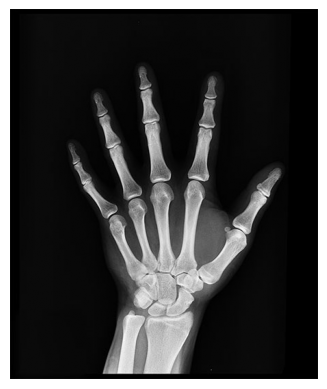

In [9]:
# Load the image
img = mpimg.imread("handxray.jpg")[:, :, 0]

# Display it
plt.imshow(img, cmap='gray')   # `cmap='gray'` for black/white images
plt.axis('off')                # Optional: hide axis ticks
plt.show()

In [12]:
#Padding and Turning Image into an MPS
img_padded = pad_to_next_power_of_two(img.reshape(-1), pad_value=0).astype(float)
imagemps = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(


The MPS of the hand image has 18 tensors and a max bond of 476. I will now see what bond dimension is suitable for compression. The image is of size (541, 450).

### Compressing Image

In [46]:
def compress_image(imagemps: qtn.MatrixProductState,n):
    imagemps10 = imagemps.copy()
    imagemps10.compress(max_bond = n)
    image10data=imagemps10.to_dense()[:len(img.reshape(-1))]
    # Display compressed image
    print("Bond dimension: ",n)
    print("Fideltiy is:" ,(imagemps|imagemps10).contract()**2)
    plt.imshow(image10data.reshape(541, 450), cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
    

Bond dimension:  256
Fideltiy is: 0.9992370026756572


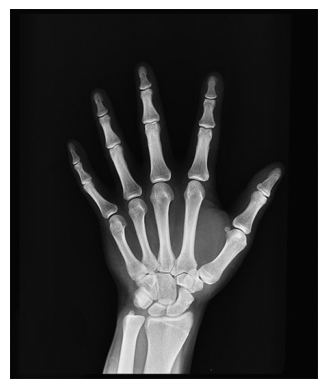

In [41]:
compress_image(imagemps,256)

In [16]:
compress_image(imagemps,32)

NameError: name 'compress_image' is not defined

## Super Basic Test image construction

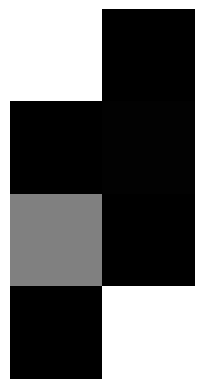

In [124]:
tinydata=np.array([1,0,0,0.01,0.5,0,0,1])
plt.imshow(tinydata.reshape(4, 2), cmap='gray')   # `cmap='gray'` for black/white images
plt.axis('off')                # Optional: hide axis ticks
plt.show()

## Josh's Algorithm + My addition

All of the SCS code is below from unpolished version (Hidden)

In [1]:
import quimb.tensor as qtn
import quimb as qu
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from math import cos, sin, pi
from autoray import do
from scipy.linalg import qr, null_space
from typing import Dict, List, Tuple, Optional
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from collections import Counter
import autoray as ar
import jax.numpy as jnp
from skimage import data
from skimage.transform import resize
from scipy.stats import unitary_group
#import geoopt
#import geotorch
import math
import torch
import torch.nn as nn
from torch.nn.utils import parametrize

from functools import partial

'''This is the contraction method for the tensor networks ie For all future tensor contractions, automatically search for a high-quality contraction path (using a slower but smarter optimizer), so that contractions run efficiently on large networks '''
qtn.set_contract_strategy('auto-hq')

import mps_to_circuit as mtc
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator


''' This allows us to get the information from the qiskit circuit '''
def get_qiskit_gate_info(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for ci in qc.data:                      # ci is a CircuitInstruction
        instr = ci.operation                # was: instr
        qargs = ci.qubits                   # was: qargs
        qubits = [qc.find_bit(q).index for q in qargs]

        try:
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")

    return gates


'''Ensures the indicies of the TN are lrp'''
def ensure_mps_shape_lrp(mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Return a copy of `mps` whose site tensors have a consistent axis order:
      - interior sites: (vL, vR, p)
      - left edge:      (vR, p)
      - right edge:     (vL, p)

    This is the default 'lrp' format used by quimb.
    """
    mps = mps.copy()
    N = mps.L

    for i in range(N):
        T = mps[i]
        p = mps.site_ind(i)
        # all non-physical indices on this site
        virt = [ix for ix in T.inds if ix != p]

        if i == 0:
            # left edge: single virtual = vR
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vR = virt[0]
            T.transpose(vR, p, inplace=True)

        elif i == N - 1:
            # right edge: single virtual = vL
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vL = virt[0]
            T.transpose(vL, p, inplace=True)

        else:
            # interior: two virtuals; identify left vs right by neighbor sharing
            assert len(virt) == 2, f"Site {i} expected 2 virtual legs, found {len(virt)}."
            left_neighbor_inds = set(mps[i - 1].inds)
            right_neighbor_inds = set(mps[i + 1].inds)

            # the bond shared with the left/right neighbor
            vL = next(ix for ix in virt if ix in left_neighbor_inds)
            vR = next(ix for ix in virt if ix in right_neighbor_inds)

            T.transpose(vL, vR, p, inplace=True)

    return mps


'''Make the circuit in qiskit then map to quimb'''
def mps_to_circuit_quimb(mps: qtn.MatrixProductState) -> qtn.Circuit:
    """ Functionality thanks to https://github.com/qiskit-community/mps-to-circuit. MPS must have shape (vL,vR, phys) unless shape is specified. """
    
    psi = ensure_mps_shape_lrp(mps.copy())
    psi.left_canonicalize(inplace=True)

    arrays = [np.asarray(A, dtype=np.complex128) for A in psi.arrays]

    qiskit_qc = mtc.mps_to_circuit(arrays, shape='lrp',method='exact')

    gates_info = get_qiskit_gate_info(qiskit_qc)

    qc = qtn.Circuit(mps.L)
   
    for gate in gates_info:
        name, qubits, U = gate
        qubits.reverse()
        qc.apply_gate(U, *qubits)

    return qc

"""def optimise_to_zero(n: int,eps: float = 1e-2):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    
    to_opt = qc.uni

    targ_qc = qtn.Circuit(n)
    I4 = qu.eye(4)  # two-qubit identity (4×4)
    for i in range(n - 1): targ_qc.apply_gate(I4, i, i + 1, tags=['SU4'])
    targ_uni = targ_qc.uni 

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ_uni},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    #opt_uni = tnopt.optimize_basinhopping(n=600,tol=1e-14,nhop=100)

    params = opt_uni.get_params()

    return params"""


'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_identity(eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(np.eye(4).reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    return params


'''Gives the paramters of a complete unity circuit not just a gate'''
def optimise_to_zero(n: int,eps: float = 1e-2):
    params = optimise_su4_gate_to_identity(eps=eps)[2]
        
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params


'''Gives the parameterised identity circ'''
def near_zero_parametrized_circ_layer(n: int, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised near-identity """

    #params = optimise_to_zero(n)
    params = GLOBAL_IDENTITY_LAYER_PARAMS ###--what is this????
    qc = qtn.Circuit(n)
    #for idx in range(n-1):
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc

'''Using the optimised identity params this becomes an idenity circuit layer'''
def parametrized_circ_layer(n: int, params: np.ndarray, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised with params. """
    qc = qtn.Circuit(n)
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc


'''Computes the Schmidt coefficients (or their squares, i.e. entanglement spectrum) for a bipartition of a quantum state, given the left and right Gram matrices'''
'''def schmidt_from_gram(L,R,square: bool = True, cut_zeros: bool = True) -> torch.Tensor:
    L = (L + L.conj().T) / 2
    R = (R + R.conj().T) / 2

    # 2) eigensqrt of L
    w, U = torch.linalg.eigh(L)
    w = torch.clip(w, 0, None)
    Lh = (U * torch.sqrt(w)[None, :]) @ U.conj().T

    # 3) build A and solve
    A = Lh @ R @ Lh
    A = (A + A.conj().T) / 2
    mu = torch.linalg.eigvalsh(A)
    mu = torch.clip(mu.real, 0, None)

    # Schmidt coefficients
    s = torch.sqrt(mu).flip(0)

    if square:
        s = s**2

    if cut_zeros:
        s = s[s > 1e-14]
        
    return s'''
import torch
from typing import Tuple, Optional

def schmidt_from_gram(
    L: torch.Tensor,
    R: torch.Tensor,
    square: bool = True,
    cut_zeros: bool = True,
    *,
    eps_abs: float = 1e-16,
    eps_rel: float = 1e-12,
    cond_limit: float = 1e10,
    jitter: float = 1e-8,
    return_info: bool = False,
) -> torch.Tensor:
    """
    Compute Schmidt coefficients from Gram matrices L, R in a numerically robust way.

    L, R: (..., N, N) complex or real tensors. Supports batching.
    eps_abs: absolute minimum eigenvalue (very tiny floor).
    eps_rel: relative floor as a fraction of the max eigenvalue per matrix.
    cond_limit: maximum allowed condition number ~ max_eig / min_allowed_eig.
                If cond_limit is finite, min_allowed_eig = max(max_eig/cond_limit, eps_rel*max_eig, eps_abs)
    jitter: extra additive jitter to the diagonal (useful to force PD for cholesky; typically 0).
    return_info: if True returns (s, info_dict) where info_dict contains diagnostics.

    Returns:
      s: Schmidt coefficients (descending), optionally squared if square=True and filtered if cut_zeros=True.
    """
    # 0) basic checks and symmetrize
    if L.shape[-2] != L.shape[-1] or R.shape[-2] != R.shape[-1]:
        raise ValueError("L and R must be square matrices (..., N, N).")
    if L.shape[-2] != R.shape[-2]:
        raise ValueError("L and R must be same size.")
    if not torch.isfinite(L).all() or not torch.isfinite(R).all():
        raise ValueError("L or R contains NaN/Inf.")
    
    # Hermitize (works for complex data too)
    herm = lambda X: (X + X.conj().transpose(-2, -1)) / 2
    L = herm(L)
    R = herm(R)

    # Optionally add tiny jitter first (keeps reconstruction stable)
    if jitter > 0:
        N = L.shape[-1]
        eye = torch.eye(N, device=L.device, dtype=L.dtype)
        L = L + jitter * eye

    # eigendecompose L
    # PREVIOUS 06/11
    '''w, U = torch.linalg.eigh(L)   # w: (..., N) ascending order by torch convention

    # diagnostics
    max_w = w.amax(dim=-1, keepdim=True)   # (..., 1)
    max_w_safe = torch.clamp(max_w, min=1e-30)  # avoid divide-by-zero
    # compute allowed minimum eigenvalue per matrix (batched)
    min_allowed = torch.maximum(
        torch.full_like(max_w_safe, eps_abs),
        torch.maximum(eps_rel * max_w_safe, max_w_safe / cond_limit)
    )  # (..., 1)

    # clamp eigenvalues (relative threshold)
    w_clamped = torch.clamp(w, min=min_allowed.squeeze(-1))

    # optional info
    num_clamped = (w < w_clamped).to(torch.int64).sum(dim=-1)  # count per batch
    frac_clamped = num_clamped.to(torch.get_default_dtype()) / w.shape[-1]

    # build sqrt(L) = U diag(sqrt(w_clamped)) U^†
    sqrt_w = torch.sqrt(w_clamped)
    # broadcasting: (.., N) -> (.., 1, N) for left-multiplication on U
    Lh = (U * sqrt_w.unsqueeze(-2)) @ U.conj().transpose(-2, -1)


    # construct A and symmetrize
    A = Lh @ R @ Lh
    A = herm(A)'''

    # ----- NEW: Cholesky-based "square root" (no eigenvectors; phase-safe) -----
    # We already hermitized L above and added optional jitter.
    # Make sure L is PD enough for Cholesky by adapting jitter if needed.
    def chol_with_adaptive_jitter(M: torch.Tensor, base_jitter: float):
        N = M.shape[-1]
        eye = torch.eye(N, device=M.device, dtype=M.dtype)
        jitter = base_jitter
        for _ in range(6):  # try a few times, up to ~1e-6 if starting at 1e-12
            try:
                return torch.linalg.cholesky(M + (jitter * eye)), jitter
            except RuntimeError:
                jitter = max(jitter * 10.0, 1e-12) if jitter > 0 else 1e-12
        # final attempt with cholesky_ex to get info
        C, info = torch.linalg.cholesky_ex(M + (jitter * eye))
        if (info > 0).any():
            raise RuntimeError("Cholesky failed: L not PD even after jitter.")
        return C, jitter

    C, used_jitter = chol_with_adaptive_jitter(L, jitter)

    # Build A = C^H R C (Hermitian if R is Hermitian); this is
    # unitarily similar to L^{1/2} R L^{1/2} so it has the same eigenvalues.
    A = C.conj().transpose(-2, -1) @ R @ C
    A = (A + A.conj().transpose(-2, -1)) / 2  # re-hermitize numerically

    # eigenvalues of A (real, ascending)
    mu = torch.linalg.eigvalsh(A)
    # numerical safety: clamp small negatives to zero
    mu = torch.clip(mu.real, 0.0, None)

    # Schmidt coefficients: sqrt(mu) in descending order
    s = torch.sqrt(mu).flip(-1)

    if square:
        s = s**2

    if cut_zeros:
        # flatten last dimension and cut tiny entries
        # we'll return per-batch concatenated tensors, so handle batch case by converting to list
        out_list = []
        if s.ndim == 1:
            out_list = [s[s > 1e-14]]
        else:
            # batch handling: return a list of 1D tensors (one per batch)
            # but to keep same return type as before (tensor) we'll concatenate if batch size == 1,
            # otherwise return list if multiple batches (safer).
            batch_shape = s.shape[:-1]
            s_reshaped = s.reshape(-1, s.shape[-1])  # (B, N)
            for row in s_reshaped:
                out_list.append(row[row > 1e-14])
            if s_reshaped.shape[0] == 1:
                s = out_list[0]
            else:
                # when multiple batches present, return a list of tensors (doable) or pad to rectangular array.
                # Here we return a list for explicitness.
                if return_info:
                    info = {
                        "num_clamped": num_clamped,
                        "frac_clamped": frac_clamped,
                        "w_max": max_w.squeeze(-1),
                        "min_allowed": min_allowed.squeeze(-1),
                    }
                    return out_list, info
                return out_list

    if return_info:
        info = {
            "num_clamped": num_clamped,
            "frac_clamped": frac_clamped,
            "w_max": max_w.squeeze(-1),
            "min_allowed": min_allowed.squeeze(-1),
        }
        return s, info

    return s


'''Contruct the left and right contracted tensors so we are only looking at the required bypartition'''
def construct_L_R_Gram_matrices(tn: qtn.TensorNetwork, ind: str, *, device=None, dtype=None) -> qtn.TensorNetwork:
    """ Construct L_a,a' and R_a,a' Gram matrices. """
    ket = tn.copy()
    bra = ket.copy().conj()
    bra.reindex_({i: i + '_bra' for i in bra._inner_inds})

    comb = (bra|ket)

    #Find relevant tags of border tensors
    tidL, tidR = comb.ind_map[ind]
    L_tag = [tag for tag in comb.tensor_map[tidL].tags if tag.startswith('I')]
    R_tag = [tag for tag in comb.tensor_map[tidR].tags if tag.startswith('I')]
    if len(L_tag)!=1 or len(R_tag)!=1:
        print(comb)
        print(L_tag)
        print(R_tag)
    assert len(L_tag)==1 and len(R_tag)==1, "Tensors in combined TN should have unique identifying tag"
    L_tag = L_tag[0]
    R_tag = R_tag[0]

    L_tag_id = int(str(L_tag[1:]))
    R_tag_id = int(str(R_tag[1:]))

    L_tag = f'I{min(L_tag_id,R_tag_id)}'
    R_tag = f'I{max(L_tag_id,R_tag_id)}'
    assert R_tag_id > L_tag_id, "Right border unique tag should be greater than the left border unique tag"

    L_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])<=L_tag_id]
            
    R_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])>=R_tag_id]
    
    #Form subnetworks and contract
    L_subnetwork = comb.select(L_tags,which='any')
    R_subnetwork = comb.select(R_tags,which='any')

    output_inds = (ind, ind+'_bra')
    L_contracted = L_subnetwork.contract(all,output_inds=output_inds,backend='torch')
    R_contracted = R_subnetwork.contract(all,output_inds=output_inds,backend='torch')

    L_mat = L_contracted.data
    R_mat = R_contracted.data

    return L_mat, R_mat


'''Cumulated the above two functions as to find the scmidt coeffs'''
'''def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    s = schmidt_from_gram(L_mat,R_mat)
    return s'''

def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    # 2) Compute Schmidt coefficients using safe numerical parameters
    s = schmidt_from_gram(
        L_mat,
        R_mat,
        square=True,
        cut_zeros=True,
        eps_abs=1e-16,     # absolute floor
        eps_rel=1e-12,     # relative floor
        cond_limit=1e10,   # cap condition number
        jitter=1e-12,      # tiny diagonal regularization
        return_info=False, # only return s
    )
    return s



'''Is the code to apply the circuit to the mps ie does the contractions'''
def apply_single_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState, gauge: bool = False) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    for t in new:
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))

    if gauge:
        new.gauge_all(method='simple',inplace=True)
    
    """to_split = new.tensors[-1]
    num_phys = [i for i in to_split.inds if i.startswith('b')]
    if len(num_phys)>1:
        left_phys_idx = new.L-2
        virt = [i for i in to_split.inds if not i.startswith('b')][0]
        TL,TR = to_split.split(
            left_inds=(f'b{left_phys_idx}',virt),
            right_inds=(f'b{left_phys_idx+1}'),
            method='svd',
            absorb='both'
        )

        TL.add_tag(f"I{left_phys_idx}")
        TR.drop_tags()
        TR.add_tag(f"I{left_phys_idx+1}")
        new = qtn.TensorNetwork([new.tensors[:-1],TL,TR])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)"""

    return new
    #return ensure_mps_shape_lrp(new)

'''This is the same functinality as the above but might do it in a slightly differnt way'''
def apply_single_layer_to_mps(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    bL = f'b{mps.L-2}'
    bR = f'b{mps.L-1}'
    T = next(T for T in new.tensors if bL in T.inds and bR in T.inds)
    virt, = [ind for ind in T.inds if ind not in (bL,bR)]
    
    kept = []
    for t in new:
        if bL not in t.inds and bR not in t.inds:
            kept.append(t)
    
    TL,TR = T.split(
        left_inds=(bL,virt),
        right_inds=(bR,),
        method='svd',
        absorb='right'
    )
    
    ordered_list = []
    idx = 0
    while idx < mps.L:
        for t in kept+[TL,TR]:
            for ind in t.inds:
                if ind[0]=='b':
                    id = int(ind[1:])
                    if idx == id:
                        ordered_list.append(t)
                        break
        idx+=1

    new = qtn.TensorNetwork(ordered_list)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    
    for idx,t in enumerate(new):
        t.modify(tags=(f"I{idx}"))        
        if t.ndim==3:
            if f'k{new.L-2}' in t.inds:
                a,b,c = t.inds
                new_ind_ordering = (b,c,a)
                t.transpose(*new_ind_ordering, inplace=True)
            else:
                a,b,c = t.inds
                new_ind_ordering = (c,b,a)
                t.transpose(*new_ind_ordering, inplace=True)

    return new

def ordered_mps(tn: qtn.MatrixProductState):
    tn = tn.copy()
    tensors = []
    num_added = 0
    while num_added < tn.L:
        for t in tn:
            if f'k{num_added}' in t.inds:
                tensors.append(t)
                num_added+=1
                if f'k{num_added}' in t.inds:
                    num_added+=1
                break
    new = qtn.TensorNetwork(tensors)
    new.view_as(qtn.MatrixProductState, inplace=True, L=tn.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    return new


'''This applies the adjoint of the circuit we give to the mps'''
def apply_single_layer_to_mps(circ_tn: qtn.Circuit, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """ 
    
    Contract a circuit layer MPO with an MPS, reshaping it into an MPS form.

    Provide the circuit for which the adjoint is applied.
    
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    #circ_tn.reindex({f'b{x}': f't{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f'k{x}': f'b{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f't{x}': f'k{x}' for x in range(mps.L)},inplace=True)

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)
    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)

    if new.max_bond()==1:
        return new
    
    new.full_simplify(seq='ADCR',atol=0.0,inplace=True)
    
    new = ordered_mps(new)
    
    current_idx = 0
    last_tensor_inds = ()
    while current_idx < new.L:
        T = new.tensors[current_idx].copy()

        phys_inds = np.array([i for i in T.inds if i[0]=='k'])

        if len(phys_inds) == 1:
            last_tensor_inds = T.inds
            current_idx+=1 
            continue

        current_phys = f'k{current_idx}'
        left_inds = [i for i in T.inds if i in last_tensor_inds]
        left_inds = tuple(left_inds + [current_phys])

        if current_idx == mps.L-2:
            left_inds = tuple([i for i in T.inds if i != f'k{current_idx+1}'])
        
        right_inds = tuple([i for i in T.inds if i not in left_inds])
        
        #print(f'current phys = {current_phys}. left inds = {left_inds}. right inds = {right_inds}. All inds = {T.inds}. Prev inds = {last_tensor_inds}.')
        TL,TR = qtn.tensor_split(T, left_inds=left_inds, method='svd', absorb='left', cutoff=1e-14)

        new = qtn.TensorNetwork(new.tensors[:current_idx] + (TL,TR) + new.tensors[current_idx+1:])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
                
        last_tensor_inds = left_inds
        current_idx+=1

    for t in new:
        for i in t.inds:
            if i[0]=='k':
                idx = i[1:]
        t.modify(tags = {f'I{idx}'})

    new.compress(cutoff=1e-16)
    new.left_canonicalize(inplace=True)

    new_inds = (new.tensors[-1].inds[1],new.tensors[-1].inds[0])
    new.tensors[-1].transpose(*new_inds,inplace=True)
    new = ensure_mps_shape_lrp(new)

    return new


'''THis functions shows the fidelity of a chi = bond approximation of the MPS'''
def test_bond_accuracy(tn,bond):
    tn = tn.copy()
    x = tn.copy()
    x.compress(max_bond=bond)
    x/=x.norm()
    return abs((x.conj() | (tn / tn.norm())).contract(all))**2


'''ALLL BELOW ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''This function defines the loss function for the optimisation of layers, op = circuit, intit_tn = intial mps'''
'''def torch_schmidt_loss_fn(op: qtn.TensorNetwork, init_tn: qtn.MatrixProductState, target_bond_dim: int = 1, gamma: float = 4.0, alpha: float = 0.2) -> torch.Tensor:
    """
    C(lambda) = sum(w_i*lambda_i) + alpha (1 - sum(lambda_i^2)) + beta * RELU(m - (lambda_D - lambda_(D+1))) = tail mass + alpha*linear entropy + beta*gap penalty. w_i = (i-D)^gamma. D = target_bond_dim.
    """
    init_tn = init_tn.copy()
    op = op.copy()
    #op.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)#here we contact the mps with the circuit
    
    vals = []
    for ind in new_tn.inner_inds():
        schmidt_coeffs = schmidt_coeffs_from_ind(new_tn,ind)

        tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
        idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
        weights = idx**gamma

        C_tail_mass = (weights * tail).sum()
        #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

        loss = C_tail_mass #+ alpha*C_lin_entropy
        vals.append(loss)

    vals = torch.stack(vals)

    return vals.sum()'''

'''This is the entanglement as the loss function'''
'''def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = torch.finfo(torch.float64).tiny  # ~2e-308
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0
        p = p / (p.sum() + eps)                                        # normalize
        Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0:
            Tj = 1.0 - (p[0] + p[1] + p[2] + p[3]) ###FIND ME HERE #Immediate compressibility proxy
            Cj = (1.0-g)*Sj + g*Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum() 

import math'''

def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = 1e-12
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0, p_i =  λ_i^2
        
        d = p.numel()
        if d== 0:
            continue
        p = torch.clamp(p, min=0.0)

        p = p / p.sum()

        # --- Entropy (use change-of-base to avoid log2 instability under AMP) ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        
        #ADDED NORMALISATION
        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max #normalise in [0,1] 

        #Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0: #1-(p_1^2+p_2^2) 
            #print(len(p))
            #print(p.numel())
            topk = min(2, p.numel())
            Tj = 1.0 - p.narrow(0, 0, topk).sum()
            Cj = (1.0 - g) * Sj + g * Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum()

def new_torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.5,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-parameter loss aligned with final chi=2 fidelity.

    For each internal bond, let p be the normalised Schmidt probabilities
    (lambda^2 / sum lambda^2), sorted in descending order.

      T_j      = 1 - (p_1 + p_2)                   # tail mass (chi=2 infidelity)
      r_i      = p_i / T_j for i >= 3             # tail distribution (if T_j > 0)
      H_tail   = -sum_{i>=3} r_i log2 r_i         # entropy of tail
      H_tail_n = H_tail / log2(d_tail) in [0,1]   # d_tail = len(tail), if >= 2

    Per-cut cost:
      C_j(g) = T_j * (1 + g * H_tail_n)

    - T_j drives you towards high chi=2 fidelity.
    - H_tail_n only cares about *how messy the tail is*.
    - g in [0,1] controls how much you value "cleaning up / structuring the tail"
      vs purely greedy chi=2.

    When T_j -> 0, C_j -> 0 regardless of H_tail_n, so late stages are effectively greedy.
    """
    # clamp g to [0, 1]
    #g = float(max(0.0, min(1.0, g)))

    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ^2 already
        lam2 = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if lam2.numel() == 0:
            continue

        lam2 = torch.clamp(lam2, min=0.0)
        Z = lam2.sum()
        if Z <= eps:
            continue

        p = lam2 / Z  # probabilities

        # sort so top entries are really the largest
        p_sorted, _ = torch.sort(p, descending=True)
        d = p_sorted.numel()

        if d <= 2:
            # no tail -> already rank<=2 across this cut
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        # chi=2 tail mass
        topk = 2
        Tj = 1.0 - p_sorted[:topk].sum()

        if Tj <= eps:
            # effectively no tail, cost ~ 0
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        tail = p_sorted[topk:]          # shape (d_tail,)
        d_tail = tail.numel()

        if d_tail <= 1:
            # a single tail mode still present: no entropy structure
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            # tail distribution r_i = p_i / T_j
            r = tail / Tj
            r = torch.clamp(r, min=eps)

            H_tail = - (r * (r.log() / math.log(2.0))).sum()
            H_max = math.log2(d_tail)
            H_tail_norm = H_tail / H_max

        # multiplicative planning: penalise large & messy tails
        Cj = Tj * (1.0 + g * H_tail_norm)
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    #if np.random.randint(0,200)==0:
    #   print(f'Tj = {Tj}, H_tail_n = {H_tail_norm}, Cj = {Cj}')
    vals = torch.stack(vals)
    return vals.sum()


def loss_renyi2_sum(op, init_tn):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    total = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        total = total - torch.log2((p*p).sum().clamp_min(1e-300))  # Σ_j S2^(j)
    return total

def loss_smoothmax_entropy(op, init_tn, tau=0.1):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        S = -(p * torch.log2(p.clamp_min(1e-12))).sum()
        vals.append(S)
    vals = torch.stack(vals)
    return tau * torch.logsumexp(vals / tau, dim=0)

def loss_weighted_tail(op, init_tn, D=4, gamma=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    tot = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        tail = p[D:]
        if tail.numel():
            idx = torch.arange(1, tail.numel()+1, dtype=tail.dtype, device=tail.device)
            w = idx**gamma                     # gamma↑ => weight deeper tail more
            tot = tot + (w * tail).sum()
    return tot

def loss_effective_rank(op, init_tn, target_R=None, beta=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        R = 1.0 / (p*p).sum().clamp_min(1e-300)
        vals.append(torch.log2(R))  # ≡ S2
        if target_R is not None:    # optional hinge to keep R below target
            vals.append(beta * torch.relu(torch.log2(R) - torch.log2(torch.tensor(target_R))))
    return torch.stack(vals).sum()



def cost_from_s(schmidt_coeffs):
    target_bond_dim = 2
    gamma = 4

    tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
    idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
    weights = idx**gamma

    C_tail_mass = (weights * tail).sum()
    #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

    loss = C_tail_mass #+ alpha*C_lin_entropy
    return loss

'''ALLL ABOVE ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''Turns Torch backend to numpy backend'''
def to_numpy(a):
    # Works for both torch and numpy inputs
    if isinstance(a, torch.Tensor):
        return a.detach().cpu().numpy()
    return np.asarray(a)


def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        d = p.numel()
        if d== 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        # Entropy in bits: S_j
        Sj = - (p * (p.log() / math.log(2.0))).sum()

        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max
        vals.append(Sj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()

def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2

    Additionally (for diagnostics), prints the *normalised tail entropy* per cut,
    where the tail is everything beyond the top-2 Schmidt probabilities,
    and also prints a single scalar "new tail entropy term" = sum_j H_tail_n^{(j)}.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    entropies = []
    tail_entropies = []

    for ind in new_tn.inner_inds():
        # p are λ^2 already
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)
        d = p.numel()
        if d == 0:
            continue

        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z  # probabilities

        # --- Net entropy S_j over full spectrum ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        entropies.append(Sj)

        # --- Tail entropy part (for printing only) ---
        # Sort so "top-2" really means largest 2
        p_sorted, _ = torch.sort(p, descending=True)
        d_sorted = p_sorted.numel()

        if d_sorted <= 2:
            # no tail beyond chi=2
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            topk = 2
            Tj = 1.0 - p_sorted[:topk].sum()  # tail mass
            if Tj <= eps:
                H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
            else:
                tail = p_sorted[topk:]
                d_tail = tail.numel()
                if d_tail <= 1:
                    H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
                else:
                    r = tail / Tj  # tail distribution
                    r = torch.clamp(r, min=eps)
                    H_tail = - (r * (r.log() / math.log(2.0))).sum()
                    H_max = math.log2(d_tail)
                    H_tail_norm = H_tail / H_max

        tail_entropies.append(H_tail_norm)

    if not entropies:
        print("No internal bonds found; tail entropy = []")
        return torch.tensor(0.0, dtype=torch.float64)

    entropies = torch.stack(entropies)
    tail_entropies = torch.stack(tail_entropies)

    # --- print the tail entropy diagnostics ---
    print("Tail entropy (normalised) per cut:",
          tail_entropies.detach().cpu().numpy())

    new_tail_entropy_term = tail_entropies.sum().item()
    print("New tail entropy term =", new_tail_entropy_term)

    return entropies.sum()



def torch_schmidt_tail_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    topk: int = 2,
) -> torch.Tensor:
    """
    g = 1 part: sum_j T^{(j)}, where
      T^{(j)} = 1 - sum_{i=1}^{topk} p_i^{(j)},
    with p_i as in the entropy loss.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        k = min(topk, p.numel())
        Tj = 1.0 - p.narrow(0, 0, k).sum()
        vals.append(Tj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()


def torch_schmidt_kl_rank2_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    alpha: float = 1e-3,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-term planning-friendly cost.

    For each internal bond, let p be the normalised Schmidt probabilities.
    Define a smoothed rank-2 target spectrum q:
        q_1 = q_2 = (1 - alpha)/2,
        q_i (i>=3) share total mass = alpha.

    Loss = sum_j D_KL(p^{(j)} || q^{(j)}).

    This consolidates:
      - entropy reduction (concentration of p),
      - tail suppression (penalising mass where q_i is tiny),
    into a single divergence to the 'ideal' chi=2 spectrum.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    # Apply one optimisation layer
    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ_i >= 0  -> convert to probabilities
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        # Numerical hygiene
        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z

        d = p.numel()

        # Build target q
        if d <= 2:
            # If there is no tail, just aim for equal split
            q = torch.full_like(p, 0.5)
        else:
            tail_mass = float(alpha)
            tail_mass = max(min(tail_mass, 0.5), 0.0)  # safety clip

            q_top = (1.0 - tail_mass) / 2.0
            q_tail = tail_mass / float(d - 2)

            q = torch.full_like(p, q_tail)
            q[0] = q_top
            q[1] = q_top

        # Clamp for log stability
        p_safe = torch.clamp(p, min=eps)
        q_safe = torch.clamp(q, min=eps)

        # KL(p || q) in nats (constant factor doesn't matter for optimisation)
        Cj = (p_safe * (p_safe.log() - q_safe.log())).sum()
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)

    vals = torch.stack(vals)
    return vals.sum()


'''THIS IS THE OPTIMISATION for a layer%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%'''
def optimise_circ_layer(init_mps: qtn.TensorNetwork, loss = torch_schmidt_loss_fn, verbose: bool = False, get_best_result: bool = True, gauge_iteratively: bool = False) -> qtn.TensorNetwork:
    init_mps = init_mps.copy()
    #init_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    
    
    circ = near_zero_parametrized_circ_layer(init_mps.L,1e-3)#intitialise our ciruit at identity
    layer = circ.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()

    #new_tn = apply_single_layer(circ_tn=to_opt.copy(), mps=init_mps.copy(), gauge=False)
    #print('new mps outcome:')
    #t1 = new_tn.copy()
    #print(t1.contract(all,output_inds=[f'b{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
    #new_tn.draw(figsize=(15,15))
    #t = new_tn.tensors[-1]
    #t.add_tag("I7")
    """print(new_tn)
    for idx,ind in enumerate(new_tn.inner_inds()):
        print(f'ind: {ind} - {schmidt_coeffs_from_ind(new_tn.copy(),ind)}')
        #if idx < len(new_tn.inner_inds())-3:
        #    print(f'check: {new_tn.copy().schmidt_values(idx+1)}')
        print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(new_tn.copy(),ind))}')"""

    #init_mps.left_canonicalize(inplace=True,normalize=True)

    if verbose:
        with torch.no_grad():
            print(f'initial loss = {loss(to_opt,init_mps)}')

    if get_best_result: #essentially we are looking for the best parameters if this is true
        if verbose:
            print('Ensuring best parameters are retrieved...')

        _best = {"val": None, "params": None}

        with torch.no_grad():
            best_val = loss(to_opt,init_tn=init_mps)
        
        _best["val"] = best_val
        
        '''if this iteration is the best store the parameters and continue returing psi as it was inputted'''
        def get_best(psi):
            #global best_val,best_params
            with torch.no_grad():
                val = loss(psi,init_tn=init_mps)
            if val<_best["val"]:
                tn_np = psi.copy()
                tn_np.apply_to_arrays(to_numpy)
                _best["params"] = tn_np.get_params()
                _best["val"] = val
            return psi
        
        def get_best_fn(psi):
            with torch.no_grad():#Ensures that the operations inside do not track gradients in PyTorch ie does this outside the optimisation
                _ = get_best(psi.copy())#makes a separate copy of the tensor network so the bookkeeping doesn’t alter the main object.

                if gauge_iteratively:#boolean ie renormalsiation for stability
                    psi.gauge_all(method='simple',inplace=True)#a tensor network normalization/gauge-fixing step.“Simple” method ensures numerical stability of MPS contractions.Done inplace, modifying the original
            return psi

        print(f'At init net entropy comp = {torch_schmidt_entropy_loss(to_opt.copy(),init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(to_opt.copy(),init_mps.copy())}')
        #this is the actual optimisation, note using get best we store the params of the best
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            norm_fn=get_best_fn,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    else:
    #here we dont have norm_fn=get_best_fn, so not storing the best parameters
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    #this is the optimised tn
    opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
    x = opt_layer_tn
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))#make sure optimised tn is all torch

    if verbose: #essentially is a boolean to switch on and off the print statements
        with torch.no_grad():
            print(f'final loss = {loss(opt_layer_tn,init_mps)}')

    if get_best_result: #gives the best results ie the best tn layer
        with torch.no_grad():
            print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,init_mps)}')
            best_layer_tn = opt_layer_tn.copy()
            best_layer_tn.set_params(_best["params"])
            best_copy = best_layer_tn.copy()
            best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
            print(f'after updating, final loss = {loss(best_copy,init_mps)}')

            print(f'After opt: net entropy comp = {torch_schmidt_entropy_loss(best_copy,init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(best_copy,init_mps.copy())}')

        return best_layer_tn
    else:
        return opt_layer_tn
    
def find_optimal_chi(schmidts, target_error):
    """
    schmidts: list of 1D arrays of Schmidt coeffs (one per bond)
    target_error: desired upper bound on total discarded weight
    """
    # preprocess: squared, normalised, sorted descending
    spectra = []
    for lam in schmidts:
        lam = np.asarray(lam, dtype=float).ravel()
        lam2 = lam**2
        lam2 /= lam2.sum()
        spectra.append(np.sort(lam2)[::-1])

    max_rank = max(len(s) for s in spectra)

    def global_error(chi):
        # sum of tail weights across all bonds
        err = 0.0
        for lam2 in spectra:
            if chi < len(lam2):
                err += lam2[chi:].sum()
        return err

    lo, hi = 1, max_rank
    while lo < hi:
        mid = (lo + hi) // 2
        if global_error(mid) <= target_error:
            hi = mid
        else:
            lo = mid + 1
    return lo  # minimal chi with error <= target_error

def construct_circ_from_params(param_set,n):
        layers = len(param_set)
        qc = qtn.Circuit(n)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

def reconstruct_circuit(disentangled_mps: qtn.MatrixProductState, param_set: list):
    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    
    circ = construct_circ_from_params(param_set,n=disentangled_mps.L)
    circ_tn = circ.uni.H
    circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'b{x}': f'k{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(disentangled_mps.L)},inplace=True)
    
    full_circ_tn = circ_tn | final_state.copy()
    
    return full_circ_tn

def test_circuit_fidelity(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list):
    targ_mps = targ_mps.copy()
    targ_mps /= targ_mps.norm()
    disentangled_mps = disentangled_mps.copy()

    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    disentangled_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    full_circ_tn = reconstruct_circuit(disentangled_mps, param_set)
    full_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    full_circ_tn /= full_circ_tn.norm()

    fidelity = np.abs((full_circ_tn.conj() | targ_mps).contract(all))**2
    return fidelity

    '''Collects the above but does it automatically for as many alyers as we need'''
def optimise_sequential_layers(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5, adaptive_bond_reduction: bool = False, max_truncation_error: bool = 1e-6) -> tuple:
    targ_mps = targ_mps.copy()
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

    bond2 = [test_bond_accuracy(targ_mps,2)]
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')

        current_mps.gauge_all(method='simple',inplace=True)

        """print(current_mps)
        t1 = current_mps.copy()
        #print(t1.contract(all,output_inds=[f'k{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
        costs = 0
        for ind in current_mps.inner_inds():
            print(f'ind: {ind} - {schmidt_coeffs_from_ind(current_mps.copy(),ind)}')
            print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))}')
            costs+=cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))
        print(f'total cost = {costs}')"""
        if g_vals:
            if use_new_cost:
                loss = partial(new_torch_schmidt_loss_fn, g=g_vals[L])
            else:
                loss = partial(torch_schmidt_loss_fn, g=g_vals[L]) #HERE EDIT
            #loss = partial(torch_schmidt_kl_rank2_loss, alpha=g_vals[L])

        #This is THE optimising step, it gets initialised atidenty the nloss function is minimised.
        opt_layer_tn = optimise_circ_layer(current_mps,loss=loss,verbose=verbose)

        param_set.append(opt_layer_tn.get_params())
        uni_layers.append(opt_layer_tn)

        opt_layer_copy = opt_layer_tn.copy()
        opt_layer_copy.apply_to_arrays(lambda x: torch.as_tensor(x))

        #if verbose: print(f'double checking final loss = {loss(opt_layer_copy,current_mps.copy())}')

        new_mps = apply_single_layer_to_mps(opt_layer_copy,current_mps)
        
        '''if verbose:
            print(f'Testing true fidelity from circuit reconstruction...')
            targ = targ_mps.copy()
            disentangled_state = new_mps.copy()
            targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            disentangled_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            fidelity = test_circuit_fidelity(targ, new_mps, param_set)
            print(f'True fidelity after reconstruction = {fidelity}')'''
            
        """for ind in new_mps.inner_inds():
            print(f'ind: {schmidt_coeffs_from_ind(new_mps.copy(),ind)}')
            print(f'ind: {cost_from_s(schmidt_coeffs_from_ind(new_mps.copy(),ind))}')"""

        #new_mps.gauge_all(method='simple',inplace=True)
        max_bond_before = new_mps.max_bond()
        if adaptive_bond_reduction:
            schmidts = []
            copy = new_mps.copy()
            for ind in copy.inner_inds():
                p = schmidt_coeffs_from_ind(copy, ind)
                p_np = p.detach().cpu().numpy()
                schmidts.append(p_np)
            opt_chi = find_optimal_chi(schmidts, max_truncation_error)
        
            new_mps.compress(max_bond=opt_chi)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff adaptively chosen to give chi={opt_chi}')
        else:
            new_mps.compress(cutoff=sv_cutoff)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff = {sv_cutoff}')
        new_mps/=new_mps.norm()

        print(f' new max bond = {new_mps.max_bond()}')
        
        current_mps = new_mps.copy()
        test = current_mps.copy()
        if verbose:
            print(f'norm = {test.norm()}')
            mid_idx = int(test.L//2)
            ind = test.inner_inds()[mid_idx]
            #print(f'Central schmidt coefficients = {test.schmidt_values(mid_idx+1)}')
            print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(test,ind)}')
            #print(f'Central purity (renyi-2 anti-entropy) = {torch.sum(schmidt_coeffs_from_ind(test,ind))**2}') #np.sum(test.copy().schmidt_values(mid_idx+1)**2)}')
            print(f' bond 2 = {test_bond_accuracy(test,2)}')
            print(f' bond 4 = {test_bond_accuracy(test,4)}')
            print(f' bond 6 = {test_bond_accuracy(test,6)}')

            print(f'optimising for chi=2 approx:')
            current_state = qtn.MPS_computational_state('0'*new_mps.max_bond())
            current_state/=current_state.norm()

            def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
                psi = psi.copy() | current_state.copy()
                #psi.draw()
                ov   = psi.overlap(targ,backend='torch')            
                npsi = psi.norm(squared=True,backend='torch').real       
                ntar = targ.norm(squared=True,backend='torch').real
                #print(ov, npsi, ntar)
                #ov = (targ.copy().conj() | psi | current_state.copy())
                return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

            to_opt = near_zero_parametrized_circ_layer(n=new_mps.L, eps = 1e-2)
            to_opt = to_opt.uni

            to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
            x = test.copy()
            x.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

            x.reindex({f'k{x}': f'b{x}' for x in range(x.L)},inplace=True)

            tnopt = qtn.TNOptimizer(
                to_opt,
                torch_infidelity,
                #norm_fn=get_best_fn,
                loss_constants={'targ': x.copy(), 'current_state': current_state.copy()},
                tags=['SU4'],
                optimizer='l-bfgs-b',
                autodiff_backend='torch',
                progbar=True,
            )

            opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
            opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

            #current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
            #current_state.gauge_all(method='simple',inplace=True)
            #current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)

            #print(f'best chi2 fidelity after opt = {np.abs((current_state.copy().conj()/current_state.norm() | x.copy()/x.norm()).contract(all))**2}')

        bond2.append(test_bond_accuracy(test,2))
        mps_states.append(current_mps)

        if early_kill_fidelity_thresh:# if fidelity is good then we kill process
            if L==early_kill_layer_num:
                if(test_bond_accuracy(test,2)<early_kill_fidelity_thresh):
                    return mps_states,param_set,bond2

    #print(f' bond 2 = {test_bond_accuracy(current_mps.copy(),2)}')
    return mps_states,param_set,bond2

def subsequent_fid_opt(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5):
    ''' layer by layer (identity-initialised) fidelity maximisation -- to replace with MPD warm-start initialisation'''
    targ_mps = targ_mps.copy()
    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.left_canonicalize(inplace=True,normalize=True)
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    def chi_upper_bound_from_schmidts(mps, chi):
        bounds = []
        for j in range(1, mps.L):  # cuts between sites
            lam = mps.schmidt_values(j)  # assumes mps is normalized
            lam2 = np.sort(np.asarray(lam)**2)[::-1]
            bounds.append(lam2[:chi].sum())
        return min(bounds), np.array(bounds)
    
    print(chi_upper_bound_from_schmidts(targ_mps.copy(),2))
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print('doing subsequent fidelity maximising')
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

        targ_mps.gauge_all(method='simple',inplace=True)
        t = targ_mps.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')


    bond2 = [test_bond_accuracy(targ_mps,2)]

    current_state = qtn.MPS_computational_state('0'*targ_mps.L)
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = psi | current_state
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')
        
        current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

        current_state.reindex({f'b{x}': f'k{x}' for x in range(current_state.L)},inplace=True)
        current_state/=current_state.norm()

        to_opt = near_zero_parametrized_circ_layer(n=targ_mps.L, eps = 1e-2)
        to_opt = to_opt.uni

        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        #targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #print(to_opt.dtype)
        #print(targ_mps.dtype)
        #print(targ_mps.dtype)
        #test = (to_opt | current_state)
        #test.draw(figsize=(10,10))

        #targ_mps.draw(figsize=(10,10))
        print(f'init = {torch_infidelity(to_opt.copy(),targ_mps.copy(),current_state.copy())}')
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            #norm_fn=get_best_fn,
            loss_constants={'targ': targ_mps.copy(), 'current_state': current_state.copy()},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
        #print(opt_layer_tn.get_params())
        opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

        current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
        #current_state.gauge_all(method='simple',inplace=True)
        current_state.right_canonicalize(inplace=True,normalize=True)
        current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)
        #print(current_state.norm())
        #print(targ_mps.norm())
        if verbose:
            print(f'fidelity after layer {L} = {np.abs((current_state.copy().conj()/current_state.norm() | targ_mps.copy()/targ_mps.norm()).contract(all))**2}')

        t = current_state.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | current_state.copy()).contract(all))**2}')

        #t = targ_mps.copy()
        #t.compress(max_bond=2)
        #t/=t.norm()
        #print(f'chi2 fid of targ = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')

        print(f'new max bond = {current_state.max_bond()}')
        #print(current_state)
        mid_idx = int(current_state.L//2)
        ind = current_state.inner_inds()[mid_idx]
        print(f'2. Central schmidt coefficients of updated state = {schmidt_coeffs_from_ind(current_state.copy(),ind)}')
        
    return None

'''Convert a Matrix Product State into a sequence of trainable 2-qubit SU(4) gates'''#WHY????
def mps_to_su4_layer_params(mps: qtn.MatrixProductState):
    mps_copy = mps.copy()
    n = mps_copy.L

    param_set = []

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        #psi = uni | zero
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    circ = mps_to_circuit_quimb(mps_copy)

    for gate_idx in range(n-1):
        gate_tensor = circ.uni.select(f"GATE_{gate_idx}").tensors[0].copy()
        ### NEED TO CHECK GATE INDEX ORDERING HERE...
        gate_tensor.modify(inds=('k0','k1','b0','b1'),inplace=True)
        qc = qtn.Circuit(2,gate_contract=False)
        qc.apply_gate("SU4",*(1e-2*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)#makes random gates with parameters

        to_opt = qc.uni
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            loss_constants={'targ': gate_tensor},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_uni = tnopt.optimize(n=600,tol=1e-14)
        params = opt_uni.get_params()
        param_set.append(params)

    return param_set

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params

def global_optimise(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False, optimise_final_layer: bool = False):
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    #final_state.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    def loss(uni: qtn.TensorNetwork, targ: qtn.TensorNetwork, final_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = uni | final_state.copy()
        ov   = psi.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = psi.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    

    '''These getbest functions are the same as the single layer optimisation'''
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy,final_state=final_state.copy())
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
        return psi
    
    """if optimise_final_layer:
        param_dict = mps_to_su4_layer_params(final_state)
        for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                if len(p)==15:
                    p = np.asarray(p, dtype=float).reshape(15)
                    qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)"""

    #make layers
    def construct_circ(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc
    
    circ = construct_circ(param_set)
    to_opt = circ.uni.H
    to_opt.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))

    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        print('Drawing circuit...')
        circ.draw(figsize=(12,12))

    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    for t in to_opt:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Initial tensors are not unitary!"

    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy,'final_state': final_state.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    #opt_layer_tn = tnopt.optimize_basinhopping(n=300,tol=1e-14,lr=0.5,nhop=2)
    opt_layer_tn = tnopt.optimize(n=600,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy,final_state=final_state.copy())}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy,final_state=final_state.copy())}')

    for t in best_copy:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Final tensors are not unitary!"
    
    return best_layer_tn

# save.py
import pickle, gzip, sys, datetime


'''Converts any PyTorch tensor to a CPU tensor detached from autograd.

Why?

Ensures saved tensors don’t carry GPU context or gradient history.

Makes them loadable on any machine, even without GPU.'''
def save_run(path, mps_states, param_set, fids):
    # (optional) move any tensors to CPU so loading works anywhere
    def _to_cpu(x):
        return x.detach().cpu() if isinstance(x, torch.Tensor) else x

    mps_cpu = []
    for m in mps_states:
        try:
            m = m.copy().apply_to_arrays(_to_cpu)  # works for quimb TNs
        except Exception:
            pass
        mps_cpu.append(m)

    bundle = {
        "mps_states": mps_cpu,
        "param_set": param_set,
        "fids": fids,
        "meta": {
            "saved_at": datetime.datetime.now().isoformat(),
            "python": sys.version.split()[0],
            "torch": getattr(torch, "__version__", None),
            "quimb": getattr(qu, "__version__", None),
        },
    }
    with gzip.open(path, "wb") as f:
        pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)


'''Opens a compressed pickle file.

Loads the saved MPS states, parameters, fidelities, and metadata.

Returns them as separate variables ready to use.'''
def load_run(path):
    with gzip.open(path, "rb") as f:
        bundle = pickle.load(f)
    return bundle["mps_states"], bundle["param_set"], bundle["fids"], bundle.get("meta", {})

'''Returns a list of N dictionaries, each mapping gate indices to small random 15-element arrays.

Typical use: initializing tensor network gate parameters before global optimization. ie essentially makes sure the paramtetrs are small for global opt'''
def near_zero_param_dict(n: int, N:int, eps: float = 1e-3, seed: int | None = None, dtype=float) -> dict[int, np.ndarray]:
    """
    Return {i: near-zero np.array(shape=(15,))} for i in 0..n-1.
    Values are sampled uniformly from [-eps, eps].
    To use for the generation of empty params for global opt.
    """
    rng = np.random.default_rng(seed)
    param_set = []
    for j in range(N):
        param_set.append({i: rng.uniform(-eps, eps, 15) for i in range(n-1)})
    return param_set


'''specific state simulation ie common example'''
def generate_haar_random_mps(n: int, num_layers: int, *, seed: int = None):
    """Generate an MPS by stacking `num_layers` of nearest-neighbour Haar-random two-qubit unitaries."""

    if seed is not None:
        qu.gen.rand.seed_rand(seed)

    mps_state = qtn.MPS_computational_state('0' * n)

    for _ in range(num_layers):
        qc = qtn.Circuit(n, gate_contract=False)
        for idx in range(n - 1):
            U = qu.rand_uni(4)  # Haar on U(4); global phase vs SU(4) is irrelevant
            qc.apply_gate(U, idx, idx + 1, tags=["SU4"])
        circ_tn = qc.uni
        mps_state = apply_single_layer_to_mps(circ_tn, mps_state)

    return mps_state

def lrp_to_lpr(final_state):
    for i in range(final_state.L):
        if i == 0:
            inds = final_state.tensors[i].inds
            bond, phys = inds[0], inds[1]
            final_state.tensors[i].transpose(phys,bond,inplace = True)
        if i!=0 and i!=final_state.L-1:
            inds = final_state.tensors[i].inds
            bond1,bond2, phys = inds[0], inds[1], inds[2]
            final_state.tensors[i].transpose(bond1,phys,bond2,inplace = True)
    return final_state

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)

    params = opt_uni.get_params()

    ### simple check that we created the right unitary 
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params
import numpy as np
import quimb.tensor as qtn


def _complete_to_unitary(M, tol=1e-12):
    """
    Complete a partial 4x4 isometry (some columns possibly zero)
    to a full 4x4 unitary by Gram–Schmidt, keeping existing
    non-zero columns fixed (up to normalization).
    """
    M = np.asarray(M, dtype=complex)
    d, d2 = M.shape
    assert d == 4 and d2 == 4

    cols = []
    filled = []
    # normalize non-zero columns, leave zeros marked
    for j in range(4):
        col = M[:, j]
        n = np.linalg.norm(col)
        if n > tol:
            cols.append(col / n)
            filled.append(True)
        else:
            cols.append(None)
            filled.append(False)

    # existing orthonormal basis (assume input isometry so already orthogonal)
    basis = [c for c in cols if c is not None]

    rng = np.random.default_rng()
    # add extra basis vectors until we span C^4
    while len(basis) < 4:
        v = rng.normal(size=4) + 1j * rng.normal(size=4)
        for b in basis:
            v -= np.vdot(b, v) * b
        n = np.linalg.norm(v)
        if n < tol:
            continue
        basis.append(v / n)

    # rebuild full unitary, preserving existing columns' directions
    U = np.zeros_like(M, dtype=complex)
    k = 0
    # first assign basis vectors to existing filled columns
    for j in range(4):
        if filled[j]:
            U[:, j] = basis[k]
            k += 1
    # then fill the empty columns
    for j in range(4):
        if not filled[j]:
            U[:, j] = basis[k]
            k += 1

    return U


def embed_tensor_in_SU4(U):
    """
    Embed a tensor U into a 2-qubit SU(4) unitary.

    Conventions:
      - If len(U.inds) == 2 and 'k0' in U.inds:
            boundary tensor with inds (r, p), shape (2, 2)
        -> treated as a map from a 1-d input subspace to (r, p) outputs.
      - If len(U.inds) == 2 and 'k0' not in U.inds:
            boundary tensor with inds (l, p), shape (2, 2)
        -> l is input, p is output; r is fixed (unused).
      - If len(U.inds) == 3:
            bulk tensor with inds (l, r, p), shape (2, 2, 2)
        -> l indices are input; r and p indices are output.

    Returns:
      qtn.Tensor with inds ('k0', 'k1', 'b0', 'b1')
      where ('k0','k1') are input indices and ('b0','b1') are output indices.
    """
    data = np.asarray(U.data, dtype=complex)
    inds = tuple(U.inds)
    rank = len(inds)

    # Matrix M has rows labelled by (b0, b1) and columns by (k0, k1)
    # i  = 2 * b0 + b1  in {0,...,3}
    # j  = 2 * k0 + k1  in {0,...,3}
    M = np.zeros((4, 4), dtype=complex)

    if rank == 2:
        # boundary tensors, shape (2, 2)
        assert data.shape == (2, 2)
        if 'k0' in inds:
            # Left boundary: inds = (r, p)
            # Embed as a single column for |k0=0, k1=0> (j = 0)
            j = 0
            for r in range(2):
                for p in range(2):
                    i = 2 * r + p          # b0 = r, b1 = p
                    M[i, j] = data[r, p]
        else:
            # Right boundary: inds = (l, p)
            # l is input qubit (mapped to k0), k1 is fixed to 0
            for l in range(2):
                j = 2 * l + 0             # k0 = l, k1 = 0
                for p in range(2):
                    i = 2 * 0 + p         # b0 = 0 (no r), b1 = p
                    M[i, j] = data[l, p]

    elif rank == 3:
        # bulk tensor, shape (l, r, p)
        assert data.shape == (2, 2, 2)
        for l in range(2):
            # input index l -> k0; k1 fixed to 0
            j = 2 * l + 0                 # k0 = l, k1 = 0
            for r in range(2):
                for p in range(2):
                    # outputs r, p -> b0, b1
                    i = 2 * r + p         # b0 = r, b1 = p
                    M[i, j] = data[l, r, p]
    else:
        raise ValueError("U must have 2 or 3 indices (boundary or bulk tensor).")

    # Complete to a full 4x4 unitary
    M = _complete_to_unitary(M)

    # Enforce det = 1 to make it SU(4) rather than just U(4)
    det = np.linalg.det(M)
    phase = np.angle(det)
    M *= np.exp(-1j * phase / 4.0)

    # Reshape to rank-4 tensor with inds ('k0', 'k1', 'b0', 'b1')
    # M is indexed as M[b0,b1; k0,k1]; we want T[k0,k1,b0,b1]
    data_su4 = np.transpose(M.reshape(2, 2, 2, 2), (2, 3, 0, 1))

    return qtn.Tensor(
        data=data_su4,
        inds=('k0', 'k1', 'b0', 'b1'),
        tags=getattr(U, "tags", None),
    )


def optimise_su4_to_tensor(U_tensor: qtn.Tensor,eps:float = 1e-2):
    qc = qtn.Circuit(2)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)
    to_opt = qc.uni
    targ = embed_tensor_in_SU4(U_tensor.copy())
    targ.apply_to_arrays(lambda x: torch.as_tensor(x))

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    #to_opt.draw(figsize=(10,10))
    #targ.draw(figsize=(10,10))

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    params = opt_uni.get_params()
    return params

def extract_su4_params_from_unitary(unitarylist):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary))
    return paramlist

'''Gives the paramters of a complete unity circuit not just a gate'''
def combine_layer_params_into_param_dict(paramslst: list, n: int):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        params = paramslst[idx][2]
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params

def reindex_su4_tngen(tn):
    """
    Reindex all SU4 tensors in a TensorNetworkGenOperator according to:
        1->3, 2->4, 3->1, 4->2
    Works IN PLACE and preserves circuit structure.
    """
    tn_new = tn.copy()

    for t in tn_new.tensors:
        # Only modify SU4 gates with 4 legs
        if 'SU4' in t.tags and len(t.inds) == 4:
            i0, i1, i2, i3 = t.inds
            new_order = {
                i0: i2,
                i1: i3,
                i2: i0,
                i3: i1
            }
            t.reindex_(new_order)   # <--- in-place reindex

    return tn_new

def dense_to_exact_mps(full_sv, n):
    full_sv = full_sv / np.linalg.norm(full_sv) 
    exact_mps = qtn.MatrixProductState.from_dense(
        full_sv, 
        dims=[2] * n, 
        cutoff=0.0,
        max_bond=None  # <-- ensures no truncation
    )
    return exact_mps
def exact_to_approx_mps(exact_mps,bond):
    approx_mps = exact_mps.copy()
    approx_mps.compress(max_bond=bond)
    approx_mps.right_canonicalize(normalize=True,inplace=True)
    return approx_mps
def makezeromps(n):
    #try from dense in mps form
    zerovect = np.zeros(2**n)
    zerovect[0] = 1
    zerovect_mps = qtn.MatrixProductState.from_dense(zerovect, dims=[2]*n)
    return zerovect_mps

from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
'''get gate info from qiskit'''
def extract_gates_with_qubits(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for instr, qargs, _ in qc.data:
        # Get the qubits this instruction acts on
        qubits = [qc.find_bit(q).index for q in qargs]
        
        try:
            # Get the unitary matrix of the gate itself
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")
    
    return gates


import quimb.tensor as qtn
'''Make our quimb circuit using gate info'''
def makequimbcirc(n, gates_info):
    """
    Rebuild a Quimb Circuit from gates_info
    gates_info = list of (name, qubits, U)
    n = number of qubits
    """
    qc = qtn.Circuit(n)
    
    for gate in gates_info:
        name, qubits, U = gate
        temp = []
        qubits.reverse()
        qc.apply_gate(U, *qubits)
    
    return qc

def param_dict_from_mps(mps: qtn.MatrixProductState):
    psi = ensure_mps_shape_lrp(mps.copy())
    print(psi)
    param_list = []
    for T in psi.tensors:
        params = optimise_su4_to_tensor(T)
        param_list.append(params)
    
    param_dict = combine_layer_params_into_param_dict(param_list,mps.L)
    return param_dict

def optimise_su4_gate_to_generalU(U,eps: float = 1e-2,verbose:bool = False):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=verbose,
    )

    #print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation
    opt_uni /= opt_uni.norm()
    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    targ1 /= targ1.norm()
    #print(f' direct from opt circuit fidel: {np.abs((opt_uni.conj()|targ1).contract())**2}')

    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*params[2],0,1,tags=["SU4"],parametrize=True)
    newqc = qc.uni
    newqc /= qc.uni.norm()
    #print(f' direct from params fidel: {np.abs((newqc.conj()|targ1).contract())**2}')

    #check with unitary in the circuit::
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate(U,0,1)
    newqc1 = qc.uni
    newqc1 /= qc.uni.norm()
    

    #checking indicie ordering
    '''opt_gate = opt_uni[("SU4",)]
    newqc_gate = newqc[("SU4",)]
    print(opt_gate.inds)
    print(newqc1.inds)
    print(newqc_gate.inds)
    print(targ1.inds)'''

    # okay we have found the indicy mapping is not correct for U:
    # after opt_uni created
    best_perm = ('k0','k1','b0','b1')

    mapping = {
        'b0': 'k0',
        'b1': 'k1',
        'k0': 'b0',
        'k1': 'b1',
    }
    #could it be that this remapping mean it has to act backwards to give tthe identity??
    G_fixed = opt_uni['SU4'].reindex(mapping)

    opt_uni['SU4'] = G_fixed

    #print("Fixed fidelity:", abs((opt_uni.conj() | newqc1).contract())**2)


    return params

def extract_su4_params_from_unitary(unitarylist,verbose:bool=False):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary,verbose=verbose))
    return paramlist

def project_params_real(tn):
    """Force all parameter tensors to be real float64 (drop imaginary part)."""
    # Grab *all* parameters (in your case they’re the SU4 ones)
    params = tn.get_params()   # <- no 'tags=' kwarg

    new_params = []
    for p in params:
        # ensure torch tensor
        if not torch.is_tensor(p):
            p = torch.as_tensor(p)

        # detach, take real part, cast to float64, and re-enable grad
        pr = p.detach().real.to(torch.float64).requires_grad_()
        new_params.append(pr)

    # Write them back in the same order
    tn.set_params(new_params)  # <- no 'tags=' kwarg
    return tn

def SCS_all(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False):
    #Preliminaries: load final disentangled state (disentangled_mps // psi^(L))
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: x.detach().cpu().numpy())

    zero_mps = qtn.MPS_computational_state('0'*targ_copy.L)

    #Map the disentangled state into a QC // psi^(L) = U_L|0>
    reindexed_final_state = lrp_to_lpr(final_state.copy())
    mps_arrays = reindexed_final_state.arrays
    qc = mtc.mps_to_circuit(mps_arrays, shape='lpr',method='exact')
    gates_info = extract_gates_with_qubits(qc)
    qc = makequimbcirc(targ_copy.L,gates_info)
    qctocheck = qc 

    #Absorb extra single qubit-gate into neighbours
    unitaries = []
    for g in qc.gates:
        unitaries.append(g.array)
    U_2q = unitaries[-2]
    U_1q = unitaries[-1]
    I2 = np.eye(2)
    U_new2 = np.kron(U_1q, I2) @ U_2q
    unitaries = unitaries[:-2] + [U_new2]

    #Check that U_L|0> has fidelity 1.0 with psi^(L)
    final_layer_b_ind_in = reindexed_final_state.copy()   
    final_layer_b_ind_in.reindex_({f'k{x}': f'b{x}' for x in range(len(final_layer_b_ind_in.outer_inds()))},inplace=True)
    qc_out = qc.uni | zero_mps
    fidelity_check = np.abs((qc_out.conj() | final_layer_b_ind_in).contract(all))**2
    if verbose:
        print(f'fidelity of the non-parametrised circuit vs chi2 state = {fidelity_check}')

    #Convert QC into parametrised SU4 layer
    paramlist = extract_su4_params_from_unitary(unitaries,verbose=verbose) #General U4 -> SU4 parameterisation
    layer_params = combine_layer_params_into_param_dict(paramlist,targ_copy.L) #Combine into a single dictionary

    def construct_circ_desc(layerparams,n):
        qc = qtn.Circuit(n)  # optionally gate_contract=False
        count = n

        for idx in range(n-1):
            p = layerparams[count]
            p = np.asarray(p, dtype=float).reshape(15)
            # Apply the SU4 gate
            qc.apply_gate("SU4", *(p), n-2-idx, n-1-idx, tags=["SU4"], parametrize=True)
            count += 1
        return qc

    def construct_circ_asc(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

    #Check: reconstruct the circuit from parameters
    circ = construct_circ_desc(layer_params,n=targ_mps.L)
    circ_tn = circ.uni

    #Reindex circ_tn
    final_circ_tn = reindex_su4_tngen(circ_tn.copy()) 

    #Check fidelity of output state
    final_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    zero_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    parametrized_final_layer_applied = final_circ_tn.copy() | zero_mps.copy()
    parametrized_final_layer_applied/=parametrized_final_layer_applied.norm()

    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    qc_out.apply_to_arrays(lambda x: torch.as_tensor(x))
    final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')
        print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    #At this stage, output indices of output_mps are b{x}

    #Set up optimisation requirements
    def loss(applied_uni: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = applied_uni.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = applied_uni.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy)
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
            #project_params_real(psi)
        return psi

    #Convert parameter set into quantum circuit
    core_circ = construct_circ_asc(param_set)

    #We've prepared the backward circuit --> reverse + take its adjoint for state preparation
    core_circ_tn = core_circ.uni.conj() 
    core_circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    #Now outputs are b{x} and inputs are k{x}

    #We must invert b->k in target MPS indices to append it to the output end of the circuit TN
    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

    #Test that core circ is constructed properly
    if verbose:
        print(final_state.outer_inds())
        combined_core = core_circ_tn.copy() | final_state.copy()
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x))
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(combined_core.copy(),targ_copy.copy())}')

    #Reindex final layer to append it to the start (via z-index connection)
    #targ_copy.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    parametrized_final_layer_applied.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)

    #print('drawing param final layer')
    #parametrized_final_layer_applied.draw(figsize=(15,15))

    #Append final layer MPS
    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    to_opt = core_circ_tn.copy() | parametrized_final_layer_applied.copy() #output indices are k{x}
    #to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
    targ_copy.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    #targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        test_tn = parametrized_final_layer_applied.copy()
        test_tn.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
        test_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    '''print(f'param final layer:')
    parametrized_final_layer_applied.draw(figsize=(20,20))
    print(f'core circ tn:')
    core_circ_tn.draw(figsize=(20,20))
    print(f'combined:')
    to_opt.draw(figsize=(20,20))
    print(to_opt)
    print(to_opt.outer_inds())'''
    #print(loss(to_opt, targ_copy))

    #Another test
    """if verbose:
        print('combined core:')
        combined_core.draw(figsize=(20,20))
        print(combined_core)
        print(f'combined with param:')
        to_opt.draw(figsize=(20,20))
        print(to_opt)

        test = to_opt.copy()
        test/=test.norm()
        test.reindex({f'b{x}': f'int{x}' for x in range(targ_copy.L)},inplace=True)
        test.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

        ip = (test.conj() | combined_core.copy()/combined_core.norm())
        ip.draw(figsize=(20,20))
        
        print(f'Fidelity of constructed states = {np.abs(ip.contract(all)**2)}')"""


    #Test that core circ is combined with parametrized version of final layer correctly
    if verbose:
        comb = to_opt.copy() | targ_copy.copy()
        #comb.draw(figsize=(20,20))
        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(to_opt.copy(),targ_copy.copy())}')

    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))#,dtype=torch.complex128))
    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))#,dtype=torch.complex128))

    #to_opt.draw(figsize=(20,20))
    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_layer_tn = tnopt.optimize(n=500,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        opt_layer_tn.draw(figsize=(20,20))
        print(f'params = {opt_layer_tn.get_params()}')
    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy)}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy)}')

    return best_layer_tn


I will now make an edited version of the main function that will return MPS states after each layer, in the "bond n = fidelity" step. Idea would be to get an MPS/state vector for each layer, from which an image can be constructed.

In [2]:
#My various functions needed to run when starting up
def schmidt_analysis(targ_mps):
        targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
        print("MPS ENTANGLEMENT ANALYSIS: ")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        schmidt=schmidt_coeffs_from_ind(targ_mps,ind)
        print(f'Central schmidt coefficients (first 128)')
        # Convert to numpy for matplotlib
        s = schmidt.numpy()[:128]

        plt.figure(figsize=(6,4))
        plt.semilogy(s, marker='o')
        plt.title("Schmidt Coefficients (log scale)")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.grid(True, which='both')  # grid on major + minor ticks
        plt.tight_layout()
        plt.show()
        
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

def approx_state_to_image(approx_state,height,width):
    """
    Takes an approx state tensor network, and reshapes and shows image.
    """
    extracted_vector=approx_state.contract(all).data.detach().numpy().reshape(-1)
    img_size=height*width
    #unpads and puts the norm in to swap from complex to real
    extracted_vector_unpadded=np.abs(extracted_vector[:img_size])
    plt.imshow(extracted_vector_unpadded.reshape(height,width), cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
    
def get_image_results(approx_states,fids,height,width):
    #create target state from an image file
    for i in range(len(approx_states)):
        print("LAYER ",i)
        print("Fidelity is: ",fids[i])
        approx_state_to_image(approx_states[i],height,width)
def pad_to_next_power_of_two(vec, pad_value=0):
    """
    Pads a 1D NumPy array to the next power of 2 in length.

    Parameters
    ----------
    vec : np.ndarray
        1D input array to pad
    pad_value : number, optional
        Value to pad with (default 0)

    Returns
    -------
    np.ndarray
        Padded array with length equal to next power of 2
    """
    if vec.ndim != 1:
        raise ValueError("Input vector must be 1D")

    L = len(vec)
    # Compute next power of 2 >= L
    next_pow2 = 1 << (L - 1).bit_length()  # equivalent to 2**ceil(log2(L))
    pad_amount = next_pow2 - L

    if pad_amount == 0:
        return vec.copy()  # already power of 2

    # np.pad requires an integer pad width
    padded_vec = np.pad(vec, (0, pad_amount), mode='constant', constant_values=pad_value)
    return padded_vec
def image_to_mps(img):
    img_padded = pad_to_next_power_of_two(img.reshape(-1), pad_value=0).astype(float)
    imagempstarget = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()
    return imagempstarget
def optimise_sequential_layers_withstates(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5, adaptive_bond_reduction: bool = False, max_truncation_error: bool = 1e-6) -> tuple:
    targ_mps = targ_mps.copy()
    current_mps = targ_mps.copy()
    #Puts the current MPS into a torch compatible object
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    uni_layers = []
    param_set = []
    mps_states = []
    approx_states = []

    if verbose:
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

    bond2 = [test_bond_accuracy(targ_mps,2)]
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')

        current_mps.gauge_all(method='simple',inplace=True)

        """print(current_mps)
        t1 = current_mps.copy()
        #print(t1.contract(all,output_inds=[f'k{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
        costs = 0
        for ind in current_mps.inner_inds():
            print(f'ind: {ind} - {schmidt_coeffs_from_ind(current_mps.copy(),ind)}')
            print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))}')
            costs+=cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))
        print(f'total cost = {costs}')"""
        if g_vals:
            if use_new_cost:
                loss = partial(new_torch_schmidt_loss_fn, g=g_vals[L])
            else:
                loss = partial(torch_schmidt_loss_fn, g=g_vals[L]) #HERE EDIT
            #loss = partial(torch_schmidt_kl_rank2_loss, alpha=g_vals[L])

        opt_layer_tn = optimise_circ_layer(current_mps,loss=loss,verbose=verbose)

        param_set.append(opt_layer_tn.get_params())
        uni_layers.append(opt_layer_tn)

        opt_layer_copy = opt_layer_tn.copy()
        opt_layer_copy.apply_to_arrays(lambda x: torch.as_tensor(x))

        #if verbose: print(f'double checking final loss = {loss(opt_layer_copy,current_mps.copy())}')

        new_mps = apply_single_layer_to_mps(opt_layer_copy,current_mps)
        
        #OMGGGGG THIS IS THE ONE!!! THIS IS WHAT I NEED TO GET THE IMAGE!!
        print(f'Returning current approx state...')
        targ = targ_mps.copy()
        disentangled_state = new_mps.copy()            
        targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        disentangled_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        fidelity = test_circuit_fidelity(targ, new_mps, param_set)
        print(f'True fidelity after reconstruction (should match bond 2) = {fidelity}')
        current_approx_state=reconstruct_circuit(disentangled_state,param_set)
        current_approx_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        current_approx_state.contract(all)
        current_approx_state/=current_approx_state.norm()
        approx_states.append(current_approx_state)
            
        """for ind in new_mps.inner_inds():
            print(f'ind: {schmidt_coeffs_from_ind(new_mps.copy(),ind)}')
            print(f'ind: {cost_from_s(schmidt_coeffs_from_ind(new_mps.copy(),ind))}')"""

        #new_mps.gauge_all(method='simple',inplace=True)
        max_bond_before = new_mps.max_bond()
        if adaptive_bond_reduction:
            schmidts = []
            copy = new_mps.copy()
            for ind in copy.inner_inds():
                p = schmidt_coeffs_from_ind(copy, ind)
                p_np = p.detach().cpu().numpy()
                schmidts.append(p_np)
            opt_chi = find_optimal_chi(schmidts, max_truncation_error)
        
            new_mps.compress(max_bond=opt_chi)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff adaptively chosen to give chi={opt_chi}')
        else:
            new_mps.compress(cutoff=sv_cutoff)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff = {sv_cutoff}')
        new_mps/=new_mps.norm()

        print(f' new max bond = {new_mps.max_bond()}')
        
        current_mps = new_mps.copy()
        test = current_mps.copy()
        if verbose:
            print(f'norm = {test.norm()}')
            mid_idx = int(test.L//2)
            ind = test.inner_inds()[mid_idx]
            #print(f'Central schmidt coefficients = {test.schmidt_values(mid_idx+1)}')
            print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(test,ind)}')
            #print(f'Central purity (renyi-2 anti-entropy) = {torch.sum(schmidt_coeffs_from_ind(test,ind))**2}') #np.sum(test.copy().schmidt_values(mid_idx+1)**2)}')
            print(f' bond 2 = {test_bond_accuracy(test,2)}')
            print(f' bond 4 = {test_bond_accuracy(test,4)}')
            print(f' bond 6 = {test_bond_accuracy(test,6)}')

            print(f'optimising for chi=2 approx:')
            #BELOW JUST MAKES A MPS STATE THAT IS THE ZERO STATE, WITH THE SAME NUMBER OF TENSORS AS THE MAX BOND OF THE NEW MPS!!
            #THIS IS CURRENT STATE NOT CURRENT MPS SO CHILL
            current_state = qtn.MPS_computational_state('0'*new_mps.max_bond())
            current_state/=current_state.norm()

            def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
                psi = psi.copy() | current_state.copy()
                #psi.draw()
                ov   = psi.overlap(targ,backend='torch')            
                npsi = psi.norm(squared=True,backend='torch').real       
                ntar = targ.norm(squared=True,backend='torch').real
                #print(ov, npsi, ntar)
                #ov = (targ.copy().conj() | psi | current_state.copy())
                return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

            to_opt = near_zero_parametrized_circ_layer(n=new_mps.L, eps = 1e-2)
            to_opt = to_opt.uni

            to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
            x = test.copy()
            x.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

            x.reindex({f'k{x}': f'b{x}' for x in range(x.L)},inplace=True)

            tnopt = qtn.TNOptimizer(
                to_opt,
                torch_infidelity,
                #norm_fn=get_best_fn,
                loss_constants={'targ': x.copy(), 'current_state': current_state.copy()},
                tags=['SU4'],
                optimizer='l-bfgs-b',
                autodiff_backend='torch',
                progbar=True,
            )

            opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
            opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

            #current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
            #current_state.gauge_all(method='simple',inplace=True)
            #current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)

            #print(f'best chi2 fidelity after opt = {np.abs((current_state.copy().conj()/current_state.norm() | x.copy()/x.norm()).contract(all))**2}')

        bond2.append(test_bond_accuracy(test,2))
        #swapped this to adding a new_mps.copy() 
        mps_states.append(new_mps.copy())

        if early_kill_fidelity_thresh:# if fidelity is good then we kill process
            if L==early_kill_layer_num:
                if(test_bond_accuracy(test,2)<early_kill_fidelity_thresh):
                    return mps_states,param_set,bond2

    #print(f' bond 2 = {test_bond_accuracy(current_mps.copy(),2)}')
    return mps_states,param_set,bond2,approx_states

### Testing extraction of final MPS from SCS algorithm

In [95]:
#Test MPS for trial
np.random.seed(42)
vector = np.random.rand(2**4)
target_mps=qtn.MatrixProductState.from_dense(vector)/qtn.MatrixProductState.from_dense(vector).norm()
target_mps.to_dense()

array([[0.16193906],
       [0.41105818],
       [0.31649055],
       [0.25884061],
       [0.06745742],
       [0.067447  ],
       [0.02511348],
       [0.37450661],
       [0.25990273],
       [0.30614773],
       [0.00890007],
       [0.41935771],
       [0.35992133],
       [0.09180858],
       [0.07861525],
       [0.07929819]])

In [102]:
#target_mps = qtn.MPS_rand_state(5,bond_dim=4) # must be of type qtn.MatrixProductState
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch

GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=2,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


  0%|          | 0/600 [00:00<?, ?it/s]

+0.000000000000 [best: +0.000000000000] :   8%|▊         | 50/600 [00:02<00:24, 22.12it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([0.8294, 0.1706], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.7169738323746796
 bond 2 = 0.9041795326802444
 bond 4 = 1.0000000000000004
 bond 6 = 1.0000000000000004

 LAYER 0
initial loss = 0.09581609323891316
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.86277218 0.56108749]
New tail entropy term = 1.4238596776888957
tensor([4.1274e-12, 9.5816e-02], dtype=torch.float64)
At init net entropy comp = 1.6015225226415586 // tail loss = 0.09581609323891316


...

+0.000000003081 [best: +0.000000000935] :  21%|██        | 168/800 [00:17<01:07,  9.39it/s]



 LAYER 1
initial loss = 8.846772038273443e-07
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.89133294 0.05537176]
New tail entropy term = 0.9467046982522991
tensor([2.5020e-12, 8.8467e-07], dtype=torch.float64)
At init net entropy comp = 1.1642717333365278 // tail loss = 8.846772038273443e-07


+0.000000000351 [best: +0.000000000007] :   5%|▍         | 37/800 [00:02<00:56, 13.55it/s]


final loss = 7.402300994385769e-12
best val = 7.402300994385769e-12. Final loss = 7.402300994385769e-12
after updating, final loss = 7.402300994385769e-12
Tail entropy (normalised) per cut: [0.89137139 0.89477346]
New tail entropy term = 1.786144850724816
tensor([2.5022e-12, 4.9001e-12], dtype=torch.float64)
After opt: net entropy comp = 1.164256967471492 // tail loss = 7.402300994385769e-12
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.999999999934877
 error from singular value truncation ~ (1.2109202529586582e-12+6.722053469418267e-18j), cut from max bond 4 to 2. sv cutoff = 0.0001
 new max bond = 2
norm = (0.9999999999999994-6.071532165918828e-18j)
2. Central schmidt coefficients = tensor([0.8093, 0.1907], dtype=torch.float64)
 bond 2 = 0.9999999999999998
 bond 4 = 0.9999999999999998
 bond 6 = 0.9999999999999998
optimising for chi=2 approx:


+0.000000004884 [best: +0.000000004884] :  27%|██▋       | 217/800 [00:23<01:02,  9.36it/s]


In [126]:
approx_states[1].contract(all).data.detach().numpy().reshape(-1)

array([0.16193717+1.59546374e-06j, 0.41105676-3.73007142e-07j,
       0.31649131+1.80447875e-06j, 0.25883983-1.31822760e-06j,
       0.06745821+2.70519561e-06j, 0.06744682-8.18810822e-07j,
       0.02511103-8.74235447e-07j, 0.3745094 -9.86689856e-07j,
       0.25990464-9.58631459e-07j, 0.3061472 +1.20219409e-06j,
       0.00890236-9.20805724e-07j, 0.41935709+9.43878038e-07j,
       0.35992004-1.62476593e-06j, 0.09181003+3.07454277e-07j,
       0.0786155 -1.88078346e-06j, 0.07929864+1.60393741e-06j])

above swaps it back into a vector! Now we need a function that when an image (so padded and un-normalise and real) is given we can swap back after

## Small Trial Image through code back to Image

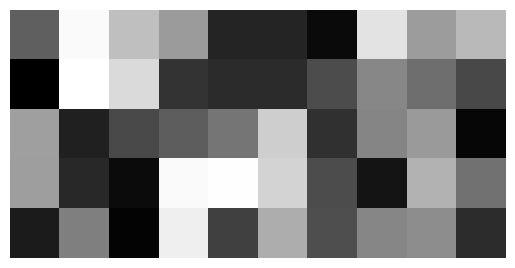

In [129]:
#Test Image for trial
np.random.seed(42)
smallimage = np.random.rand(50)
plt.imshow(smallimage.reshape(5, 10), cmap='gray')   # `cmap='gray'` for black/white images
plt.axis('off')                # Optional: hide axis ticks
plt.show()

Set target image (as above), to a padded target mps (below)

In [16]:
'''Want something that takes an image data string and returns an mps ready for code'''
def image_to_mps(img):
    img_padded = pad_to_next_power_of_two(img.reshape(-1), pad_value=0).astype(float)
    imagempstarget = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()
    return imagempstarget
target_mps=image_to_mps(smallimage)

NameError: name 'smallimage' is not defined

run the algorithm to construct the approximations for each layer (without the global optimisation for each step)

In [147]:
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=2,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   6%|▌         | 35/600 [00:00<00:10, 53.00it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([0.7784, 0.0988, 0.0842, 0.0386], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.6243025302375478
 bond 2 = 0.8243154773048752
 bond 4 = 0.9780178766235534
 bond 6 = 0.9973989089503621

 LAYER 0
initial loss = 0.2893968889366244
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.91163615 0.26182356 0.69335455 0.89773054]
New tail entropy term = 2.764544786315099
tensor([3.3349e-12, 5.8335e-02, 1.0830e-01, 1.2277e-01], dtype=torch.float64)
At init net entropy comp = 3.5546395523669707 // tail loss = 0.2893968889366244


  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.086080703488 [best: +0.086080703488] :  58%|█████▊    | 467/800 [00:29<00:21, 15.64it/s]


final loss = 0.08608070348754338
best val = 0.08608070348754338. Final loss = 0.08608070348754338
after updating, final loss = 0.08608070348754338
Tail entropy (normalised) per cut: [0.85134704 0.24502575 0.64633905 0.94071239]
New tail entropy term = 2.683424220810618
tensor([3.9465e-12, 3.1548e-02, 4.1105e-02, 1.3428e-02], dtype=torch.float64)
After opt: net entropy comp = 2.7704289415495245 // tail loss = 0.08608070348754338
Returning current approx state...


...

+0.050631592420 [best: +0.050631592420] :  49%|████▉     | 395/800 [00:31<00:32, 12.42it/s]



 LAYER 1
initial loss = 0.08605545314851071
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.79774101 0.24493605 0.64508633 0.9406572 ]
New tail entropy term = 2.6284205955034388
tensor([3.5876e-12, 3.1540e-02, 4.1097e-02, 1.3418e-02], dtype=torch.float64)
At init net entropy comp = 2.7707792960451605 // tail loss = 0.08605545314851071


+0.030835255389 [best: +0.030835255389] : : 1043it [01:06, 15.59it/s]                      


final loss = 0.030835255388823923
best val = 0.030835255388823923. Final loss = 0.030835255388823923
after updating, final loss = 0.030835255388823923
Tail entropy (normalised) per cut: [0.80671148 0.26586513 0.63070098 0.95629826]
New tail entropy term = 2.659575852510079
tensor([3.7620e-12, 1.7340e-02, 9.5740e-03, 3.9213e-03], dtype=torch.float64)
After opt: net entropy comp = 2.5237287975248752 // tail loss = 0.030835255388823923
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9810215066384018
 error from singular value truncation ~ (1.7045269786297723e-05+2.0817036543725723e-17j), cut from max bond 8 to 7. sv cutoff = 0.0001
 new max bond = 7
norm = (0.9999999999999999-6.93889390390723e-18j)
2. Central schmidt coefficients = tensor([0.8299, 0.1662, 0.0024, 0.0015], dtype=torch.float64)
 bond 2 = 0.9810494243030248
 bond 4 = 0.9984744736005257
 bond 6 = 0.9997808362829864
optimising for chi=2 approx:


+0.018889484030 [best: +0.018889484030] :  38%|███▊      | 302/800 [00:23<00:39, 12.72it/s]


LAYER  0
Fidelity is:  tensor(0.7165, dtype=torch.float64)


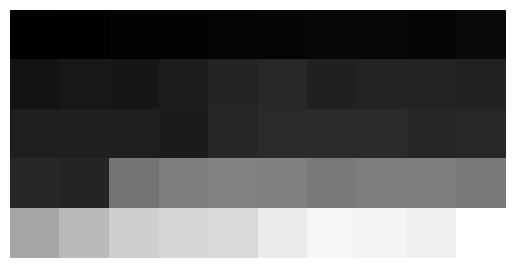

LAYER  1
Fidelity is:  tensor(0.7556, dtype=torch.float64)


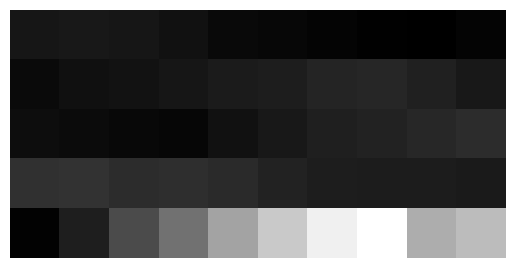

LAYER  2
Fidelity is:  tensor(0.8039, dtype=torch.float64)


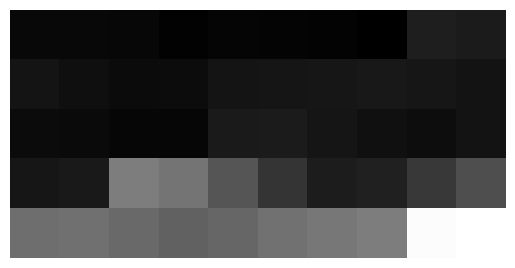

LAYER  3
Fidelity is:  tensor(0.8335, dtype=torch.float64)


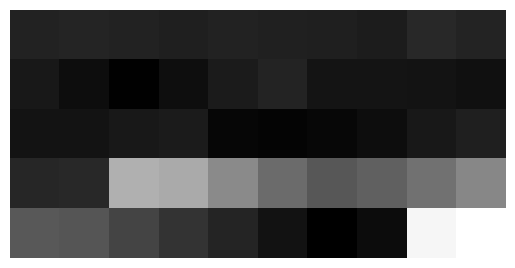

In [ ]:
#Unsure if len and wid are actually right here
def approx_state_to_image(approx_state,height,width):
    """
    Takes an approx state tensor network, and reshapes and shows image.
    """
    extracted_vector=approx_state.contract(all).data.detach().numpy().reshape(-1)
    img_size=height*width
    #unpads and puts the norm in to swap from complex to real
    extracted_vector_unpadded=np.abs(extracted_vector[:img_size])
    plt.imshow(extracted_vector_unpadded.reshape(height,width), cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
    
def get_image_results(approx_states,fids,height,width):
    #create target state from an image file
    for i in range(len(approx_states)):
        print("LAYER ",i)
        print("Fidelity is: ",fids[i])
        approx_state_to_image(approx_states[i],height,width)
get_image_results(approx_states,fids,5,10)

YES! IT WORKS WITH TEST IMAGE! JUST WANT TO STREAMLINE THIS PROCESS NOW

## Main Trials

Used functions defined in section above.

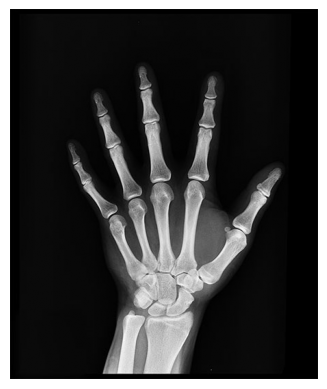

In [10]:
# Load the image
img = mpimg.imread("handxray.jpg")[:, :, 0]
# Display it
plt.imshow(img, cmap='gray')   # `cmap='gray'` for black/white images
plt.axis('off')                # Optional: hide axis ticks
plt.show()

### Target chi=16

In [13]:
target_mps=image_to_mps(img)
#16 seems to be the most you can compress without it looking like a complete blur. 
target_mps.compress(max_bond = 16)
target_mps

#Dont think there is any point in compressing this image before running it though code, but seems to be taking ages so i will actaully cut it here.

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(


MatrixProductState(tensors=18, indices=35, L=18, max_bond=16)

Cutting down to 16 really sped things up. running with full bond didnt even seem to work but want to check with josh if compressing before is bad or not.

Now run through full circuit, just do 2 layers so it doesn't take ages, could be worth checking how changing the sv_cutoff varies the runtime and image quality. Allegedly you can be agressive with this.

In [ ]:
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=8,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   8%|▊         | 46/600 [00:01<00:22, 24.53it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([4.4799e-01, 1.9874e-01, 8.7340e-02, 3.8318e-02, 2.5434e-02, 2.4339e-02,
        1.9970e-02, 1.8314e-02, 1.8038e-02, 1.5103e-02, 1.1917e-02, 9.1815e-03,
        7.8142e-03, 7.4303e-03, 7.3531e-03, 6.7042e-03, 5.8147e-03, 4.5017e-03,
        3.1840e-03, 2.1588e-03, 1.5931e-03, 1.3527e-03, 1.2106e-03, 1.1455e-03,
        1.0044e-03, 9.4843e-04, 9.1554e-04, 8.5504e-04, 7.8816e-04, 7.6515e-04,
        7.1251e-04, 6.1512e-04, 5.8055e-04, 5.1551e-04, 5.0848e-04, 4.5497e-04,
        4.4884e-04, 4.1591e-04, 4.1021e-04, 3.7845e-04, 3.7105e-04, 3.2529e-04,
        2.8780e-04, 2.3105e-04, 2.0657e-04, 1.8916e-04, 1.6984e-04, 1.6323e-04,
        1.5916e-04, 1.4165e-04, 1.2677e-04, 1.2073e-04, 1.0989e-04, 9.8691e-05,
        7.4696e-05, 7.0632e-05, 6.4401e-05, 5.5496e-05, 4.9367e-05, 4.8115e-05,
        4.0399e-05, 3.7008e-05, 2.9483e-05, 2.0662e-05], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.2523427824613586
 bond 2 = 0.347

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+3.856274722099 [best: +3.856274722099] :   4%|▎         | 28/800 [00:47<21:55,  1.70s/it]


final loss = 3.831838805081887
best val = 3.831838805081887. Final loss = 3.831838805081887
after updating, final loss = 3.831838805081887
Tail entropy (normalised) per cut: [0.92215217 0.24405287 0.49977762 0.59139177 0.61837358 0.54601428
 0.57438533 0.59622577 0.59192792 0.5652144  0.47881466 0.42036792
 0.40790392 0.41617192 0.39972496 0.43923076]
New tail entropy term = 8.31172983147794
tensor([5.0169e-12, 1.7459e-01, 2.6459e-01, 3.4027e-01, 3.7824e-01, 4.8295e-01,
        4.7773e-01, 4.7250e-01, 4.6528e-01, 3.3873e-01, 2.2286e-01, 1.3811e-01,
        5.4339e-02, 1.7111e-02, 4.0138e-03, 5.3528e-04], dtype=torch.float64)
After opt: net entropy comp = 31.740281139855483 // tail loss = 3.831838805081887
Returning current approx state...


C:\Users\archi\AppData\Local\Temp\ipykernel_5276\71621303.py:1401: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  fidelity = np.abs((full_circ_tn.conj() | targ_mps).contract(all))**2


True fidelity after reconstruction (should match bond 2) = 0.39220923299165683
 error from singular value truncation ~ (0.011226039743667093+3.8401104425498885e-17j), cut from max bond 128 to 93. sv cutoff = 0.0001
 new max bond = 93
norm = (1.0000000000000007-2.226519540179921e-16j)
2. Central schmidt coefficients = tensor([4.5396e-01, 2.0780e-01, 8.9887e-02, 3.7694e-02, 2.6392e-02, 2.5072e-02,
        2.0414e-02, 1.8694e-02, 1.8248e-02, 1.5839e-02, 1.1988e-02, 9.2709e-03,
        8.2133e-03, 7.7103e-03, 7.4187e-03, 6.6455e-03, 5.8705e-03, 4.6730e-03,
        3.2216e-03, 2.1472e-03, 1.6286e-03, 1.3704e-03, 1.2323e-03, 1.1718e-03,
        1.0155e-03, 9.3844e-04, 9.0886e-04, 8.5983e-04, 7.8477e-04, 7.7078e-04,
        7.2216e-04, 6.2049e-04, 5.9111e-04, 5.2092e-04, 4.8698e-04, 4.6938e-04,
        4.5099e-04, 4.2913e-04, 3.9939e-04, 3.7605e-04, 3.6061e-04, 3.3653e-04,
        2.7462e-04, 2.3461e-04, 2.0247e-04, 1.8653e-04, 1.7078e-04, 1.5969e-04,
        1.5180e-04, 1.4220e-04, 1.2883e-0

  0%|          | 0/800 [00:00<?, ?it/s]

LAYER  0
Fidelity is:  tensor(0.3888, dtype=torch.float64)


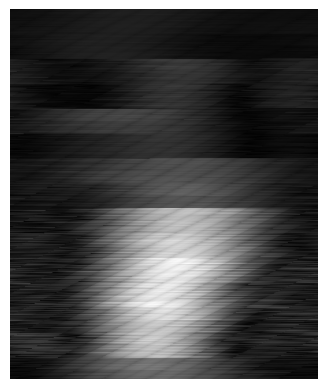

LAYER  1
Fidelity is:  tensor(0.6810, dtype=torch.float64)


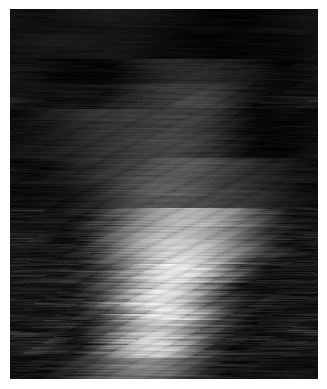

In [167]:
get_image_results(approx_states,fids,541,450)

### Target chi=32

In [15]:
target_mps=image_to_mps(img)
target_mps.compress(max_bond = 32)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=8,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  10%|█         | 60/600 [00:02<00:21, 25.22it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([4.4743e-01, 1.9843e-01, 8.7058e-02, 3.8103e-02, 2.5204e-02, 2.4082e-02,
        1.9782e-02, 1.8127e-02, 1.7834e-02, 1.4902e-02, 1.1749e-02, 9.0191e-03,
        7.6346e-03, 7.2319e-03, 7.1369e-03, 6.4851e-03, 5.5809e-03, 3.8839e-03,
        2.1264e-03, 8.1168e-04, 3.9461e-04, 2.5549e-04, 2.2900e-04, 1.6453e-04,
        1.2556e-04, 9.3537e-05, 7.6858e-05, 6.2803e-05, 4.7297e-05, 4.1517e-05,
        3.2208e-05, 2.2593e-05], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.2515491371641279
 bond 2 = 0.35629479056257
 bond 4 = 0.6768699104275824
 bond 6 = 0.7755865955097533

 LAYER 0
initial loss = 3.9401064611126495
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.91780949 0.10827788 0.43079488 0.47715368 0.56226943 0.60430282
 0.61830878 0.6336863  0.63995796 0.59712867 0.47529467 0.29535583
 0.191749   0.2367394  0.3442833  0.41999792]
New tail entropy term = 7.55311000250152
tensor([5.07

+2.909980890263 [best: +2.899103892781] : : 1264it [19:39,  1.07it/s]                      


final loss = 2.9267160740887603
best val = 2.899103892780502. Final loss = 2.9267160740887603
after updating, final loss = 2.899103892780502
Tail entropy (normalised) per cut: [0.91716084 0.13883254 0.45764943 0.5537197  0.68358188 0.77949831
 0.78971009 0.77685647 0.73042186 0.62675634 0.48320498 0.29537397
 0.21204685 0.24528478 0.34470366 0.42144301]
New tail entropy term = 8.45624473141172
tensor([5.0415e-12, 1.4826e-01, 2.6163e-01, 2.9785e-01, 3.2056e-01, 3.2628e-01,
        3.3013e-01, 3.3065e-01, 2.9617e-01, 2.4249e-01, 1.8549e-01, 1.1892e-01,
        3.4566e-02, 5.3106e-03, 7.1356e-04, 8.0942e-05], dtype=torch.float64)
After opt: net entropy comp = 28.295454932244677 // tail loss = 2.899103892780502
Returning current approx state...


...

+0.277441979866 [best: +0.277441979866] : : 1299it [06:49,  3.17it/s]                      



 LAYER 7
initial loss = 2.093805919408845
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.90376357 0.21537863 0.48446474 0.6015084  0.65734419 0.67968461
 0.76195331 0.81148717 0.80926384 0.78627225 0.74717035 0.60974293
 0.23555362 0.1183303  0.01329262 0.11103552]
New tail entropy term = 8.546246024187774
tensor([4.6292e-12, 8.6772e-02, 1.6853e-01, 2.1585e-01, 2.4207e-01, 2.4970e-01,
        2.4914e-01, 2.3723e-01, 2.1528e-01, 1.8113e-01, 1.3146e-01, 8.1696e-02,
        3.1534e-02, 3.2685e-03, 1.3532e-04, 1.1992e-07], dtype=torch.float64)
At init net entropy comp = 24.0753413296702 // tail loss = 2.093805919408845


+2.069885086782 [best: +2.068858530619] : : 1262it [18:26,  1.14it/s]                      


final loss = 2.072974628975139
best val = 2.068858530619296. Final loss = 2.072974628975139
after updating, final loss = 2.068858530619296
Tail entropy (normalised) per cut: [0.9024981  0.24688761 0.50308853 0.60848053 0.66586207 0.69203701
 0.77013391 0.81948001 0.80843382 0.78605927 0.74716715 0.60971489
 0.2361631  0.11414726 0.12713629 0.06774933]
New tail entropy term = 8.70503890883226
tensor([4.8466e-12, 8.5915e-02, 1.6679e-01, 2.1242e-01, 2.3481e-01, 2.4644e-01,
        2.4413e-01, 2.3415e-01, 2.1498e-01, 1.8112e-01, 1.3146e-01, 8.1696e-02,
        3.1533e-02, 3.2708e-03, 1.3388e-04, 8.7282e-08], dtype=torch.float64)
After opt: net entropy comp = 21.731425297520286 // tail loss = 2.068858530619296
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.7217360563809814
 error from singular value truncation ~ (0.00019928963056159432+1.466389800948637e-17j), cut from max bond 128 to 124. sv cutoff = 0.0001
 new max bond = 124
norm = (1.00000

+0.999999969466 [best: +0.999996594549] :   0%|          | 3/800 [00:01<06:55,  1.92it/s]


LAYER  0
Fidelity is:  tensor(0.3563, dtype=torch.float64)


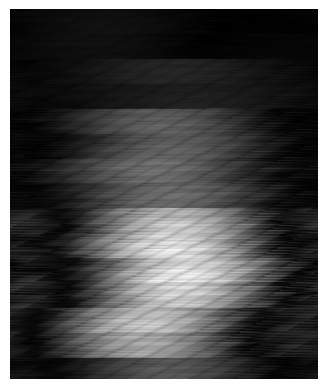

LAYER  1
Fidelity is:  tensor(0.6207, dtype=torch.float64)


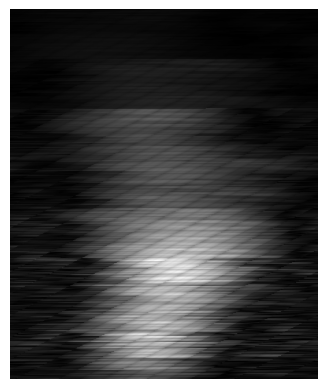

LAYER  2
Fidelity is:  tensor(0.6731, dtype=torch.float64)


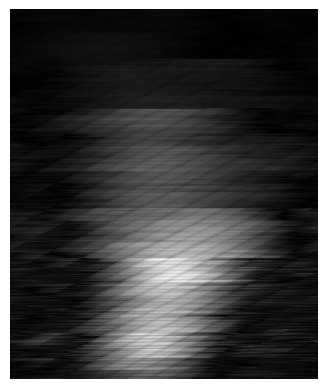

LAYER  3
Fidelity is:  tensor(0.6957, dtype=torch.float64)


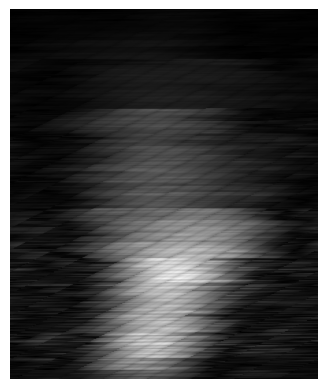

LAYER  4
Fidelity is:  tensor(0.6998, dtype=torch.float64)


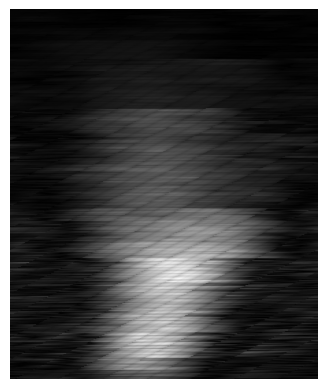

LAYER  5
Fidelity is:  tensor(0.7098, dtype=torch.float64)


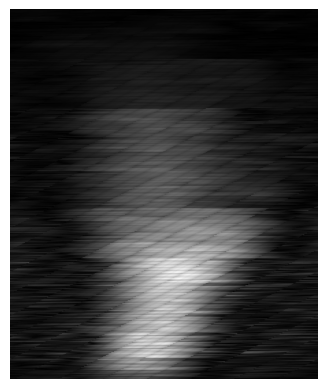

LAYER  6
Fidelity is:  tensor(0.7161, dtype=torch.float64)


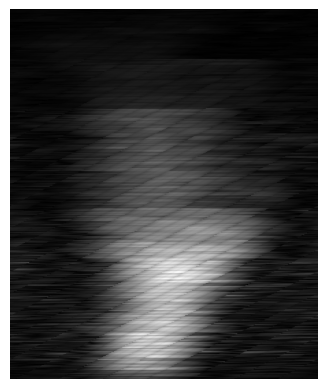

LAYER  7
Fidelity is:  tensor(0.7213, dtype=torch.float64)


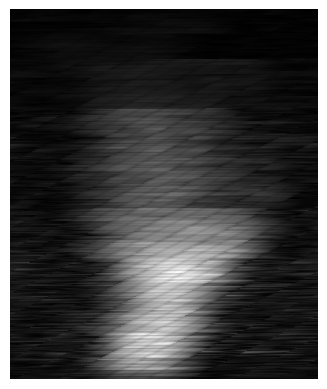

In [17]:
get_image_results(approx_states,fids,541,450)

### Target (condensed)

In [17]:
target_mps=image_to_mps(img_condense)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=4,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   7%|▋         | 41/600 [00:00<00:13, 42.99it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([4.2520e-01, 3.2410e-01, 5.6358e-02, 3.9283e-02, 3.1514e-02, 2.9273e-02,
        2.1580e-02, 1.2986e-02, 1.0126e-02, 8.6948e-03, 7.8901e-03, 6.2220e-03,
        4.8407e-03, 3.6603e-03, 2.8625e-03, 2.1787e-03, 1.3884e-03, 1.2162e-03,
        1.0909e-03, 8.6703e-04, 7.7771e-04, 7.0132e-04, 5.9464e-04, 5.2345e-04,
        5.0048e-04, 4.7224e-04, 4.5180e-04, 4.3083e-04, 3.6846e-04, 3.2429e-04,
        3.1184e-04, 2.7834e-04, 2.5499e-04, 2.3394e-04, 2.1617e-04, 1.8878e-04,
        1.6164e-04, 1.5799e-04, 1.4810e-04, 1.4665e-04, 1.2384e-04, 1.1522e-04,
        1.1229e-04, 1.0261e-04, 8.9175e-05, 8.7148e-05, 8.0170e-05, 7.5506e-05,
        7.2753e-05, 6.6562e-05, 6.3739e-05, 5.7120e-05, 5.1792e-05, 4.9919e-05,
        4.3696e-05, 4.0830e-05, 3.9282e-05, 3.4241e-05, 3.3519e-05, 3.2087e-05,
        3.1452e-05, 1.3953e-05, 1.1418e-05, 5.4368e-06], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.29337020239520206
 bond 2 = 0.71

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+1.347121526149 [best: +1.347121526149] : : 1285it [10:33,  2.03it/s]                      


...

+0.165176999712 [best: +0.165175533559] : : 1102it [04:15,  4.31it/s]                      



 LAYER 3
initial loss = 0.793466567036101
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.81026719 0.25544958 0.45177704 0.46196394 0.45901756 0.52644972
 0.64205327 0.73150341 0.75176974 0.70813969 0.68925804 0.83668216]
New tail entropy term = 7.324331337504946
tensor([3.6284e-12, 3.5676e-02, 4.1769e-02, 4.2885e-02, 9.0139e-02, 1.1843e-01,
        1.3169e-01, 1.2183e-01, 9.8099e-02, 6.5433e-02, 3.8753e-02, 8.7657e-03],
       dtype=torch.float64)
At init net entropy comp = 11.711506393964969 // tail loss = 0.793466567036101


+0.708143425666 [best: +0.708143425666] : : 1253it [08:06,  2.58it/s]                      


final loss = 0.711583037646964
best val = 0.7081434256655749. Final loss = 0.711583037646964
after updating, final loss = 0.7081434256655749
Tail entropy (normalised) per cut: [0.80989414 0.26002358 0.43278195 0.47131196 0.46901695 0.54485864
 0.67573214 0.76677717 0.76451978 0.71375637 0.7332449  0.82995851]
New tail entropy term = 7.471876091597522
tensor([3.6205e-12, 1.4734e-02, 1.7249e-02, 4.1031e-02, 8.6321e-02, 1.1609e-01,
        1.1994e-01, 1.0928e-01, 9.1793e-02, 6.4922e-02, 3.8075e-02, 8.7052e-03],
       dtype=torch.float64)
After opt: net entropy comp = 10.949356737994094 // tail loss = 0.7081434256655749
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.8531469093528762
 error from singular value truncation ~ (0.00022471232109866346-6.337177547778939e-17j), cut from max bond 104 to 80. sv cutoff = 0.0001
 new max bond = 80
norm = (1.0000000000000002-2.8516010031938297e-16j)
2. Central schmidt coefficients = tensor([8.3522e-01, 5

+0.999998326457 [best: +0.144764706235] :  55%|█████▌    | 441/800 [01:44<01:25,  4.22it/s]


LAYER  0
Fidelity is:  tensor(0.7165, dtype=torch.float64)


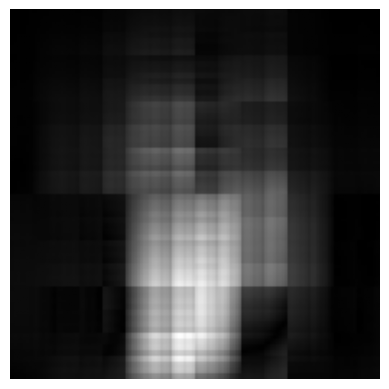

LAYER  1
Fidelity is:  tensor(0.7556, dtype=torch.float64)


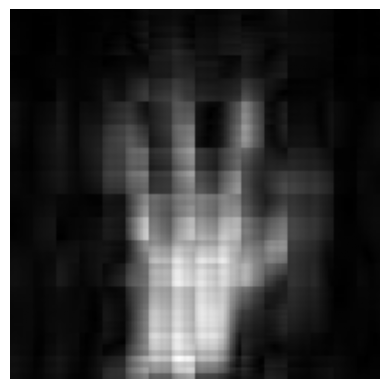

LAYER  2
Fidelity is:  tensor(0.8039, dtype=torch.float64)


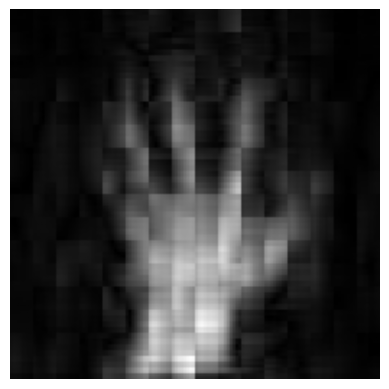

LAYER  3
Fidelity is:  tensor(0.8335, dtype=torch.float64)


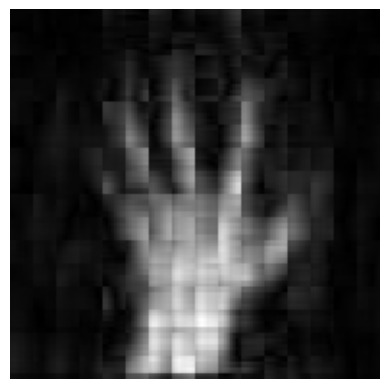

In [20]:
get_image_results(approx_states,fids,128,128)

This is better, now I'll try the post processing step.

C:\Users\archi\AppData\Local\Temp\ipykernel_24796\71621303.py:2239: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in qc.data:
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self

fidelity of the non-parametrised circuit vs chi2 state = 1.0000000000000044


+0.000000000000 [best: +0.000000000000] :  24%|██▍       | 147/600 [00:02<00:07, 56.70it/s]


Archie Testing: should draw here


C:\Users\archi\AppData\Local\Temp\ipykernel_24796\71621303.py:2474: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')


...

C:\Users\archi\AppData\Local\Temp\ipykernel_24796\71621303.py:2475: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')


Fidelity of param circ with final_layer = 0.9999999999998035
('k0', 'k1', 'k2', 'k3', 'k4', 'k5', 'k6', 'k7', 'k8', 'k9', 'k10', 'k11', 'k12', 'k13')


C:\Users\archi\AppData\Local\Temp\ipykernel_24796\71621303.py:2482: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Copy.cpp:309.)
  npsi = applied_uni.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
C:\Users\archi\AppData\Local\Temp\ipykernel_24796\71621303.py:2549: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')


Loss using final state = 0.14685332909651716
Fidelity of param final circ with final layer = 0.999999999999803
Loss using final state = 0.14685332891809932


  0%|          | 0/500 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:1523: OptimizeWarning: Unknown solver options: lr
  self.res = minimize(
+0.110996539002 [best: +0.110996539002] : : 501it [12:34,  1.51s/it]                       


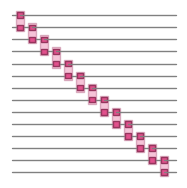

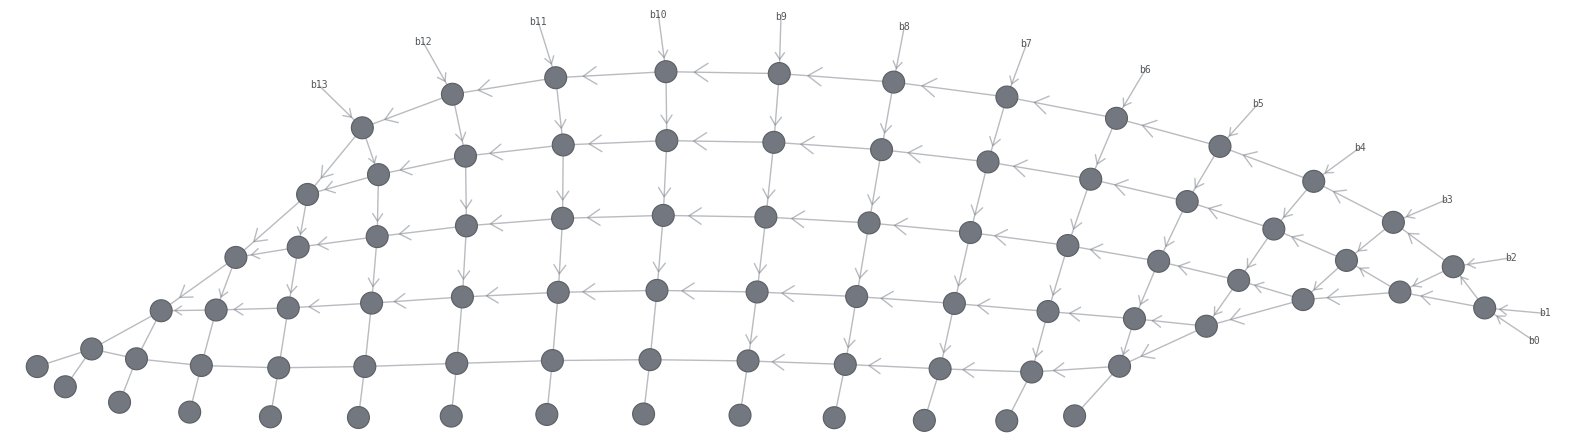

params = {14: tensor([-1.4603,  1.7340, -2.2448, -1.2097, -0.7210,  0.7074, -0.2084, -0.8377,
        -0.0920,  0.4579,  0.2911,  0.6509,  2.3020,  0.7343, -1.6546],
       dtype=torch.float64), 15: tensor([-1.0603,  0.2285, -0.8672, -0.9355,  0.3371, -1.1227,  0.2463, -0.3982,
        -0.2767, -1.1341,  0.7150,  0.8761,  3.5057,  0.6229, -2.2732],
       dtype=torch.float64), 16: tensor([-0.7520,  0.0875,  0.4365, -1.4172, -0.0653, -0.2522, -0.3769, -0.5857,
        -0.4312, -2.0000,  0.9823, -1.5000,  2.5593,  3.0488, -0.2663],
       dtype=torch.float64), 17: tensor([-1.8406, -0.0789,  0.0393,  3.3478,  0.2263,  0.0634,  0.2211, -0.6380,
        -0.3853, -0.0207,  2.0288,  1.1639,  0.1683,  3.1330,  0.3264],
       dtype=torch.float64), 18: tensor([ 0.1236,  0.5206,  0.2673, -1.7715,  0.4944,  0.0380, -0.1139, -0.1768,
        -0.0492, -0.0873,  0.4085,  1.0662,  2.6634,  3.1457,  0.0673],
       dtype=torch.float64), 19: tensor([-0.0483, -0.2268,  0.2332,  0.7571,  1.4359,  0.0323,

In [23]:
L=4
trained_tn = SCS_all(target_mps, disentangled_mps = mps_states[L-1], param_set = param_set[:L], verbose=True)

In [25]:
lastlayeroptimizedtn=trained_tn.copy()

In [33]:
lastlayeroptimizedtn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

In [35]:
lastlayeroptimizedtn.contract(all)

Tensor(shape=(2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2), inds=('b0', 'b1', 'b2', 'b3', 'b4', 'b5', 'b6', 'b7', 'b8', 'b9', 'b10', 'b11', 'b12', 'b13'), tags=oset(['SU4', 'GATE_0', 'I0', 'I1', 'GATE_1', 'I2', 'GATE_2', 'I3', 'GATE_3', 'I4', 'GATE_4', 'I5', 'GATE_5', 'I6', 'GATE_6', 'I7', 'GATE_7', 'I8', 'GATE_8', 'I9', 'GATE_9', 'I10', 'GATE_10', 'I11', 'GATE_11', 'I12', 'GATE_12', 'I13', 'GATE_13', 'GATE_14', 'GATE_15', 'GATE_16', 'GATE_17', 'GATE_18', 'GATE_19', 'GATE_20', 'GATE_21', 'GATE_22', 'GATE_23', 'GATE_24', 'GATE_25', 'GATE_26', 'GATE_27', 'GATE_28', 'GATE_29', 'GATE_30', 'GATE_31', 'GATE_32', 'GATE_33', 'GATE_34', 'GATE_35', 'GATE_36', 'GATE_37', 'GATE_38', 'GATE_39', 'GATE_40', 'GATE_41', 'GATE_42', 'GATE_43', 'GATE_44', 'GATE_45', 'GATE_46', 'GATE_47', 'GATE_48', 'GATE_49', 'GATE_50', 'GATE_51']))

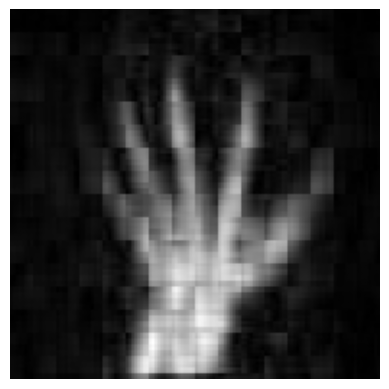

In [36]:
approx_state_to_image(lastlayeroptimizedtn,128,128)

I mean this is slightly better than before! Managed to get a decent representation of it. Not much different though compared to other layer approaches.

### Target condensed, 10 Layers

In [39]:
target_mps=image_to_mps(img_condense)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


  0%|          | 0/600 [00:00<?, ?it/s]

+0.000000000000 [best: +0.000000000000] :  10%|▉         | 59/600 [00:01<00:14, 36.54it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([4.2520e-01, 3.2410e-01, 5.6358e-02, 3.9283e-02, 3.1514e-02, 2.9273e-02,
        2.1580e-02, 1.2986e-02, 1.0126e-02, 8.6948e-03, 7.8901e-03, 6.2220e-03,
        4.8407e-03, 3.6603e-03, 2.8625e-03, 2.1787e-03, 1.3884e-03, 1.2162e-03,
        1.0909e-03, 8.6703e-04, 7.7771e-04, 7.0132e-04, 5.9464e-04, 5.2345e-04,
        5.0048e-04, 4.7224e-04, 4.5180e-04, 4.3083e-04, 3.6846e-04, 3.2429e-04,
        3.1184e-04, 2.7834e-04, 2.5499e-04, 2.3394e-04, 2.1617e-04, 1.8878e-04,
        1.6164e-04, 1.5799e-04, 1.4810e-04, 1.4665e-04, 1.2384e-04, 1.1522e-04,
        1.1229e-04, 1.0261e-04, 8.9175e-05, 8.7148e-05, 8.0170e-05, 7.5506e-05,
        7.2753e-05, 6.6562e-05, 6.3739e-05, 5.7120e-05, 5.1792e-05, 4.9919e-05,
        4.3696e-05, 4.0830e-05, 3.9282e-05, 3.4241e-05, 3.3519e-05, 3.2087e-05,
        3.1452e-05, 1.3953e-05, 1.1418e-05, 5.4368e-06], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.29337020239520206
 bond 2 = 0.71

...

+0.091548904475 [best: +0.091548904475] :  56%|█████▋    | 450/800 [01:42<01:19,  4.39it/s]



 LAYER 9
initial loss = 0.5097809988039459
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.51139016 0.23135853 0.35060975 0.45129019 0.52507048 0.61286106
 0.73618297 0.823029   0.82565042 0.78484945 0.7057098  0.77103585]
New tail entropy term = 7.329037668429545
tensor([2.6518e-12, 2.1868e-03, 1.5764e-02, 4.0769e-02, 6.5547e-02, 7.4389e-02,
        7.8284e-02, 7.3333e-02, 6.6882e-02, 5.2982e-02, 3.2891e-02, 6.7538e-03],
       dtype=torch.float64)
At init net entropy comp = 8.284952447591053 // tail loss = 0.5097809988039459


+0.490796081553 [best: +0.490796081553] : : 1246it [07:41,  2.70it/s]                      


final loss = 0.49226963543093627
best val = 0.4907960815533171. Final loss = 0.49226963543093627
after updating, final loss = 0.4907960815533171
Tail entropy (normalised) per cut: [0.51231412 0.24115191 0.35535954 0.45429018 0.53549275 0.62090751
 0.75308858 0.8300349  0.83719187 0.79083396 0.71443556 0.77008197]
New tail entropy term = 7.4151828468620415
tensor([2.6491e-12, 2.1806e-03, 1.5760e-02, 4.0433e-02, 6.1116e-02, 7.1643e-02,
        7.3171e-02, 7.1696e-02, 6.4759e-02, 5.1946e-02, 3.1343e-02, 6.7487e-03],
       dtype=torch.float64)
After opt: net entropy comp = 7.465971070899981 // tail loss = 0.4907960815533171
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9082329314700653
 error from singular value truncation ~ (0.0002179230431796908-1.709894224170878e-16j), cut from max bond 102 to 74. sv cutoff = 0.0001
 new max bond = 74
norm = (1.0000000000000009-2.884923808734404e-16j)
2. Central schmidt coefficients = tensor([8.4653e-01,

+0.087266530857 [best: +0.087266530857] : : 1271it [05:34,  3.80it/s]                      


LAYER  0
Fidelity is:  tensor(0.7165, dtype=torch.float64)


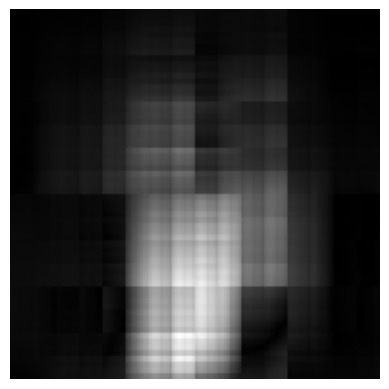

LAYER  1
Fidelity is:  tensor(0.7556, dtype=torch.float64)


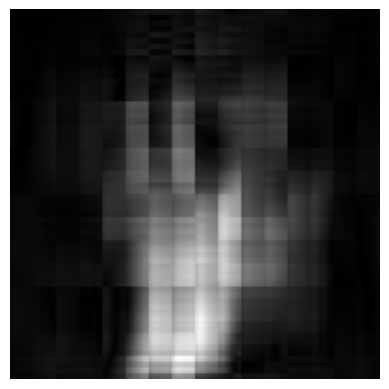

LAYER  2
Fidelity is:  tensor(0.7883, dtype=torch.float64)


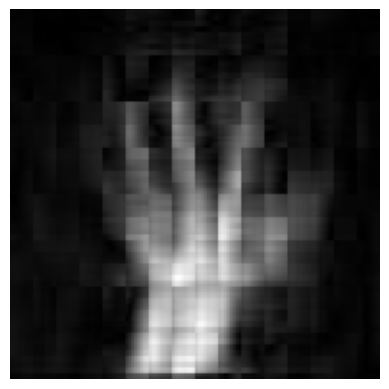

LAYER  3
Fidelity is:  tensor(0.8335, dtype=torch.float64)


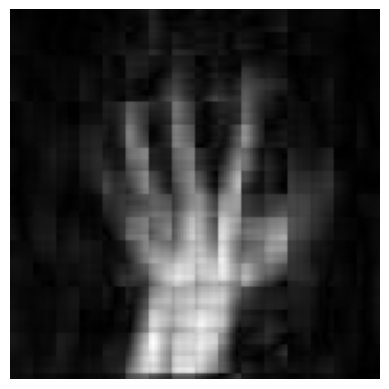

LAYER  4
Fidelity is:  tensor(0.8565, dtype=torch.float64)


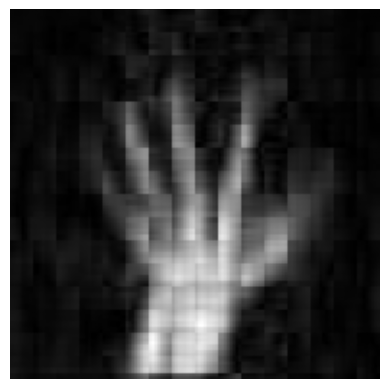

LAYER  5
Fidelity is:  tensor(0.8744, dtype=torch.float64)


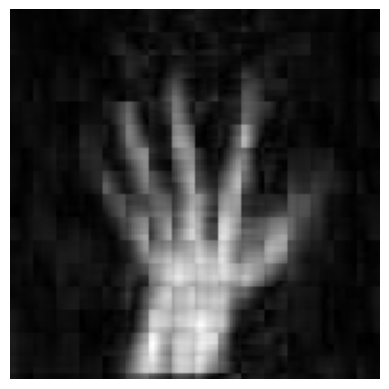

LAYER  6
Fidelity is:  tensor(0.8859, dtype=torch.float64)


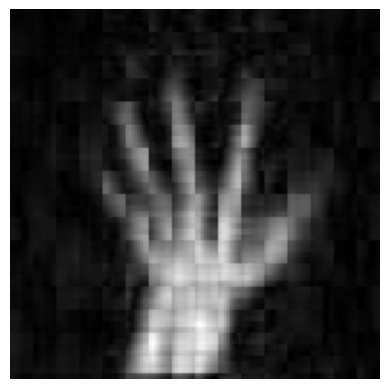

LAYER  7
Fidelity is:  tensor(0.8939, dtype=torch.float64)


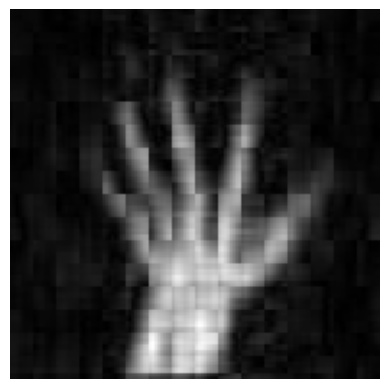

LAYER  8
Fidelity is:  tensor(0.9005, dtype=torch.float64)


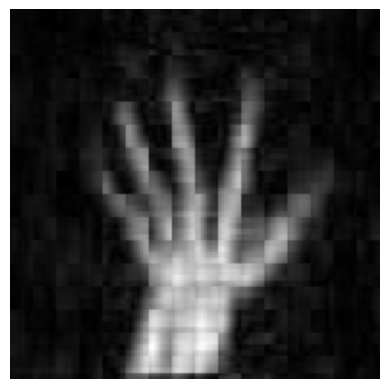

LAYER  9
Fidelity is:  tensor(0.9084, dtype=torch.float64)


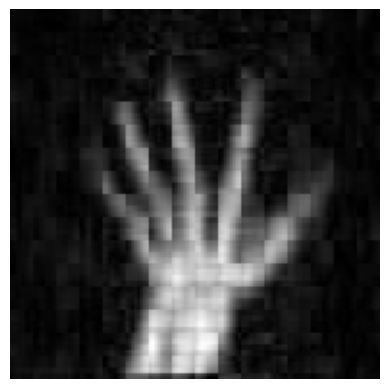

In [41]:
get_image_results(approx_states,fids,128,128)

Okay so this is a little better than the 4 layers (but not that much) I think the move now is to look at the wavelet representation and see if there is anything that can be done there to make the storage of the image data better. The fact it is okay to store the image as these abstract coefficients of a wavelet makes me wonder about the utility of reodering the coefficients to make it all easier.

### Target DWT (no chi truncation before), 2 Layers

This seemed to have much worse encoding than I hoped. I will try to run this again with 10 layers and hope that the 0.5 becomes much better. In principle this should work, and the method of decomposing then reconstructing seems to work. That being said you can compare the schmidt coefficients of the original img_condense and the mps of the wavelet compression and you actually see the wavelet compression looking a little worse. My only hope is that the schmidt coefficients are just "less important" for the mps wavelet copmression, so loosing them will not matter as much.

In [94]:
target_mps, arr_shape, slices, shape = dwt_image_to_mps(img_condense)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=2,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   8%|▊         | 49/600 [00:01<00:11, 45.93it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([3.5903e-01, 2.1090e-01, 1.6541e-01, 5.0644e-02, 3.5297e-02, 2.5289e-02,
        2.3281e-02, 1.7433e-02, 1.2757e-02, 1.1450e-02, 1.0397e-02, 8.8590e-03,
        7.9872e-03, 7.0440e-03, 5.6027e-03, 4.3649e-03, 4.2782e-03, 3.5493e-03,
        3.2706e-03, 2.9721e-03, 2.7627e-03, 2.2853e-03, 2.0866e-03, 1.8918e-03,
        1.7679e-03, 1.6916e-03, 1.4337e-03, 1.3695e-03, 1.3177e-03, 1.2133e-03,
        1.0727e-03, 1.0571e-03, 9.9394e-04, 8.6643e-04, 7.8084e-04, 6.6901e-04,
        6.3612e-04, 5.7002e-04, 5.6402e-04, 5.1677e-04, 4.9564e-04, 4.3214e-04,
        3.9648e-04, 3.8198e-04, 3.2836e-04, 2.9540e-04, 2.8863e-04, 2.6845e-04,
        2.3407e-04, 2.1518e-04, 2.0495e-04, 1.9557e-04, 1.6955e-04, 1.6247e-04,
        1.5384e-04, 1.2728e-04, 1.0904e-04, 7.9209e-05, 7.1047e-05, 2.2153e-05,
        4.5863e-06, 2.5610e-06, 1.8322e-07, 2.6549e-08], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.20677336256366177
 bond 2 = 0.52

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+2.475134275862 [best: +2.475134275862] : : 1267it [11:47,  1.79it/s]                      


...

+0.511937840172 [best: +0.511937840172] : : 1157it [04:47,  4.02it/s]                      



 LAYER 1
initial loss = 2.4721204957301994
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.65036929 0.23965136 0.34286396 0.46468657 0.48800396 0.52028996
 0.51778751 0.5959075  0.64507045 0.63089301 0.52691358 0.99863043]
New tail entropy term = 6.621067560809959
tensor([3.0842e-12, 5.6999e-03, 3.5695e-02, 8.2138e-02, 1.5925e-01, 2.4922e-01,
        4.2985e-01, 4.2969e-01, 4.2083e-01, 3.9019e-01, 2.5386e-01, 1.5697e-02],
       dtype=torch.float64)
At init net entropy comp = 20.396924097772697 // tail loss = 2.4721204957301994


+2.114985734851 [best: +2.114985734851] : : 1285it [10:26,  2.05it/s]                      


final loss = 2.1157062663129276
best val = 2.1149857348505576. Final loss = 2.1157062663129276
after updating, final loss = 2.1149857348505576
Tail entropy (normalised) per cut: [0.64935563 0.25156123 0.3441186  0.45942736 0.49271419 0.53767371
 0.51782666 0.58016005 0.5871685  0.55490465 0.8173465  0.99863248]
New tail entropy term = 6.790889559474398
tensor([3.0922e-12, 5.7001e-03, 3.5674e-02, 8.1921e-02, 1.5426e-01, 2.3135e-01,
        4.2983e-01, 4.2631e-01, 4.0151e-01, 2.7604e-01, 5.6716e-02, 1.5685e-02],
       dtype=torch.float64)
After opt: net entropy comp = 19.113448423660696 // tail loss = 2.1149857348505576
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.5252843191255553
 error from singular value truncation ~ (0.00015799338869215696+1.6616371855990507e-16j), cut from max bond 124 to 77. sv cutoff = 0.0001
 new max bond = 77
norm = (1.000000000000002-6.379301587303663e-17j)
2. Central schmidt coefficients = tensor([3.6163e-01, 

+0.438478625862 [best: +0.438478625862] : : 1313it [05:57,  3.67it/s]                      


In [119]:
#Recover Images from wavelet compression
def get_image_results_DWT(approx_states,fids, arr_shape, slices, original_shape):
    for i in range(len(approx_states)):
        print("LAYER ",i)
        print("Fidelity is: ",fids[i])
        approx_state=approx_states[i]
        vec=approx_state.contract(all).data.detach().numpy().reshape(-1)

        # Truncate/pad to match the original array size
        vec = vec[:np.prod(arr_shape)]          # truncate if MPS compress lost some entries
        vec = vec.reshape(arr_shape)            # reshape to original DWT array

        # Convert back to coeffs
        coeffs = pywt.array_to_coeffs(vec, slices, output_format='wavedec2')

        # Inverse DWT
        img_rec = pywt.waverec2(coeffs, wavelet='haar')

        # Crop to original image shape
        img_rec = np.abs(img_rec[:original_shape[0], :original_shape[1]])
        plt.imshow(img_rec, cmap='gray')
        plt.title("Reconstructed Image")
        plt.axis('off')
        plt.show()

LAYER  0
Fidelity is:  tensor(0.5240, dtype=torch.float64)


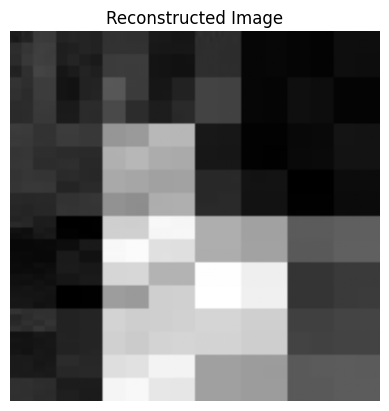

LAYER  1
Fidelity is:  tensor(0.5265, dtype=torch.float64)


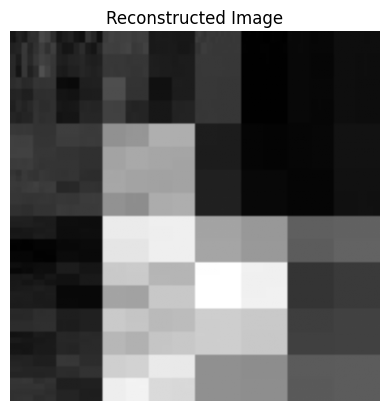

In [120]:
get_image_results_DWT(approx_states,fids, arr_shape, slices, shape)

### Target DWT (no compchi truncation ression before), 10 Layers

In [130]:
target_mps, arr_shape, slices, shape = dwt_image_to_mps(img_condense)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


-0.000000000000 [best: -0.000000000000] :  10%|▉         | 59/600 [00:01<00:15, 34.09it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([3.5903e-01, 2.1090e-01, 1.6541e-01, 5.0644e-02, 3.5297e-02, 2.5289e-02,
        2.3281e-02, 1.7433e-02, 1.2757e-02, 1.1450e-02, 1.0397e-02, 8.8590e-03,
        7.9872e-03, 7.0440e-03, 5.6027e-03, 4.3649e-03, 4.2782e-03, 3.5493e-03,
        3.2706e-03, 2.9721e-03, 2.7627e-03, 2.2853e-03, 2.0866e-03, 1.8918e-03,
        1.7679e-03, 1.6916e-03, 1.4337e-03, 1.3695e-03, 1.3177e-03, 1.2133e-03,
        1.0727e-03, 1.0571e-03, 9.9394e-04, 8.6643e-04, 7.8084e-04, 6.6901e-04,
        6.3612e-04, 5.7002e-04, 5.6402e-04, 5.1677e-04, 4.9564e-04, 4.3214e-04,
        3.9648e-04, 3.8198e-04, 3.2836e-04, 2.9540e-04, 2.8863e-04, 2.6845e-04,
        2.3407e-04, 2.1518e-04, 2.0495e-04, 1.9557e-04, 1.6955e-04, 1.6247e-04,
        1.5384e-04, 1.2728e-04, 1.0904e-04, 7.9209e-05, 7.1047e-05, 2.2153e-05,
        4.5863e-06, 2.5610e-06, 1.8322e-07, 2.6549e-08], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.20677336256366177
 bond 2 = 0.52

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+2.475081904051 [best: +2.475081904051] : : 1274it [12:59,  1.63it/s]                      


...

+0.157488243594 [best: +0.157488243594] : : 1296it [05:21,  4.04it/s]                      



 LAYER 9
initial loss = 0.91878234624083
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.60241048 0.22026355 0.32577055 0.46245081 0.54658606 0.6118717
 0.73660265 0.82820233 0.84828386 0.82884839 0.81163159 0.99836674]
New tail entropy term = 7.8212887058126075
tensor([2.9485e-12, 3.5337e-03, 3.3180e-02, 7.7137e-02, 1.1657e-01, 1.3427e-01,
        1.4142e-01, 1.3563e-01, 1.1765e-01, 9.2728e-02, 5.2420e-02, 1.4256e-02],
       dtype=torch.float64)
At init net entropy comp = 11.518984639655155 // tail loss = 0.91878234624083


+0.879352542444 [best: +0.879352542444] : : 1275it [09:05,  2.34it/s]                      


final loss = 0.8829538356340181
best val = 0.8793525424437034. Final loss = 0.8829538356340181
after updating, final loss = 0.8793525424437034
Tail entropy (normalised) per cut: [0.60188513 0.25310445 0.33378377 0.46692277 0.55254145 0.6177068
 0.74602052 0.84235376 0.85700367 0.83964578 0.81239273 0.99837212]
New tail entropy term = 7.921732956032528
tensor([2.9455e-12, 3.5341e-03, 3.3202e-02, 7.6967e-02, 1.1214e-01, 1.2909e-01,
        1.3216e-01, 1.2474e-01, 1.1193e-01, 8.9085e-02, 5.2252e-02, 1.4255e-02],
       dtype=torch.float64)
After opt: net entropy comp = 11.207316718907027 // tail loss = 0.8793525424437034
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.846204191577943
 error from singular value truncation ~ (0.00017666516051340064-2.2807363228521256e-16j), cut from max bond 126 to 88. sv cutoff = 0.0001
 new max bond = 88
norm = (1+2.623369034347343e-16j)
2. Central schmidt coefficients = tensor([8.5036e-01, 2.5202e-02, 1.0650

+0.150078972284 [best: +0.150078972284] : : 1214it [04:47,  4.23it/s]                      


LAYER  0
Fidelity is:  tensor(0.5240, dtype=torch.float64)


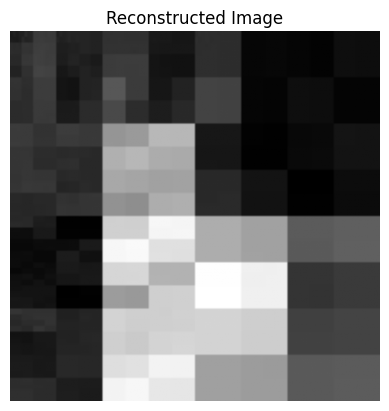

LAYER  1
Fidelity is:  tensor(0.5265, dtype=torch.float64)


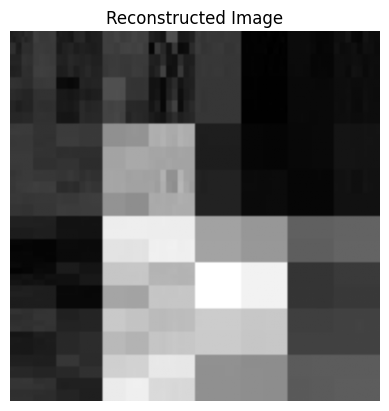

LAYER  2
Fidelity is:  tensor(0.5262, dtype=torch.float64)


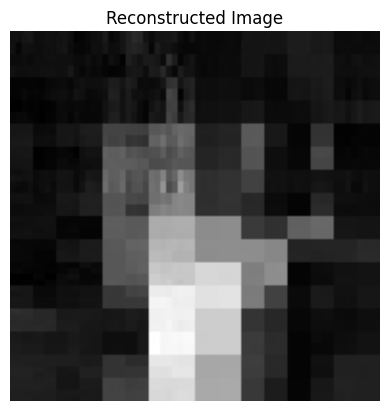

LAYER  3
Fidelity is:  tensor(0.7119, dtype=torch.float64)


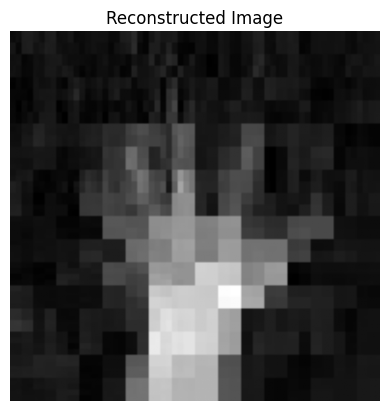

LAYER  4
Fidelity is:  tensor(0.7674, dtype=torch.float64)


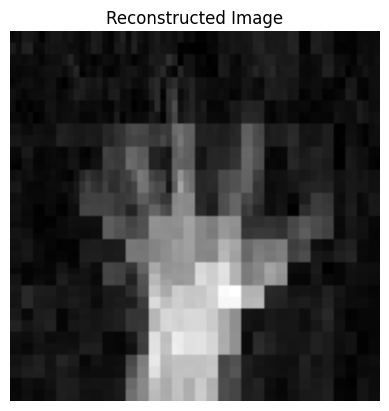

LAYER  5
Fidelity is:  tensor(0.7880, dtype=torch.float64)


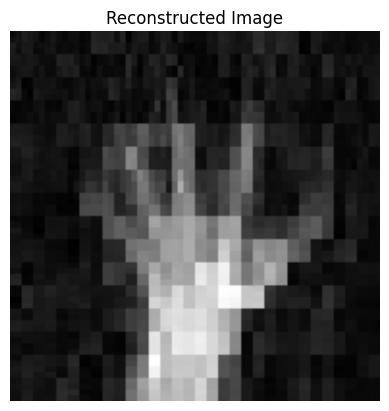

LAYER  6
Fidelity is:  tensor(0.8013, dtype=torch.float64)


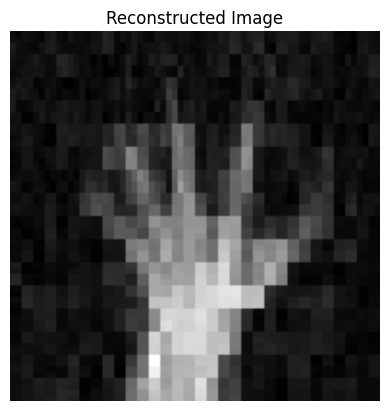

LAYER  7
Fidelity is:  tensor(0.8202, dtype=torch.float64)


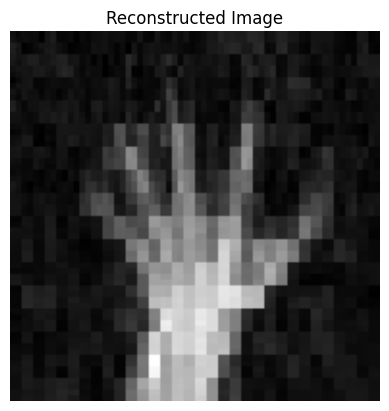

LAYER  8
Fidelity is:  tensor(0.8332, dtype=torch.float64)


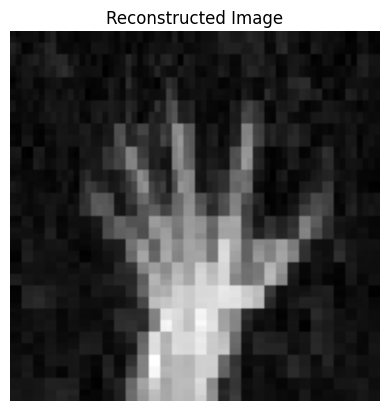

LAYER  9
Fidelity is:  tensor(0.8411, dtype=torch.float64)


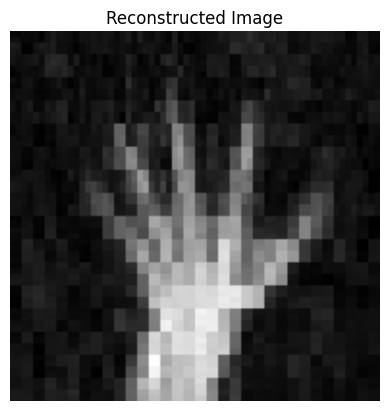

In [131]:
get_image_results_DWT(approx_states,fids, arr_shape, slices, shape)

C:\Users\archi\AppData\Local\Temp\ipykernel_24796\71621303.py:2239: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in qc.data:


fidelity of the non-parametrised circuit vs chi2 state = 0.9999999999999998


+0.000000000000 [best: +0.000000000000] :  21%|██        | 126/600 [00:02<00:08, 56.85it/s]


Archie Testing: should draw here


C:\Users\archi\AppData\Local\Temp\ipykernel_24796\71621303.py:2474: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')
C:\Users\archi\AppData\Local\Temp\ipykernel_24796\71621303.py:2475: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')


Fidelity of param circ with pre-param = 0.9999999999999498
Fidelity of param circ with final_layer = 0.9999999999999448
('k0', 'k1', 'k2', 'k3', 'k4', 'k5', 'k6', 'k7', 'k8', 'k9', 'k10', 'k11', 'k12', 'k13')
Loss using final state = 0.15379586438478876
Fidelity of param final circ with final layer = 0.9999999999999434


C:\Users\archi\AppData\Local\Temp\ipykernel_24796\71621303.py:2549: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')


Loss using final state = 0.15379586623263652


  0%|          | 0/500 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:1523: OptimizeWarning: Unknown solver options: lr
  self.res = minimize(
+0.110830438221 [best: +0.110830438221] : : 501it [26:14,  3.14s/it]                       


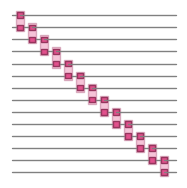

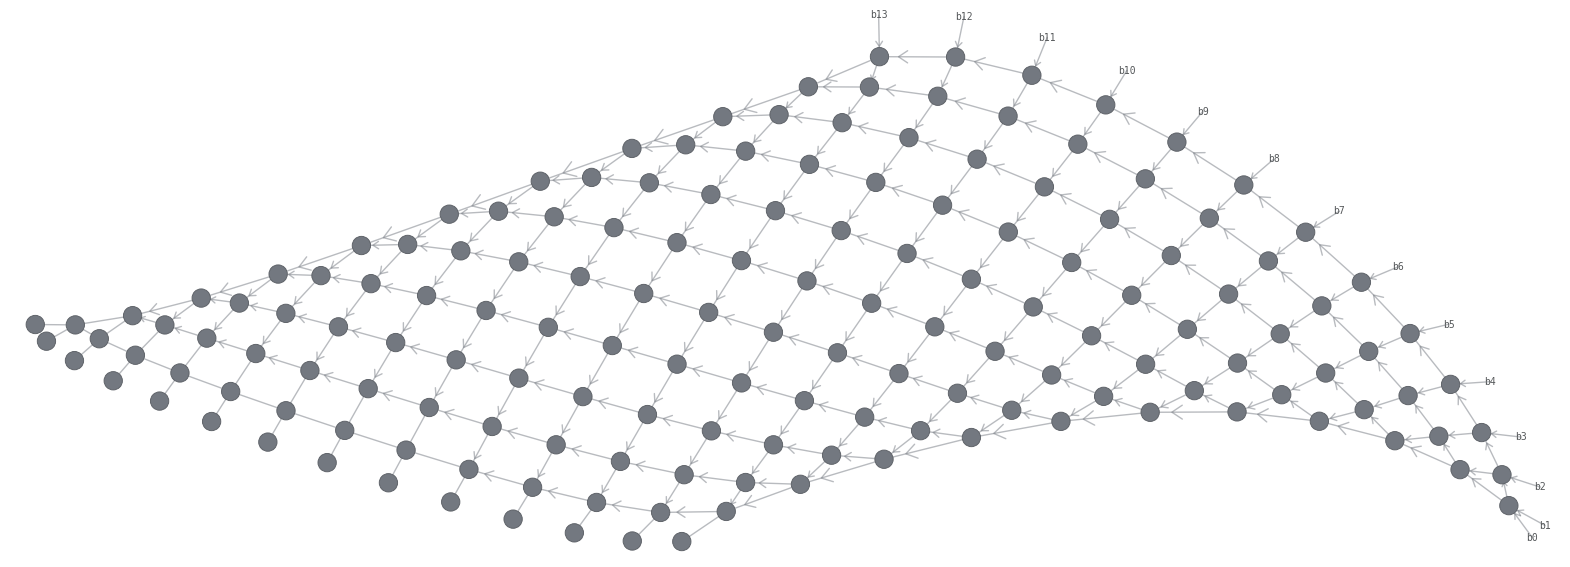

params = {14: tensor([-0.0489,  0.7867, -0.1754, -2.0179, -0.3154, -0.8639,  0.0124,  0.4024,
        -0.0499, -0.4765, -0.8352, -0.4276, -1.6159,  1.5331, -1.6102],
       dtype=torch.float64), 15: tensor([ 0.0298, -0.3979,  0.9623,  0.0773, -0.0270, -1.2033, -0.7533,  0.5323,
         0.0413, -0.0500, -0.5347,  0.3939, -0.0311,  1.6079, -1.5622],
       dtype=torch.float64), 16: tensor([ 0.0737,  0.5572,  0.3084,  2.3993,  0.0316, -1.1595,  0.2620,  0.1099,
         0.0131, -0.2189, -0.5081,  0.3794, -4.1379,  1.5179, -1.5861],
       dtype=torch.float64), 17: tensor([ 1.2233,  1.9651,  0.3651,  1.7010,  0.1878, -1.6241,  0.5003,  0.4762,
         0.8818,  1.3146, -0.3904, -1.6424, -0.0307,  1.5985, -0.9589],
       dtype=torch.float64), 18: tensor([ 0.5902,  1.8587,  0.1771,  1.5184,  1.7109, -1.6773, -0.6746,  0.2959,
        -0.0507,  1.3513,  1.1276, -0.4987, -1.6158,  0.3050, -1.6748],
       dtype=torch.float64), 19: tensor([ 0.8907,  0.4360,  1.6884,  0.9497,  0.8541, -0.2207,

In [132]:
L=10
trained_tn = SCS_all(target_mps, disentangled_mps = mps_states[L-1], param_set = param_set[:L], verbose=True)

In [133]:
lastlayeroptimizedtn=trained_tn.copy()
lastlayeroptimizedtn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

In [134]:
lastlayeroptimizedtn.contract(all)

Tensor(shape=(2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2), inds=('b0', 'b1', 'b2', 'b3', 'b4', 'b5', 'b6', 'b7', 'b8', 'b9', 'b10', 'b11', 'b12', 'b13'), tags=oset(['SU4', 'GATE_0', 'I0', 'I1', 'GATE_1', 'I2', 'GATE_2', 'I3', 'GATE_3', 'I4', 'GATE_4', 'I5', 'GATE_5', 'I6', 'GATE_6', 'I7', 'GATE_7', 'I8', 'GATE_8', 'I9', 'GATE_9', 'I10', 'GATE_10', 'I11', 'GATE_11', 'I12', 'GATE_12', 'I13', 'GATE_13', 'GATE_14', 'GATE_15', 'GATE_16', 'GATE_17', 'GATE_18', 'GATE_19', 'GATE_20', 'GATE_21', 'GATE_22', 'GATE_23', 'GATE_24', 'GATE_25', 'GATE_26', 'GATE_27', 'GATE_28', 'GATE_29', 'GATE_30', 'GATE_31', 'GATE_32', 'GATE_33', 'GATE_34', 'GATE_35', 'GATE_36', 'GATE_37', 'GATE_38', 'GATE_39', 'GATE_40', 'GATE_41', 'GATE_42', 'GATE_43', 'GATE_44', 'GATE_45', 'GATE_46', 'GATE_47', 'GATE_48', 'GATE_49', 'GATE_50', 'GATE_51', 'GATE_52', 'GATE_53', 'GATE_54', 'GATE_55', 'GATE_56', 'GATE_57', 'GATE_58', 'GATE_59', 'GATE_60', 'GATE_61', 'GATE_62', 'GATE_63', 'GATE_64', 'GATE_65', 'GATE_66', 'GATE_67', 'GATE_68', 'GATE_69', 'GATE_70', 'GATE_71', 'GATE_72', 'GATE_73', 'GATE_74', 'GATE_75', 'GATE_76', 'GATE_77', 'GATE_78', 'GATE_79', 'GATE_80', 'GATE_81', 'GATE_82', 'GATE_83', 'GATE_84', 'GATE_85', 'GATE_86', 'GATE_87', 'GATE_88', 'GATE_89', 'GATE_90', 'GATE_91', 'GATE_92', 'GATE_93', 'GATE_94', 'GATE_95', 'GATE_96', 'GATE_97', 'GATE_98', 'GATE_99', 'GATE_100', 'GATE_101', 'GATE_102', 'GATE_103', 'GATE_104', 'GATE_105', 'GATE_106', 'GATE_107', 'GATE_108', 'GATE_109', 'GATE_110', 'GATE_111', 'GATE_112', 'GATE_113', 'GATE_114', 'GATE_115', 'GATE_116', 'GATE_117', 'GATE_118', 'GATE_119', 'GATE_120', 'GATE_121', 'GATE_122', 'GATE_123', 'GATE_124', 'GATE_125', 'GATE_126', 'GATE_127', 'GATE_128', 'GATE_129']))

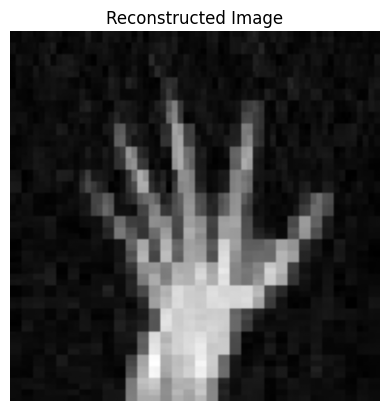

In [136]:
#Reconstruct image
vec=lastlayeroptimizedtn.contract(all).data.detach().numpy().reshape(-1)

# Truncate/pad to match the original array size
vec = vec[:np.prod(arr_shape)]          # truncate if MPS compress lost some entries
vec = vec.reshape(arr_shape)            # reshape to original DWT array

# Convert back to coeffs
coeffs = pywt.array_to_coeffs(vec, slices, output_format='wavedec2')

# Inverse DWT
img_rec = pywt.waverec2(coeffs, wavelet='haar')

# Crop to original image shape
img_rec = np.abs(img_rec[:shape[0], :shape[1]])
plt.imshow(img_rec, cmap='gray')
plt.title("Reconstructed Image")
plt.axis('off')
plt.show()

Hmm this didnt seem to help that much really.

### CHEST condensed, chi=64, 4 Layers

from  image analysis doc chi=64 seems to have no effect on image clarity so i will start with that to get better clarity.

In [5]:
from skimage.transform import resize
# Load the image
imgchest = mpimg.imread("chestxray.jpg")[:, :, 0]
imgchest_condense = resize(imgchest, (128, 128), anti_aliasing=True)

In [10]:
target_mps=image_to_mps(imgchest_condense)
target_mps.compress(max_bond = 64)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=4,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:36: UserWarning: Couldn't import `kahypar` - skipping from default hyper optimizer and using basic `labels` method instead. `kahypar` is highly recommended for the best quality contraction paths.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:75: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality hyper-optimization.
  warnings.warn(
c:\Users\archi\anaconda3\envs\new

Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  11%|█         | 66/600 [00:01<00:10, 53.15it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([6.7141e-01, 2.0216e-01, 7.1984e-02, 2.7792e-02, 7.7303e-03, 4.2008e-03,
        2.9864e-03, 2.4373e-03, 1.4475e-03, 1.1552e-03, 1.0847e-03, 9.9862e-04,
        7.8219e-04, 6.5959e-04, 4.8920e-04, 3.9114e-04, 3.3202e-04, 2.8105e-04,
        2.2546e-04, 2.0844e-04, 1.7764e-04, 1.5071e-04, 1.2006e-04, 1.0138e-04,
        8.5750e-05, 8.1298e-05, 7.4321e-05, 5.6140e-05, 4.6399e-05, 4.2443e-05,
        3.5432e-05, 3.0578e-05, 2.6992e-05, 2.3762e-05, 2.1934e-05, 1.6408e-05,
        1.4881e-05, 1.4053e-05, 1.2059e-05, 1.0600e-05, 9.3078e-06, 8.8075e-06,
        7.6239e-06, 6.8238e-06, 6.0980e-06, 4.6306e-06, 4.0744e-06, 3.7690e-06,
        3.5269e-06, 3.4174e-06, 2.9050e-06, 2.7728e-06, 2.2593e-06, 1.8364e-06,
        1.6341e-06, 1.4113e-06, 1.3026e-06, 1.0854e-06, 7.9372e-07, 6.9413e-07,
        6.3181e-07, 4.2298e-07, 3.9909e-07, 3.1560e-07], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.49770890203781265
 bond 2 = 0.80

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.602725542005 [best: +0.602725542005] :   4%|▍         | 36/800 [00:14<04:58,  2.56it/s]


...

+0.168685308601 [best: +0.168685308601] :  54%|█████▍    | 433/800 [01:33<01:19,  4.62it/s]



 LAYER 3
initial loss = 0.30256562200793335
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.74339941 0.25590857 0.49893127 0.61125317 0.59884285 0.57720252
 0.60859704 0.69374535 0.72048516 0.65355882 0.44569282 0.01234191]
New tail entropy term = 6.419958887688783
tensor([3.3592e-12, 1.7647e-02, 2.9281e-02, 3.1154e-02, 3.1000e-02, 3.9963e-02,
        5.0026e-02, 4.6496e-02, 3.3646e-02, 1.7758e-02, 5.1150e-03, 4.8137e-04],
       dtype=torch.float64)
At init net entropy comp = 8.30465152039356 // tail loss = 0.30256562200793335


+0.270662611839 [best: +0.270662611839] : : 1270it [05:24,  3.91it/s]                      


final loss = 0.2720951871136129
best val = 0.27066261183898976. Final loss = 0.2720951871136129
after updating, final loss = 0.27066261183898976
Tail entropy (normalised) per cut: [0.79531482 0.25894084 0.5062679  0.49485298 0.59662485 0.63549388
 0.67861496 0.73000691 0.74224414 0.64986831 0.44901246 0.11951312]
New tail entropy term = 6.656755165472197
tensor([3.8899e-12, 1.5810e-02, 2.3497e-02, 2.3756e-02, 3.0944e-02, 3.7066e-02,
        4.3855e-02, 4.2403e-02, 3.0184e-02, 1.7599e-02, 5.0973e-03, 4.5016e-04],
       dtype=torch.float64)
After opt: net entropy comp = 6.994899722546906 // tail loss = 0.27066261183898976
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9409746053908652
 error from singular value truncation ~ (0.00025787402754473554+1.5348806931120239e-16j), cut from max bond 64 to 42. sv cutoff = 0.0001
 new max bond = 42
norm = (0.9999999999999994-1.1408771469862904e-16j)
2. Central schmidt coefficients = tensor([8.2812e-0

+0.056917567948 [best: +0.056917371268] : : 1236it [04:49,  4.27it/s]                      


LAYER  0
Fidelity is:  tensor(0.8006, dtype=torch.float64)


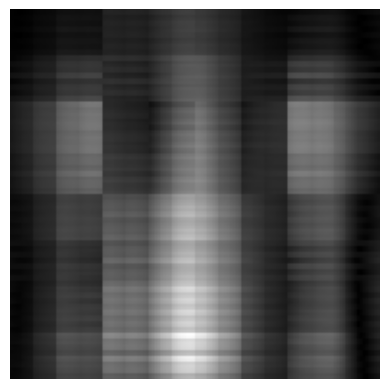

LAYER  1
Fidelity is:  tensor(0.8469, dtype=torch.float64)


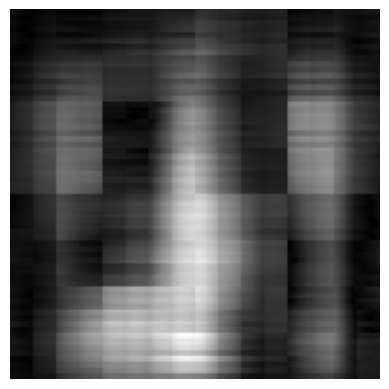

LAYER  2
Fidelity is:  tensor(0.9116, dtype=torch.float64)


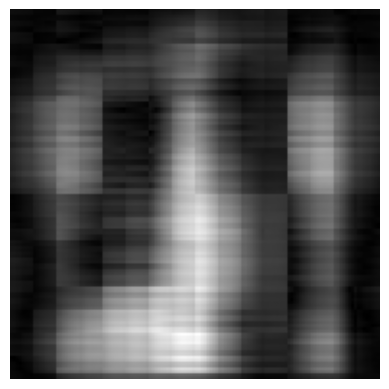

LAYER  3
Fidelity is:  tensor(0.9275, dtype=torch.float64)


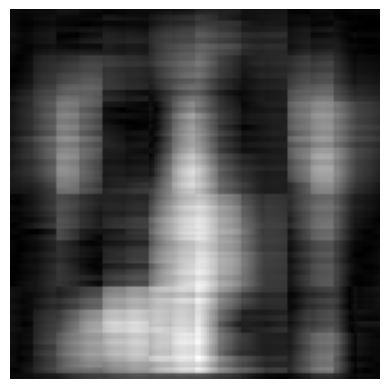

In [14]:
get_image_results(approx_states,fids,128,128)

yeah okay still blurry but at least fidelity number is better. And this is only 4 layers, not the full 10 and we are yet to do any global optimisation yet aswell.

### CHEST condensed, chi=64, 10 Layers

In [15]:
target_mps=image_to_mps(imgchest_condense)
target_mps.compress(max_bond = 64)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   8%|▊         | 46/600 [00:00<00:09, 56.23it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([6.7141e-01, 2.0216e-01, 7.1984e-02, 2.7792e-02, 7.7303e-03, 4.2008e-03,
        2.9864e-03, 2.4373e-03, 1.4475e-03, 1.1552e-03, 1.0847e-03, 9.9862e-04,
        7.8219e-04, 6.5959e-04, 4.8920e-04, 3.9114e-04, 3.3202e-04, 2.8105e-04,
        2.2546e-04, 2.0844e-04, 1.7764e-04, 1.5071e-04, 1.2006e-04, 1.0138e-04,
        8.5750e-05, 8.1298e-05, 7.4321e-05, 5.6140e-05, 4.6399e-05, 4.2443e-05,
        3.5432e-05, 3.0578e-05, 2.6992e-05, 2.3762e-05, 2.1934e-05, 1.6408e-05,
        1.4881e-05, 1.4053e-05, 1.2059e-05, 1.0600e-05, 9.3078e-06, 8.8075e-06,
        7.6239e-06, 6.8238e-06, 6.0980e-06, 4.6306e-06, 4.0744e-06, 3.7690e-06,
        3.5269e-06, 3.4174e-06, 2.9050e-06, 2.7728e-06, 2.2593e-06, 1.8364e-06,
        1.6341e-06, 1.4113e-06, 1.3026e-06, 1.0854e-06, 7.9372e-07, 6.9413e-07,
        6.3181e-07, 4.2298e-07, 3.9909e-07, 3.1560e-07], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.49770890203781265
 bond 2 = 0.80

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.390045331419 [best: +0.390045331419] : : 1301it [08:45,  2.47it/s]                      


...

+0.027968388736 [best: +0.027968388196] :  79%|███████▉  | 635/800 [02:33<00:39,  4.13it/s]



 LAYER 9
initial loss = 0.1267024486328907
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.90984543 0.21435212 0.23583119 0.48706456 0.5215544  0.62765344
 0.74100513 0.82820279 0.79859857 0.77927989 0.26956077 0.00288464]
New tail entropy term = 6.415832939960187
tensor([2.6070e-12, 3.3016e-07, 3.8735e-03, 9.3260e-03, 1.5690e-02, 2.0530e-02,
        2.2868e-02, 2.1549e-02, 1.7671e-02, 1.1308e-02, 3.7493e-03, 1.3744e-04],
       dtype=torch.float64)
At init net entropy comp = 9.097179852586091 // tail loss = 0.1267024486328907


+0.125581806779 [best: +0.124803906662] : : 1251it [05:21,  3.90it/s]                      


final loss = 0.12591480218743767
best val = 0.12480390666159424. Final loss = 0.12591480218743767
after updating, final loss = 0.12480390666159424
Tail entropy (normalised) per cut: [0.90328505 0.30659704 0.2351228  0.48756795 0.52644588 0.62518645
 0.75357008 0.83906863 0.79852884 0.77920522 0.27292982 0.01253003]
New tail entropy term = 6.540037783821014
tensor([2.6600e-12, 8.1009e-06, 3.8647e-03, 9.2901e-03, 1.5700e-02, 2.0532e-02,
        2.1852e-02, 2.0731e-02, 1.7628e-02, 1.1308e-02, 3.7519e-03, 1.3787e-04],
       dtype=torch.float64)
After opt: net entropy comp = 8.96688647358335 // tail loss = 0.12480390666159424
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9680453965074226
 error from singular value truncation ~ (0.0001298955743779251+2.1945239088058855e-17j), cut from max bond 55 to 34. sv cutoff = 0.0001
 new max bond = 34
norm = (0.9999999999999994+3.8202456470589845e-17j)
2. Central schmidt coefficients = tensor([6.2098e-0

+0.027162293226 [best: +0.027162293226] :  64%|██████▍   | 512/800 [01:50<01:02,  4.64it/s]


LAYER  0
Fidelity is:  tensor(0.8006, dtype=torch.float64)


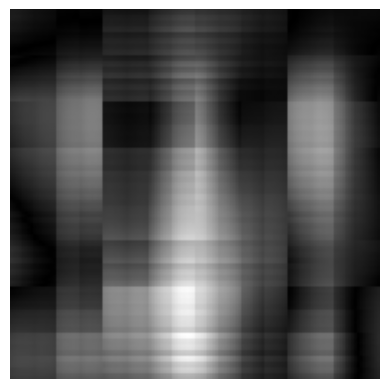

LAYER  1
Fidelity is:  tensor(0.8869, dtype=torch.float64)


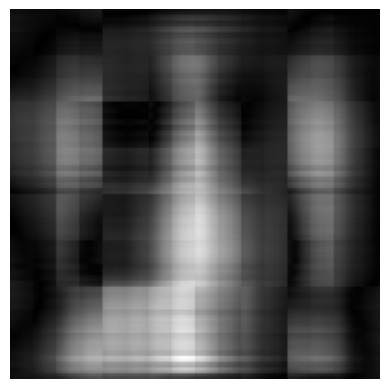

LAYER  2
Fidelity is:  tensor(0.9333, dtype=torch.float64)


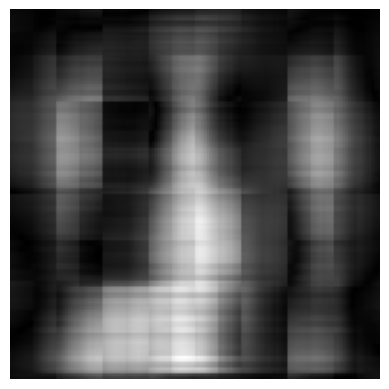

LAYER  3
Fidelity is:  tensor(0.9464, dtype=torch.float64)


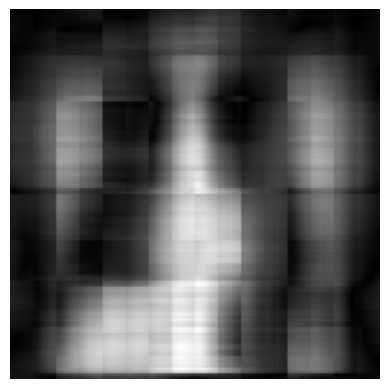

LAYER  4
Fidelity is:  tensor(0.9534, dtype=torch.float64)


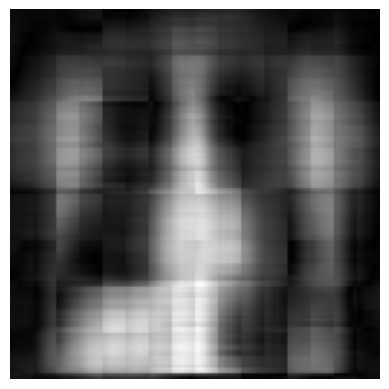

LAYER  5
Fidelity is:  tensor(0.9603, dtype=torch.float64)


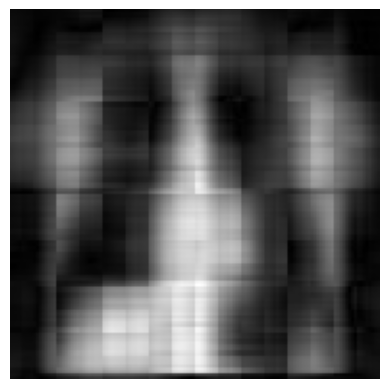

LAYER  6
Fidelity is:  tensor(0.9650, dtype=torch.float64)


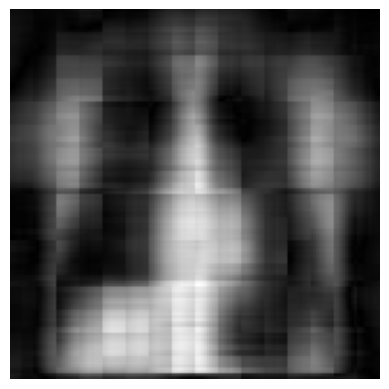

LAYER  7
Fidelity is:  tensor(0.9682, dtype=torch.float64)


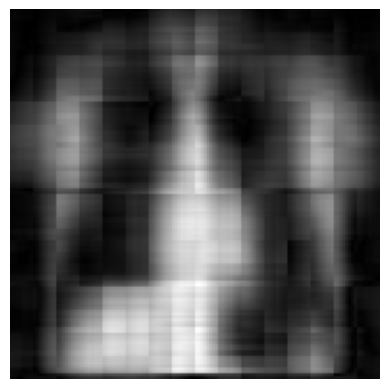

LAYER  8
Fidelity is:  tensor(0.9707, dtype=torch.float64)


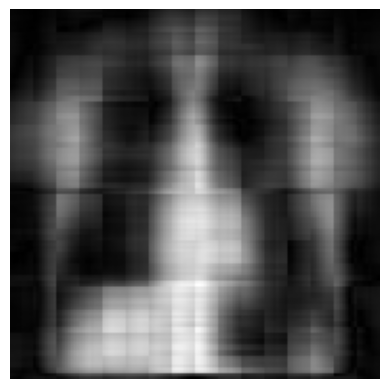

LAYER  9
Fidelity is:  tensor(0.9720, dtype=torch.float64)


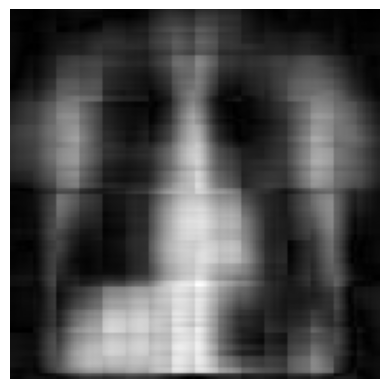

In [16]:
get_image_results(approx_states,fids,128,128)

C:\Users\archi\AppData\Local\Temp\ipykernel_904\71621303.py:2239: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in qc.data:


fidelity of the non-parametrised circuit vs chi2 state = 1.0000000000000027


+0.000000000000 [best: +0.000000000000] :  14%|█▍        | 86/600 [00:01<00:09, 56.35it/s]


Archie Testing: should draw here


C:\Users\archi\AppData\Local\Temp\ipykernel_904\71621303.py:2474: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')


...

C:\Users\archi\AppData\Local\Temp\ipykernel_904\71621303.py:2475: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')


Fidelity of param circ with final_layer = 0.9999999999999408
('k0', 'k1', 'k2', 'k3', 'k4', 'k5', 'k6', 'k7', 'k8', 'k9', 'k10', 'k11', 'k12', 'k13')


C:\Users\archi\AppData\Local\Temp\ipykernel_904\71621303.py:2482: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Copy.cpp:309.)
  npsi = applied_uni.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
C:\Users\archi\AppData\Local\Temp\ipykernel_904\71621303.py:2549: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')


Loss using final state = 0.03195460195919919
Fidelity of param final circ with final layer = 0.9999999999999412
Loss using final state = 0.03195460203816858


  0%|          | 0/500 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:1523: OptimizeWarning: Unknown solver options: lr
  self.res = minimize(
+0.019463515364 [best: +0.019463515364] : : 501it [45:02,  5.39s/it]                       


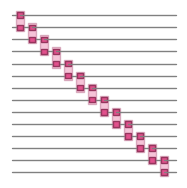

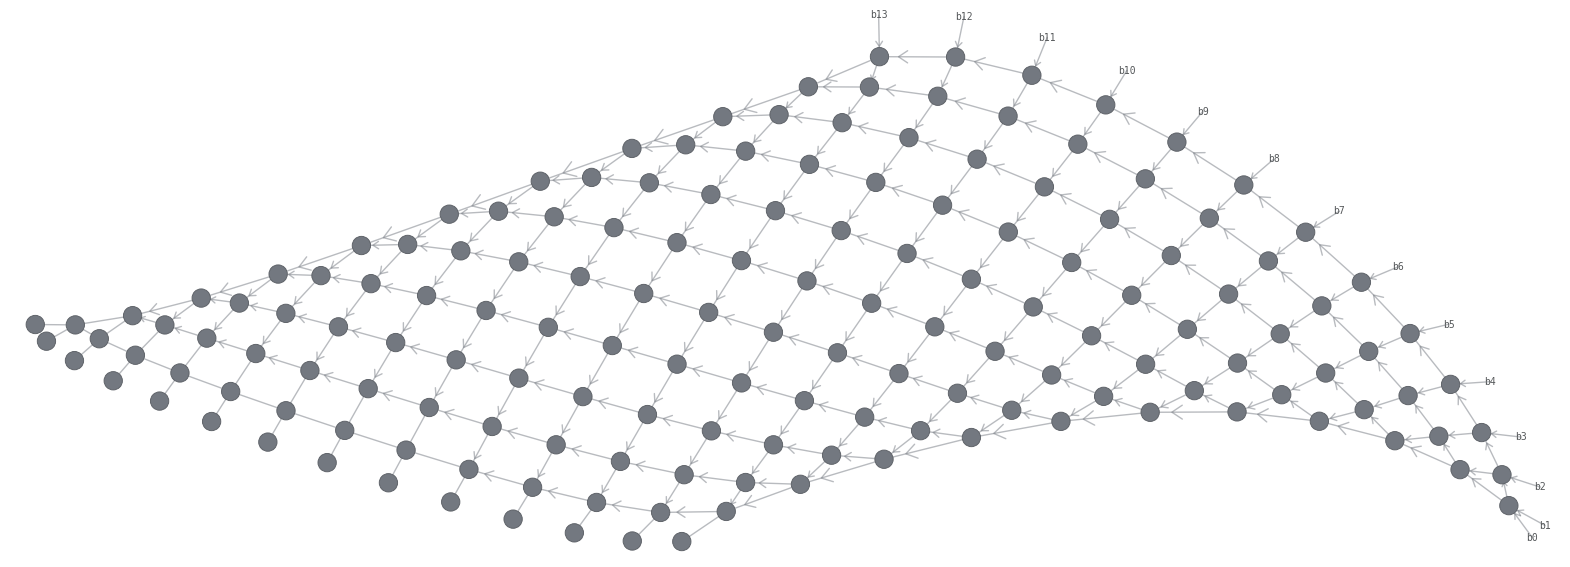

params = {14: tensor([-1.5036, -1.9421,  1.5483, -0.2485,  0.2881,  0.0394, -0.4951,  0.1807,
        -0.4181, -0.2930,  0.1758, -0.2542,  2.1860,  0.1816, -0.0756],
       dtype=torch.float64), 15: tensor([ 0.2805,  0.9454,  0.2007,  0.0718,  1.2277,  0.1638,  0.1681,  0.1674,
        -0.2094, -0.2572,  0.6107,  0.4050,  2.6558, -0.0207, -0.4006],
       dtype=torch.float64), 16: tensor([ 2.1258e-01, -2.1752e+00, -3.3375e-01,  3.3766e+00, -2.5394e-02,
        -3.3236e-02,  6.0904e-04, -1.1862e+00, -8.4639e-01, -1.7597e+00,
        -1.3951e-01,  6.2125e-01,  2.6165e-01,  3.0258e+00, -3.0812e-02],
       dtype=torch.float64), 17: tensor([-1.4503, -0.5011,  0.2406,  0.9171, -0.5474, -0.0468,  0.6199, -0.0248,
        -0.1998, -0.1404,  0.3608, -0.5296,  2.9563,  3.1380, -0.0195],
       dtype=torch.float64), 18: tensor([ 1.2570e-02, -8.3837e-01, -3.7333e-01, -1.7559e+00, -4.2965e-01,
        -2.1132e-04,  2.7213e-01, -2.2848e-01, -1.2958e+00,  1.2669e+00,
         2.5337e-01, -8.1898e-02

In [17]:
L=10
trained_tn = SCS_all(target_mps, disentangled_mps = mps_states[L-1], param_set = param_set[:L], verbose=True)

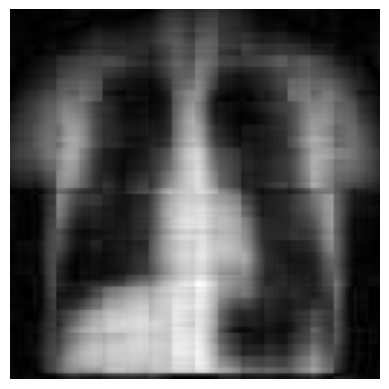

In [18]:
lastlayeroptimizedtn=trained_tn.copy()
lastlayeroptimizedtn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
approx_state_to_image(lastlayeroptimizedtn,128,128)

### JoshChest Chi=64, 10 Layers

In [19]:
joshchestimg = mpimg.imread("chest_josh_image.png")[:, :, 0]
joshchestimg_condense = resize(joshchestimg, (128, 128), anti_aliasing=True)

In [22]:
target_mps=image_to_mps(joshchestimg_condense)
target_mps.compress(max_bond = 64)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   7%|▋         | 44/600 [00:01<00:13, 41.45it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([8.3448e-01, 9.4985e-02, 4.0572e-02, 1.7869e-02, 4.9469e-03, 2.1063e-03,
        1.9283e-03, 7.1759e-04, 6.1629e-04, 3.9368e-04, 3.0337e-04, 2.1184e-04,
        1.8512e-04, 1.4962e-04, 9.1746e-05, 7.8389e-05, 5.9248e-05, 4.9985e-05,
        4.2086e-05, 3.5903e-05, 2.7066e-05, 2.0334e-05, 1.9921e-05, 1.4036e-05,
        1.2831e-05, 1.1040e-05, 1.0155e-05, 8.5199e-06, 6.9626e-06, 6.0990e-06,
        4.8083e-06, 4.6236e-06, 3.5790e-06, 2.8469e-06, 2.5958e-06, 2.3696e-06,
        1.7828e-06, 1.6594e-06, 1.2440e-06, 1.0928e-06, 1.0434e-06, 8.7045e-07,
        7.5256e-07, 7.1465e-07, 5.6207e-07, 5.2962e-07, 4.9730e-07, 3.9090e-07,
        3.5372e-07, 3.1525e-07, 3.0105e-07, 2.7065e-07, 2.3566e-07, 1.6593e-07,
        1.4180e-07, 1.2849e-07, 9.3133e-08, 8.7823e-08, 8.0812e-08, 6.7926e-08,
        6.3620e-08, 5.1925e-08, 4.7440e-08, 2.4932e-08], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.7073834006851982
 bond 2 = 0.898

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.147259254241 [best: +0.147259254241] : : 1268it [08:49,  2.40it/s]                      


...

+0.008349983787 [best: +0.008349882077] : : 1091it [04:06,  4.42it/s]                      



 LAYER 9
initial loss = 0.03156684891677641
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.00000000e+00 2.22524141e-03 3.33681605e-01 2.31819147e-01
 4.16208591e-01 5.92974250e-01 7.66863874e-01 8.60351724e-01
 7.70085312e-01 5.59827797e-01 3.09722732e-04 2.09822672e-01]
New tail entropy term = 4.744169935386397
tensor([6.7379e-13, 4.0139e-07, 2.7599e-11, 1.2359e-03, 4.4640e-03, 6.3458e-03,
        6.3592e-03, 5.8176e-03, 4.5225e-03, 2.3057e-03, 5.1558e-04, 1.5460e-07],
       dtype=torch.float64)
At init net entropy comp = 1.9710178939842777 // tail loss = 0.03156684891745021


+0.029532850328 [best: +0.029532850328] : : 1275it [04:46,  4.45it/s]                      


final loss = 0.030043634996810842
best val = 0.02953285032816977. Final loss = 0.030043634996810842
after updating, final loss = 0.02953285032816977
Tail entropy (normalised) per cut: [0.         0.27055941 0.21925678 0.26991812 0.43592547 0.60781209
 0.79642865 0.88513475 0.7971102  0.58689835 0.06999896 0.20541908]
New tail entropy term = 5.144461862056599
tensor([1.3178e-13, 1.2421e-06, 2.6583e-05, 1.2400e-03, 4.3119e-03, 5.6695e-03,
        5.7845e-03, 5.3894e-03, 4.3243e-03, 2.2778e-03, 5.0761e-04, 4.0693e-08],
       dtype=torch.float64)
After opt: net entropy comp = 2.8565805531507715 // tail loss = 0.029532850328301552
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9882115875152675
 error from singular value truncation ~ (0.00015438393809807938+1.119107530715414e-16j), cut from max bond 38 to 18. sv cutoff = 0.0001
 new max bond = 18
norm = (0.9999999999999991-2.280763265424294e-17j)
2. Central schmidt coefficients = tensor([9.907

+0.999999864958 [best: +0.999999618112] :   0%|          | 3/800 [00:01<04:47,  2.77it/s]


LAYER  0
Fidelity is:  tensor(0.8987, dtype=torch.float64)


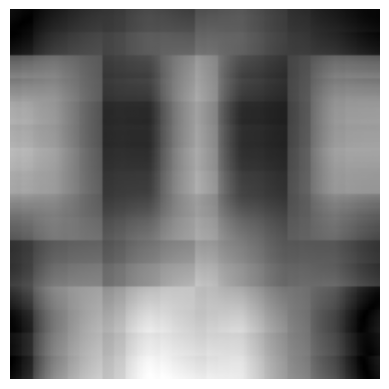

LAYER  1
Fidelity is:  tensor(0.9618, dtype=torch.float64)


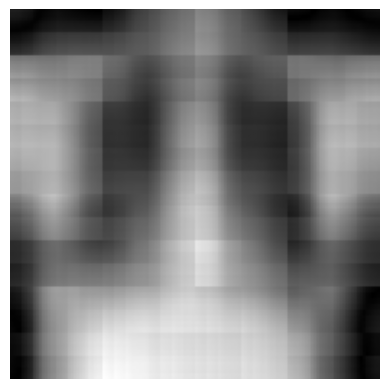

LAYER  2
Fidelity is:  tensor(0.9805, dtype=torch.float64)


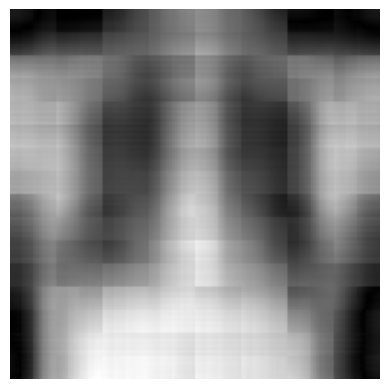

LAYER  3
Fidelity is:  tensor(0.9831, dtype=torch.float64)


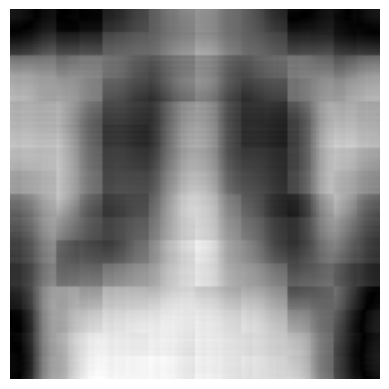

LAYER  4
Fidelity is:  tensor(0.9851, dtype=torch.float64)


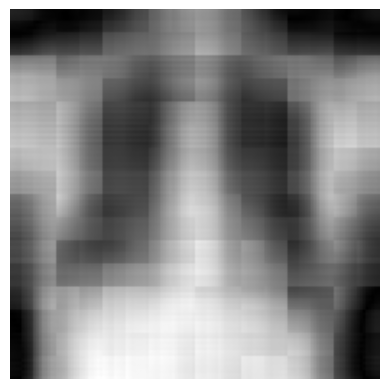

LAYER  5
Fidelity is:  tensor(0.9865, dtype=torch.float64)


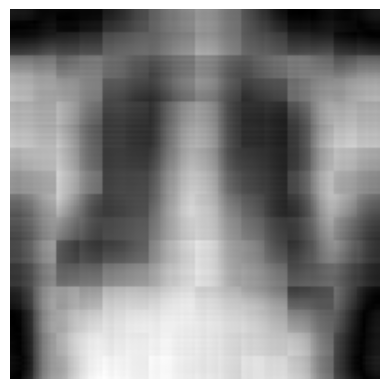

LAYER  6
Fidelity is:  tensor(0.9881, dtype=torch.float64)


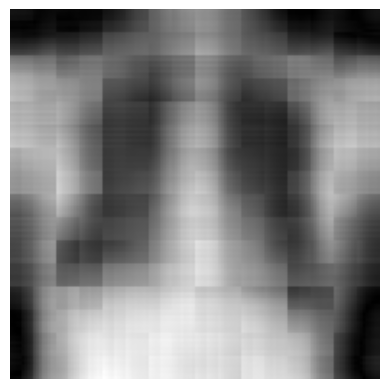

LAYER  7
Fidelity is:  tensor(0.9889, dtype=torch.float64)


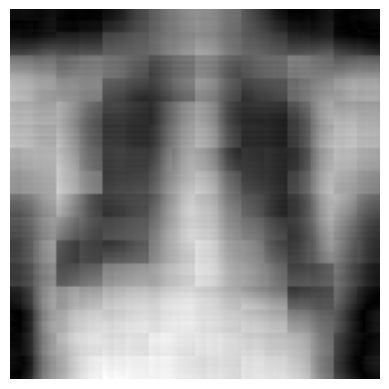

LAYER  8
Fidelity is:  tensor(0.9904, dtype=torch.float64)


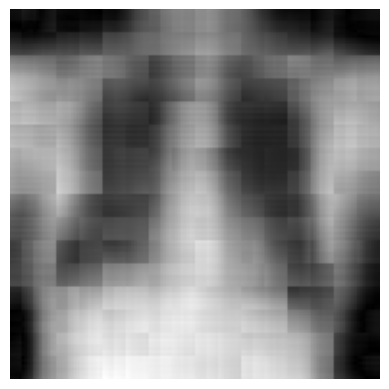

LAYER  9
Fidelity is:  tensor(0.9916, dtype=torch.float64)


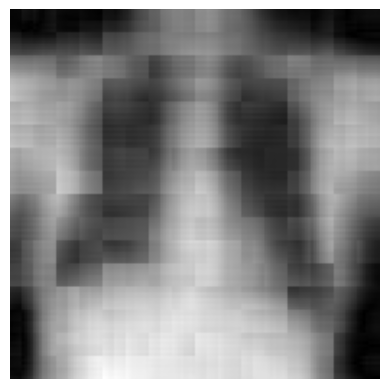

In [23]:
get_image_results(approx_states,fids,128,128)

C:\Users\archi\AppData\Local\Temp\ipykernel_904\71621303.py:2239: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in qc.data:


fidelity of the non-parametrised circuit vs chi2 state = 1.0000000000000013


+0.000000000000 [best: +0.000000000000] :  14%|█▎        | 82/600 [00:01<00:09, 52.43it/s]


Archie Testing: should draw here


C:\Users\archi\AppData\Local\Temp\ipykernel_904\71621303.py:2474: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')
C:\Users\archi\AppData\Local\Temp\ipykernel_904\71621303.py:2475: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')


Fidelity of param circ with pre-param = 0.9999999999998845
Fidelity of param circ with final_layer = 0.9999999999998831
('k0', 'k1', 'k2', 'k3', 'k4', 'k5', 'k6', 'k7', 'k8', 'k9', 'k10', 'k11', 'k12', 'k13')
Loss using final state = 0.011788686480124322
Fidelity of param final circ with final layer = 0.9999999999998848


C:\Users\archi\AppData\Local\Temp\ipykernel_904\71621303.py:2549: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')


Loss using final state = 0.011788686459888953


  0%|          | 0/500 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:1523: OptimizeWarning: Unknown solver options: lr
  self.res = minimize(
+0.006890285442 [best: +0.006890285442] : : 501it [27:28,  3.29s/it]                       


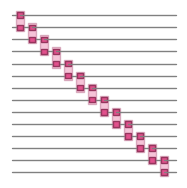

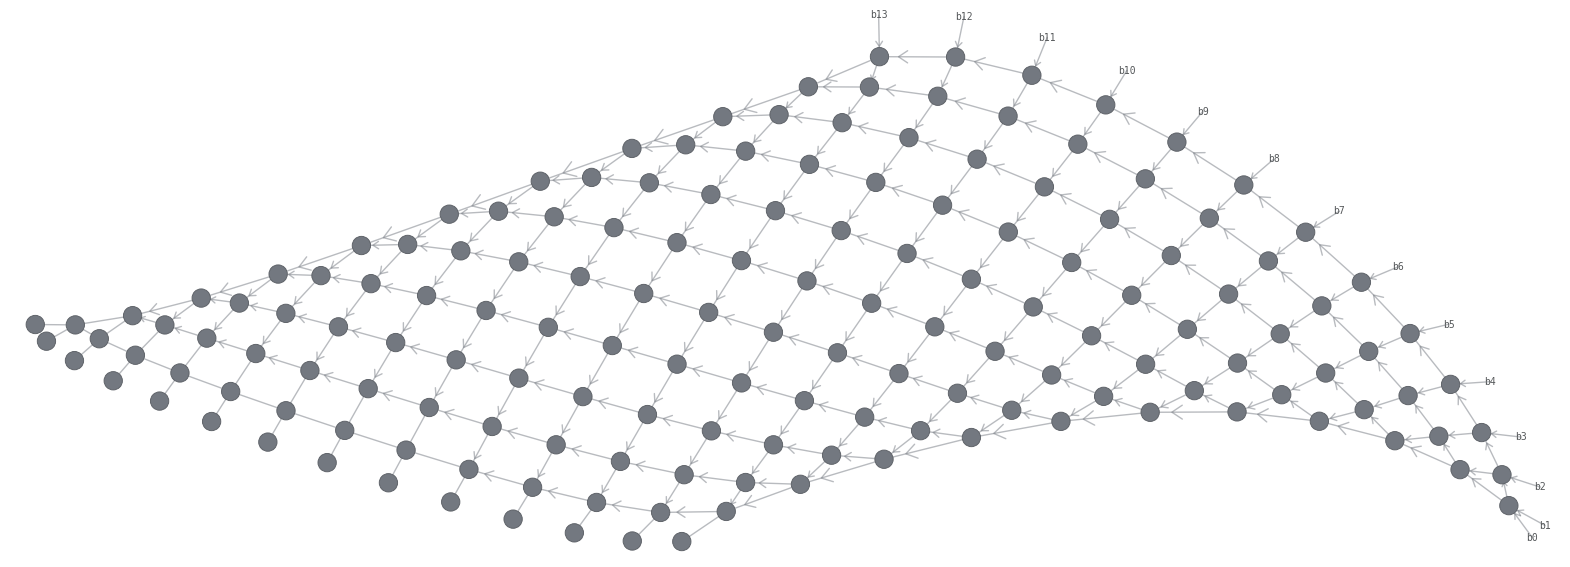

params = {14: tensor([ 1.2404,  2.2541, -0.0701, -0.2703,  1.1773, -3.3758,  0.0595, -0.0500,
         0.3634, -0.3374, -0.5746, -0.5358,  1.2012,  2.8549, -1.1885],
       dtype=torch.float64), 15: tensor([ 0.3781, -0.7718, -0.6828, -1.5505, -0.2929, -1.6553,  0.1097,  0.5778,
         0.3300,  0.8245, -0.5824, -0.0401,  0.3162, -0.0776, -2.5775],
       dtype=torch.float64), 16: tensor([ 1.1008,  1.5368,  0.4220,  0.4792, -1.0554, -0.6513, -0.9474,  0.3166,
        -0.5787, -0.3990, -0.3618,  0.3024, -3.2002,  2.6984, -3.2849],
       dtype=torch.float64), 17: tensor([ 1.2721,  0.8282,  0.0538, -1.2140, -0.7292, -0.0282,  0.2569,  0.3410,
         0.0723, -0.0477, -0.3653, -0.1631, -0.2339,  0.0688, -0.0478],
       dtype=torch.float64), 18: tensor([ 0.5452, -0.0540,  0.4545, -0.2453, -2.0469, -1.5363, -0.6307,  0.0331,
         0.7921, -0.5903,  0.0761, -0.3042, -0.0452,  3.1361, -3.0952],
       dtype=torch.float64), 19: tensor([ 0.7618,  0.3650,  1.2762,  0.0566, -0.3391, -1.2609,

In [25]:
L=10
trained_tn = SCS_all(target_mps, disentangled_mps = mps_states[L-1], param_set = param_set[:L], verbose=True)

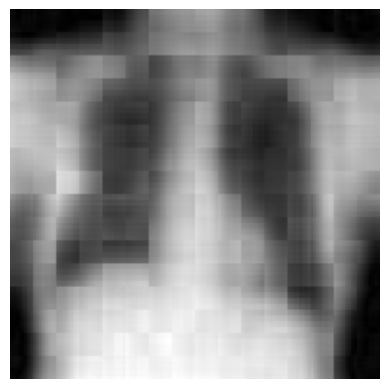

In [26]:
lastlayeroptimizedtn=trained_tn.copy()
lastlayeroptimizedtn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
approx_state_to_image(lastlayeroptimizedtn,128,128)

### Simple wrist image, chi=64, 10 Layers

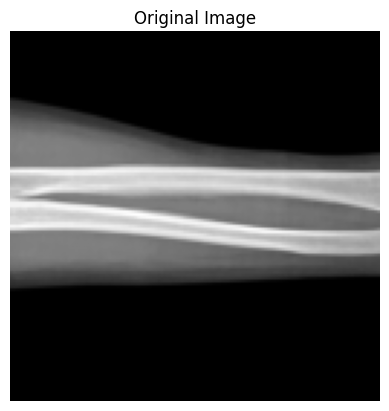

In [30]:
simplewristimg = mpimg.imread("simple_wrist.png")[:, :, 0]
simplewristimg_condense = resize(simplewristimg, (128, 128), anti_aliasing=True)
plt.imshow(simplewristimg_condense, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

In [31]:
target_mps=image_to_mps(simplewristimg_condense)
target_mps.compress(max_bond = 64)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   8%|▊         | 51/600 [00:02<00:26, 20.50it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([9.7287e-01, 1.8229e-02, 4.6485e-03, 2.4801e-03, 8.7853e-04, 3.8003e-04,
        1.8041e-04, 1.1920e-04, 6.9107e-05, 4.0952e-05, 2.7432e-05, 1.9029e-05,
        1.1285e-05, 6.6766e-06, 5.0420e-06, 4.2174e-06, 3.6289e-06, 3.3502e-06,
        2.5331e-06, 2.1297e-06, 2.0477e-06, 1.5964e-06, 1.5625e-06, 1.4070e-06,
        1.1824e-06, 1.0878e-06, 9.5809e-07, 8.3408e-07, 7.8281e-07, 6.5563e-07,
        6.3115e-07, 5.4004e-07, 4.9909e-07, 4.2665e-07, 3.8082e-07, 3.7342e-07,
        3.2878e-07, 2.7969e-07, 2.5576e-07, 2.5146e-07, 2.0064e-07, 1.8906e-07,
        1.7602e-07, 1.6152e-07, 1.5071e-07, 1.2529e-07, 1.2221e-07, 1.1387e-07,
        1.0966e-07, 9.8563e-08, 8.9633e-08, 7.9200e-08, 7.2823e-08, 6.7130e-08,
        6.3588e-08, 5.9657e-08, 5.2798e-08, 4.7455e-08, 4.0855e-08, 3.7471e-08,
        3.5220e-08, 2.5839e-08, 2.0041e-08, 1.6662e-08], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.9468376979868232
 bond 2 = 0.941

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.100709126809 [best: +0.100705462207] : : 1286it [14:16,  1.50it/s]                      


...

+0.007443379707 [best: +0.007443379707] :  54%|█████▍    | 432/800 [01:43<01:28,  4.18it/s]



 LAYER 9
initial loss = 0.03093934920180763
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [4.81132224e-01 2.59492878e-01 3.83871480e-01 5.60474615e-01
 6.96729439e-01 8.42446653e-01 9.18247900e-01 9.35174108e-01
 2.51938360e-05 3.99225218e-02 7.52178695e-03 1.43001369e-01]
New tail entropy term = 5.26804016778806
tensor([2.6174e-12, 6.9320e-04, 3.4443e-03, 5.0879e-03, 5.8236e-03, 5.8971e-03,
        5.2190e-03, 3.5263e-03, 1.2477e-03, 4.1639e-08, 1.5469e-07, 8.0112e-10],
       dtype=torch.float64)
At init net entropy comp = 2.0115537508975567 // tail loss = 0.03093934920180763


+0.029855010692 [best: +0.029855010692] : : 1272it [04:52,  4.35it/s]                      


final loss = 0.030409051710962975
best val = 0.029855010691715367. Final loss = 0.030409051710962975
after updating, final loss = 0.029855010691715367
Tail entropy (normalised) per cut: [0.48863889 0.15338838 0.40281359 0.57117066 0.71208521 0.85627441
 0.92458257 0.93854534 0.12762948 0.31802944 0.1287572  0.32294623]
New tail entropy term = 5.944861400099121
tensor([2.6616e-12, 6.7005e-04, 3.2135e-03, 4.9188e-03, 5.7510e-03, 5.6418e-03,
        4.9431e-03, 3.4767e-03, 1.2387e-03, 1.3288e-06, 6.7888e-10, 4.4747e-08],
       dtype=torch.float64)
After opt: net entropy comp = 1.817280045663924 // tail loss = 0.029855010691715367
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9894469394038888
 error from singular value truncation ~ (0.0001470348326253479+1.232720070162604e-18j), cut from max bond 32 to 19. sv cutoff = 0.0001
 new max bond = 19
norm = (1.0000000000000007+1.322843117462562e-17j)
2. Central schmidt coefficients = tensor([9.844

+0.006801073352 [best: +0.006801073352] : : 1273it [04:42,  4.51it/s]                      


LAYER  0
Fidelity is:  tensor(0.9415, dtype=torch.float64)


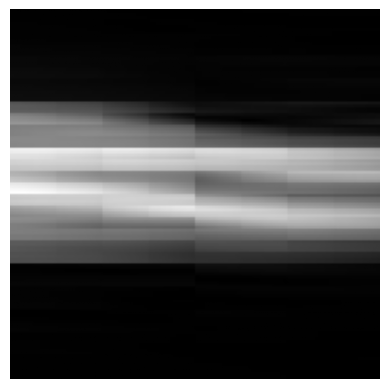

LAYER  1
Fidelity is:  tensor(0.9710, dtype=torch.float64)


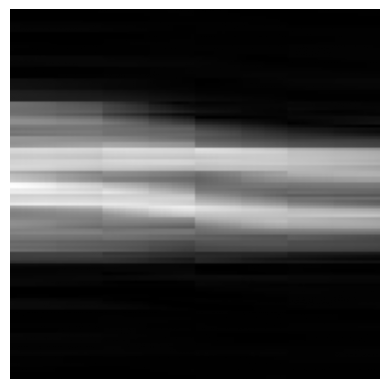

LAYER  2
Fidelity is:  tensor(0.9795, dtype=torch.float64)


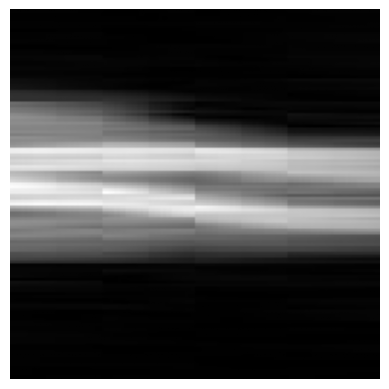

LAYER  3
Fidelity is:  tensor(0.9840, dtype=torch.float64)


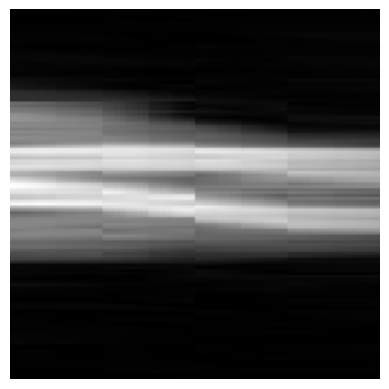

LAYER  4
Fidelity is:  tensor(0.9870, dtype=torch.float64)


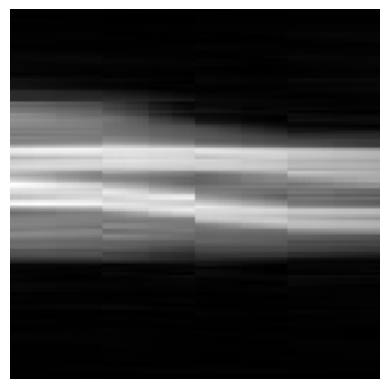

LAYER  5
Fidelity is:  tensor(0.9884, dtype=torch.float64)


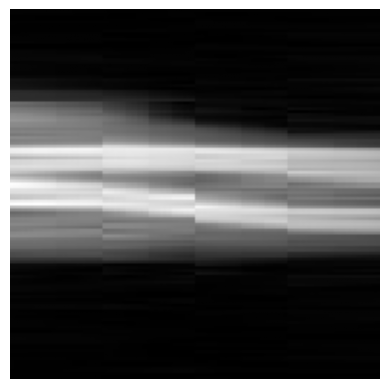

LAYER  6
Fidelity is:  tensor(0.9893, dtype=torch.float64)


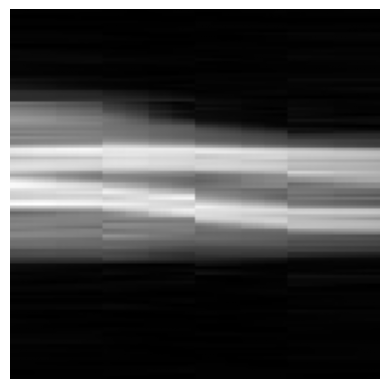

LAYER  7
Fidelity is:  tensor(0.9903, dtype=torch.float64)


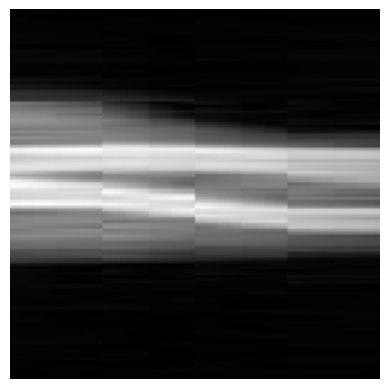

LAYER  8
Fidelity is:  tensor(0.9918, dtype=torch.float64)


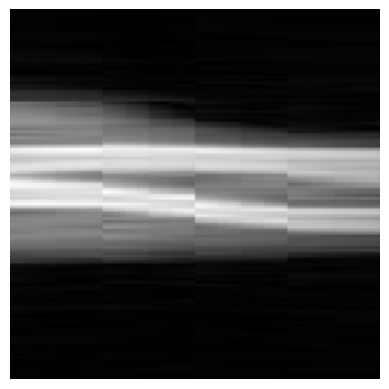

LAYER  9
Fidelity is:  tensor(0.9927, dtype=torch.float64)


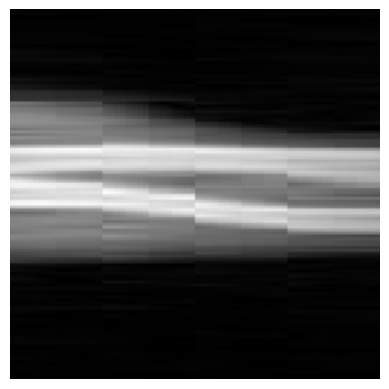

In [32]:
get_image_results(approx_states,fids,128,128)

### Super Simple wrist (64x64), 10 Layers

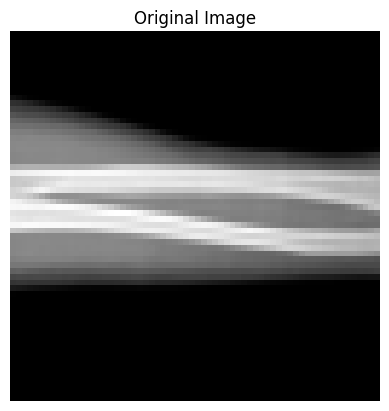

In [5]:
simplewristimg = mpimg.imread("simple_wrist.png")[:, :, 0]
simplewristimg_condense = resize(simplewristimg, (64,64), anti_aliasing=True)
plt.imshow(simplewristimg_condense, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

In [6]:
target_mps=image_to_mps(simplewristimg_condense)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:36: UserWarning: Couldn't import `kahypar` - skipping from default hyper optimizer and using basic `labels` method instead. `kahypar` is highly recommended for the best quality contraction paths.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:75: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality hyper-optimization.
  warnings.warn(
c:\Users\archi\anaconda3\envs\new

Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   9%|▉         | 56/600 [00:01<00:11, 48.96it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([9.7938e-01, 1.5363e-02, 3.2867e-03, 1.3913e-03, 3.2524e-04, 1.3490e-04,
        4.8003e-05, 2.4207e-05, 1.7225e-05, 7.1558e-06, 5.5967e-06, 3.8529e-06,
        3.0493e-06, 1.5424e-06, 1.2986e-06, 1.0713e-06, 8.1640e-07, 7.1680e-07,
        4.2282e-07, 3.2905e-07, 2.8522e-07, 2.7368e-07, 2.0956e-07, 1.8516e-07,
        1.4707e-07, 1.0993e-07, 9.4302e-08, 8.2383e-08, 4.1974e-08, 3.5767e-08,
        2.8287e-08, 1.6594e-08], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.9594375943468237
 bond 2 = 0.952312717183872
 bond 4 = 0.9892067356299419
 bond 6 = 0.9961333499044892

 LAYER 0
initial loss = 0.1057589079160457
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [6.08349128e-01 6.47824992e-05 3.18458124e-01 3.29643118e-01
 3.93710977e-01 3.21785217e-01 3.04884932e-01 2.66206680e-01
 3.24701734e-01 6.99395307e-01]
New tail entropy term = 3.567199999442518
tensor([2.3352e-12, 4.4310e-03, 2.71

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.051445552650 [best: +0.051445552650] : : 1293it [04:08,  5.21it/s]                      


...

+0.001216183156 [best: +0.001216183156] : : 1261it [08:53,  2.36it/s]                      



 LAYER 9
initial loss = 0.0038926952813232996
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [6.75024186e-01 6.44115224e-06 4.01311234e-01 5.96541991e-01
 7.16475812e-01 8.33949518e-01 9.40560463e-01 1.18471509e-01
 2.91196710e-02 1.15380716e-01]
New tail entropy term = 4.426841541911267
tensor([2.8813e-12, 1.3903e-04, 5.6604e-04, 9.7257e-04, 1.0317e-03, 7.6518e-04,
        4.1819e-04, 3.7159e-09, 7.6379e-09, 8.2484e-09], dtype=torch.float64)
At init net entropy comp = 1.858503307344293 // tail loss = 0.0038926952813232996


+0.003799986650 [best: +0.003799986650] : : 1158it [07:22,  2.62it/s]                      


final loss = 0.0038464510709830257
best val = 0.003799986650418141. Final loss = 0.0038464510709830257
after updating, final loss = 0.003799986650418141
Tail entropy (normalised) per cut: [0.71902164 0.14654538 0.43606189 0.59698807 0.77579501 0.8543884
 0.93887525 0.82589577 0.19553114 0.69115901]
New tail entropy term = 6.18026156608828
tensor([2.6837e-12, 1.3770e-04, 5.3027e-04, 9.6567e-04, 1.0228e-03, 7.2647e-04,
        4.1681e-04, 2.7639e-08, 1.7005e-08, 1.9567e-07], dtype=torch.float64)
After opt: net entropy comp = 2.2281693328544203 // tail loss = 0.003799986650418141
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9957378338941446
 error from singular value truncation ~ (0.00017820509268851037-7.657665004887053e-17j), cut from max bond 16 to 8. sv cutoff = 0.0001
 new max bond = 8
norm = (1.0000000000000009-8.230407390233215e-18j)
2. Central schmidt coefficients = tensor([9.9239e-01, 7.3193e-03, 1.9701e-04, 9.3315e-05], dtype=tor

+0.999999701214 [best: +0.000857209060] :  54%|█████▍    | 433/800 [01:11<01:00,  6.06it/s]


LAYER  0
Fidelity is:  tensor(0.9523, dtype=torch.float64)


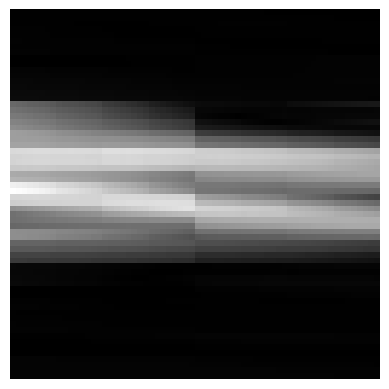

LAYER  1
Fidelity is:  tensor(0.9835, dtype=torch.float64)


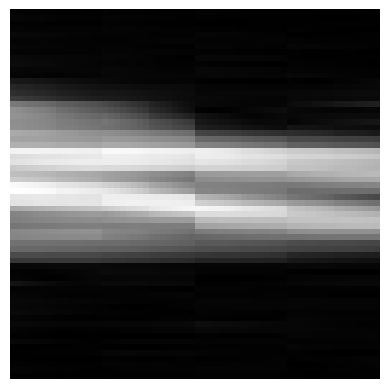

LAYER  2
Fidelity is:  tensor(0.9878, dtype=torch.float64)


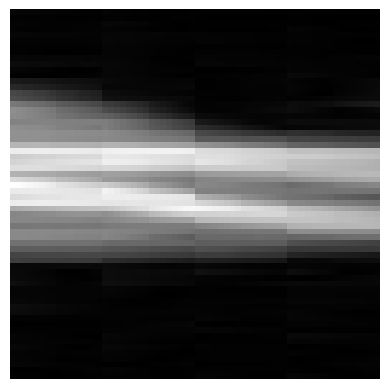

LAYER  3
Fidelity is:  tensor(0.9922, dtype=torch.float64)


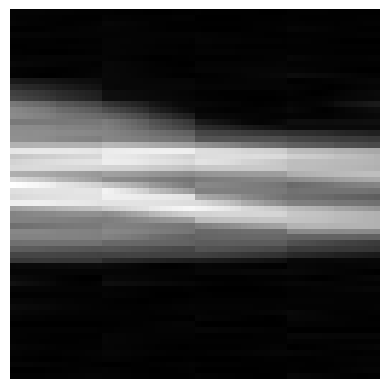

LAYER  4
Fidelity is:  tensor(0.9940, dtype=torch.float64)


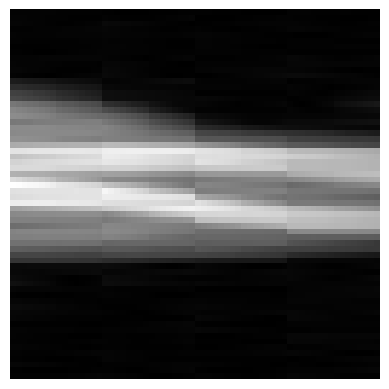

LAYER  5
Fidelity is:  tensor(0.9952, dtype=torch.float64)


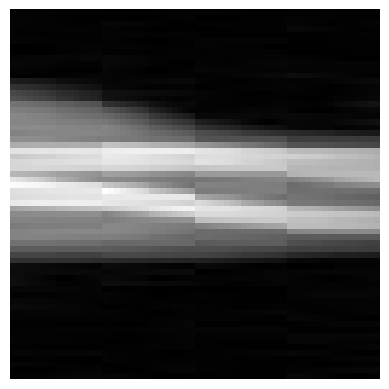

LAYER  6
Fidelity is:  tensor(0.9966, dtype=torch.float64)


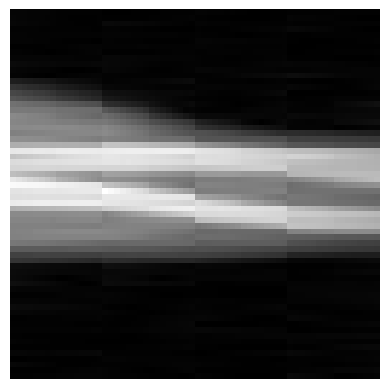

LAYER  7
Fidelity is:  tensor(0.9974, dtype=torch.float64)


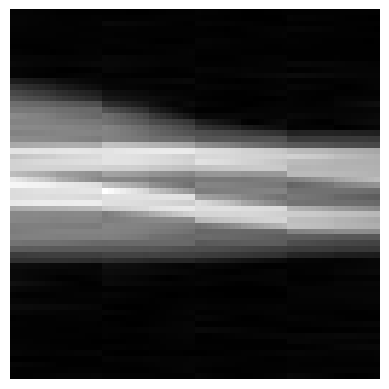

LAYER  8
Fidelity is:  tensor(0.9983, dtype=torch.float64)


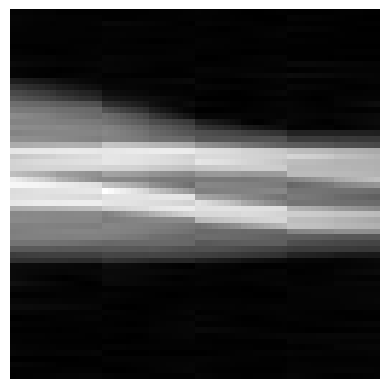

LAYER  9
Fidelity is:  tensor(0.9988, dtype=torch.float64)


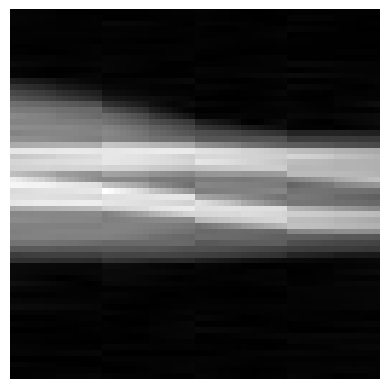

In [7]:
get_image_results(approx_states,fids,64,64)

### Extra Super Simple Wrist (32x32)

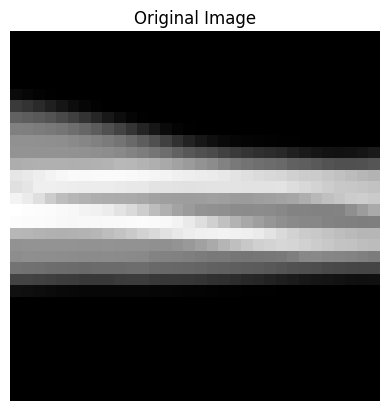

In [8]:
simplewristimg = mpimg.imread("simple_wrist.png")[:, :, 0]
simplewristimg_condense = resize(simplewristimg, (32,32), anti_aliasing=True)
plt.imshow(simplewristimg_condense, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

In [9]:
target_mps=image_to_mps(simplewristimg_condense)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  10%|▉         | 59/600 [00:01<00:10, 50.99it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([9.8622e-01, 1.1607e-02, 1.7871e-03, 2.9919e-04, 5.3453e-05, 1.4200e-05,
        7.4438e-06, 2.4534e-06, 2.0116e-06, 1.0201e-06, 7.5014e-07, 6.3680e-07,
        2.3654e-07, 1.2256e-07, 9.9165e-08, 5.5465e-08], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.9727765378566144
 bond 2 = 0.9666237522923455
 bond 4 = 0.996437884376799
 bond 6 = 0.999354386292209

 LAYER 0
initial loss = 0.05675267621043978
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [6.06197786e-01 1.31546101e-04 3.16287484e-01 2.72386494e-01
 2.42113075e-01 2.27842995e-01 2.53668640e-01 5.07586883e-01]
New tail entropy term = 2.4262149033178346
tensor([2.2862e-12, 4.2134e-03, 1.9770e-02, 2.2196e-02, 8.1084e-03, 2.1680e-03,
        2.7115e-04, 2.5888e-05], dtype=torch.float64)
At init net entropy comp = 3.1187707466075096 // tail loss = 0.05675267621043978


+0.020955164479 [best: +0.019711011064] : : 1193it [02:49,  7.04it/s]                      


final loss = 0.02095518461160184
best val = 0.019711011063808903. Final loss = 0.02095518461160184
after updating, final loss = 0.019711011063808903
Tail entropy (normalised) per cut: [0.74362158 0.11532731 0.41011199 0.4933688  0.43917501 0.2355868
 0.2566163  0.50706147]
New tail entropy term = 3.20086927188156
tensor([3.7794e-12, 3.5071e-03, 5.3131e-03, 5.0194e-03, 3.4141e-03, 2.1626e-03,
        2.6890e-04, 2.5780e-05], dtype=torch.float64)
After opt: net entropy comp = 1.3962797800447406 // tail loss = 0.019711011063808903
Returning current approx state...


...

+0.000006566724 [best: +0.000000274497] : : 1099it [02:33,  7.14it/s]                      



 LAYER 9
initial loss = 8.143478206212862e-07
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.93320198 0.1177279  0.05989454 0.0525798  0.30904718 0.04966992
 0.0316465  0.01879261]
New tail entropy term = 1.5725604225394436
tensor([2.6084e-12, 1.8279e-07, 2.0569e-08, 1.2341e-07, 2.2844e-08, 1.0740e-07,
        1.0881e-08, 3.4645e-07], dtype=torch.float64)
At init net entropy comp = 2.2234371018087566 // tail loss = 8.143478206212862e-07


+0.000000090107 [best: +0.000000002013] :  28%|██▊       | 223/800 [00:31<01:20,  7.16it/s]


final loss = 2.012851441079988e-09
best val = 2.012851441079988e-09. Final loss = 2.012851441079988e-09
after updating, final loss = 2.012851441079988e-09
Tail entropy (normalised) per cut: [0.93317575 0.09255428 0.02293158 0.13423186 0.18887986 0.11312387
 0.03242252 0.22694375]
New tail entropy term = 1.7442634622583038
tensor([2.6084e-12, 5.7169e-10, 5.6533e-10, 2.9187e-11, 3.1636e-10, 3.4982e-10,
        1.4376e-10, 3.4084e-11], dtype=torch.float64)
After opt: net entropy comp = 2.2233018523104375 // tail loss = 2.012851441079988e-09
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9981698065804311
 error from singular value truncation ~ (1.0004320705192526e-09-2.4106317012802913e-20j), cut from max bond 4 to 2. sv cutoff = 0.0001
 new max bond = 2
norm = (0.9999999999999998-1.2316393154067091e-17j)
2. Central schmidt coefficients = tensor([0.9960, 0.0040], dtype=torch.float64)
 bond 2 = 1.0000000000000004
 bond 4 = 1.0000000000000004
 

+0.000000226996 [best: +0.000000178774] : : 1218it [02:53,  7.04it/s]                      


LAYER  0
Fidelity is:  tensor(0.9666, dtype=torch.float64)


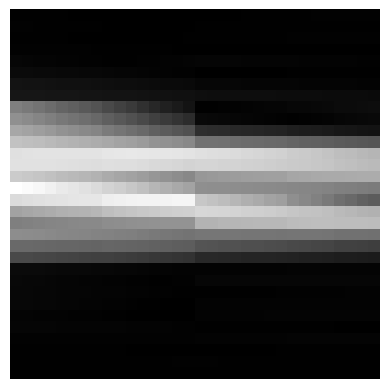

LAYER  1
Fidelity is:  tensor(0.9922, dtype=torch.float64)


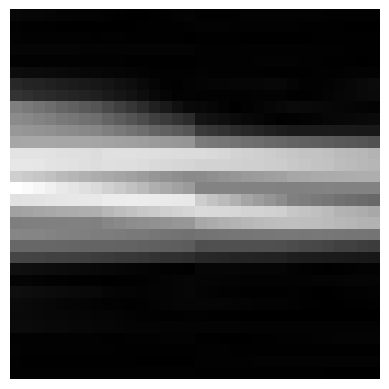

LAYER  2
Fidelity is:  tensor(0.9957, dtype=torch.float64)


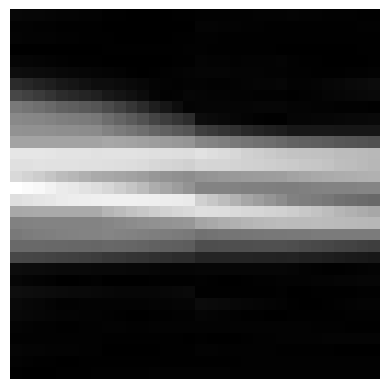

LAYER  3
Fidelity is:  tensor(0.9972, dtype=torch.float64)


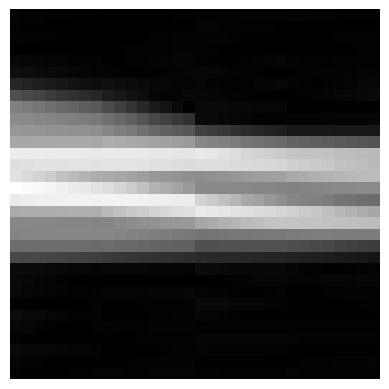

LAYER  4
Fidelity is:  tensor(0.9981, dtype=torch.float64)


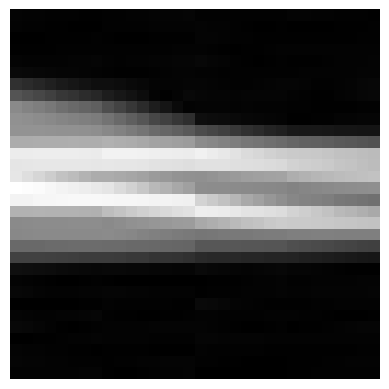

LAYER  5
Fidelity is:  tensor(0.9991, dtype=torch.float64)


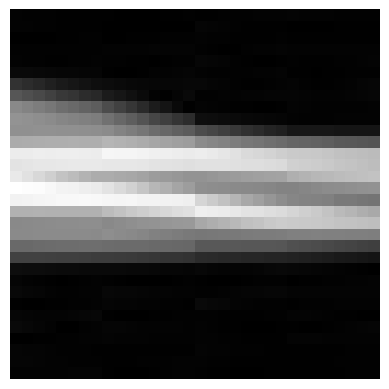

LAYER  6
Fidelity is:  tensor(0.9996, dtype=torch.float64)


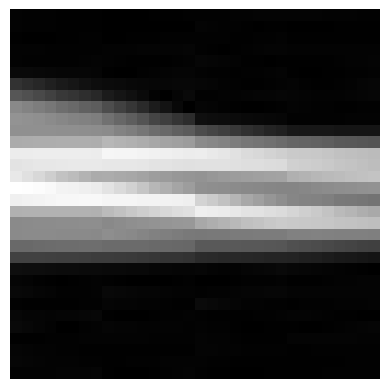

LAYER  7
Fidelity is:  tensor(0.9998, dtype=torch.float64)


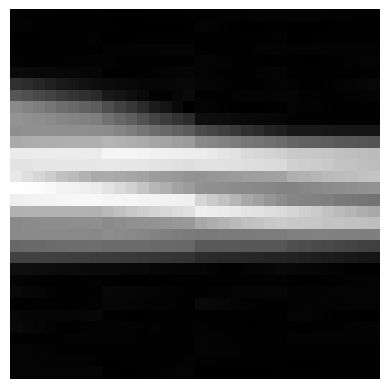

LAYER  8
Fidelity is:  tensor(1.0000, dtype=torch.float64)


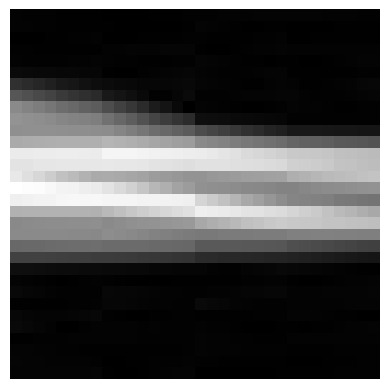

LAYER  9
Fidelity is:  tensor(1.0000, dtype=torch.float64)


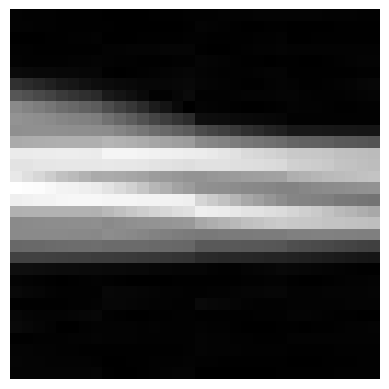

In [10]:
get_image_results(approx_states,fids,32,32)

okay so the code can reconstruct this image practically exactly for 32 32.

### Jie's Audio Data (just a section of it) + Circuit reconstruction work

In [10]:
from scipy.io import wavfile

sample_rate, audio = wavfile.read("Jies_Acoustic_Data_1.wav")

print(audio[84000:89000].tolist())

[4383744, 4365568, 4340224, 4103424, 4173824, 3983360, 4023040, 4098816, 4222464, 4258560, 4167424, 4106496, 4069376, 4270080, 4202752, 4200960, 4290304, 4290816, 4323840, 4273152, 4432896, 4449792, 4155648, 4157696, 4317952, 4378624, 4175616, 4162816, 4287488, 4440832, 4339968, 4147712, 3901952, 3999488, 4116480, 4126976, 4092928, 4162816, 3991552, 3906048, 3986176, 4204032, 4290048, 4262400, 4142848, 3846144, 3948800, 3904768, 3928832, 3983360, 4119808, 3970560, 4186368, 4218624, 4256512, 3968768, 3781120, 3778048, 3675648, 3958784, 3857920, 3988992, 4228352, 4188672, 4067840, 4061952, 4216576, 4166912, 4000768, 3874560, 4128512, 4002304, 4042240, 4023808, 3963904, 3829504, 3958784, 4080128, 4072960, 4379136, 4289280, 3999488, 3814400, 3634176, 3758592, 3895808, 3936768, 3805696, 3798528, 3879936, 3646464, 3579904, 3675136, 3783168, 3764736, 3794688, 3830528, 3726080, 3534848, 3527168, 3612416, 3585536, 3465984, 3495936, 3442688, 3589376, 3693824, 3581440, 3542016, 3607808, 3818752, 

C:\Users\archi\AppData\Local\Temp\ipykernel_3928\2218126030.py:3: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, audio = wavfile.read("Jies_Acoustic_Data_1.wav")


C:\Users\archi\AppData\Local\Temp\ipykernel_13392\2800907769.py:3: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, audio = wavfile.read("Jies_Acoustic_Data_1.wav")


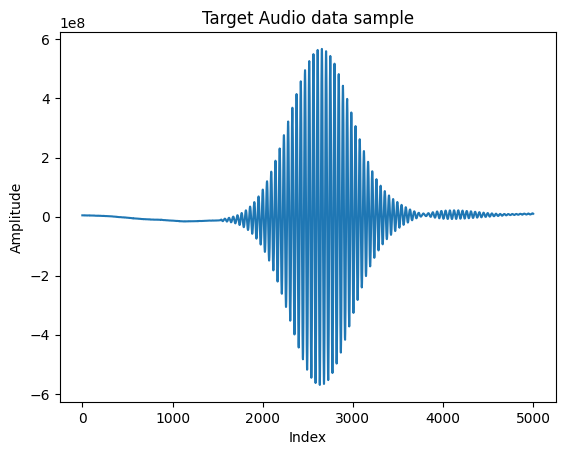

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(


In [3]:
from scipy.io import wavfile

sample_rate, audio = wavfile.read("Jies_Acoustic_Data_1.wav")

plt.plot(audio[84000:89000])
plt.xlabel("Index")
plt.ylabel("Amplitude")
plt.title("Target Audio data sample")
plt.show()

img=audio[84000:89000]
img_padded = pad_to_next_power_of_two(img.reshape(-1), pad_value=0).astype(float)
img_padded /= np.linalg.norm(img_padded)
audiostate = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()
audiostate.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

In [4]:
target_mps=audiostate
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=2,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:36: UserWarning: Couldn't import `kahypar` - skipping from default hyper optimizer and using basic `labels` method instead. `kahypar` is highly recommended for the best quality contraction paths.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:75: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality hyper-optimization.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.wa

Finding params to initialise identity layer...


  0%|          | 0/600 [00:00<?, ?it/s]

+0.000000000000 [best: +0.000000000000] :   9%|▉         | 55/600 [00:02<00:23, 23.43it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([5.4033e-01, 4.5564e-01, 2.6225e-03, 8.3955e-04, 5.3667e-04, 1.4762e-05,
        1.2138e-05, 4.1603e-06, 3.8897e-06, 1.0171e-06, 2.5321e-07, 5.6149e-08,
        4.7139e-08, 4.5114e-08, 4.2241e-08, 3.7295e-08, 3.2705e-08, 2.8255e-08,
        2.7576e-08, 2.2224e-08, 1.9357e-08, 1.8023e-08, 1.6628e-08, 1.3393e-08,
        1.3164e-08, 1.1812e-08, 1.0932e-08, 9.9666e-09, 9.6513e-09, 8.4966e-09,
        8.0406e-09, 7.0434e-09, 6.9619e-09, 6.1444e-09, 5.7354e-09, 5.1406e-09,
        4.8362e-09, 4.4720e-09, 3.7949e-09, 3.4113e-09, 3.3833e-09, 3.1011e-09,
        2.9793e-09, 2.8580e-09, 2.4295e-09, 2.2645e-09, 1.9765e-09, 1.8557e-09,
        1.7773e-09, 1.5270e-09, 1.3007e-09, 1.1408e-09, 1.0549e-09, 8.4001e-10,
        8.0597e-10, 6.3406e-10, 5.8180e-10, 5.3696e-10, 4.2927e-10, 3.5131e-10,
        2.2440e-10, 1.8375e-10, 1.2086e-10], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.4995666744406651
 bond 2 = 0.982326176545958

...

+0.005895828825 [best: +0.005895782280] : : 875it [06:02,  2.41it/s]                       



 LAYER 1
initial loss = 0.020234550502327586
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [8.10190312e-01 5.41947139e-05 2.64862836e-01 4.25804491e-01
 4.59449865e-01 4.52657537e-01 3.57373713e-01 4.62019334e-01
 1.61265342e-02 4.14624170e-01 1.11166396e-01]
New tail entropy term = 3.774329384429878
tensor([1.1557e-12, 5.6951e-04, 3.4243e-03, 3.8916e-03, 3.7181e-03, 4.4360e-03,
        3.1941e-03, 9.1803e-04, 8.2781e-05, 8.6771e-09, 1.5982e-07],
       dtype=torch.float64)
At init net entropy comp = 6.260487694818056 // tail loss = 0.020234550502327586


+0.012709740530 [best: +0.012709740530] : : 1265it [08:46,  2.40it/s]                      


final loss = 0.013085750604611035
best val = 0.01270974052972984. Final loss = 0.013085750604611035
after updating, final loss = 0.01270974052972984
Tail entropy (normalised) per cut: [0.55027147 0.09750043 0.483358   0.62002786 0.46831232 0.36225816
 0.67549863 0.53481156 0.56104341 0.54279245 0.07978617]
New tail entropy term = 4.975660456014299
tensor([2.5886e-12, 4.4166e-04, 1.0488e-03, 1.6343e-03, 3.4181e-03, 3.5434e-03,
        1.8449e-03, 7.1237e-04, 6.6233e-05, 3.0295e-08, 2.4543e-08],
       dtype=torch.float64)
After opt: net entropy comp = 6.549714360837108 // tail loss = 0.01270974052972984
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9955904856836925
 error from singular value truncation ~ (0.00014408503641316628+2.633513715357573e-18j), cut from max bond 14 to 7. sv cutoff = 0.0001
 new max bond = 7
norm = (0.9999999999999992+2.086753015833656e-17j)
2. Central schmidt coefficients = tensor([5.3451e-01, 4.6384e-01, 9.0556e-

+0.003848068878 [best: +0.003848068878] : : 986it [06:56,  2.37it/s]                       


In [6]:
def arch_SCS_all(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False):
    #Preliminaries: load final disentangled state (disentangled_mps // psi^(L))
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: x.detach().cpu().numpy())

    zero_mps = qtn.MPS_computational_state('0'*targ_copy.L)

    #Map the disentangled state into a QC // psi^(L) = U_L|0>
    reindexed_final_state = lrp_to_lpr(final_state.copy())
    mps_arrays = reindexed_final_state.arrays
    qc = mtc.mps_to_circuit(mps_arrays, shape='lpr',method='exact')
    gates_info = extract_gates_with_qubits(qc)
    qc = makequimbcirc(targ_copy.L,gates_info)
    qctocheck = qc 

    #Absorb extra single qubit-gate into neighbours. Also I think this makes a SU4 out of the last one where needed
    unitaries = []
    for g in qc.gates:
        unitaries.append(g.array)
    U_2q = unitaries[-2]
    U_1q = unitaries[-1]
    I2 = np.eye(2)
    U_new2 = np.kron(U_1q, I2) @ U_2q
    unitaries = unitaries[:-2] + [U_new2]

    #Check that U_L|0> has fidelity 1.0 with psi^(L)
    final_layer_b_ind_in = reindexed_final_state.copy()   
    final_layer_b_ind_in.reindex_({f'k{x}': f'b{x}' for x in range(len(final_layer_b_ind_in.outer_inds()))},inplace=True)
    qc_out = qc.uni | zero_mps
    fidelity_check = np.abs((qc_out.conj() | final_layer_b_ind_in).contract(all))**2
    if verbose:
        print(f'fidelity of the non-parametrised circuit vs chi2 state = {fidelity_check}')

    #Convert QC into parametrised SU4 layer
    paramlist = extract_su4_params_from_unitary(unitaries,verbose=verbose) #General U4 -> SU4 parameterisation
    layer_params = combine_layer_params_into_param_dict(paramlist,targ_copy.L) #Combine into a single dictionary

    #need ascending and decending for layers as circuit i sreversed to construct state
    def construct_circ_desc(layerparams,n):
        qc = qtn.Circuit(n)  # optionally gate_contract=False
        count = n

        for idx in range(n-1):
            p = layerparams[count]
            p = np.asarray(p, dtype=float).reshape(15)
            # Apply the SU4 gate
            qc.apply_gate("SU4", *(p), n-2-idx, n-1-idx, tags=["SU4"], parametrize=True)
            count += 1
        return qc

    def construct_circ_asc(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

    #Check: reconstruct the circuit from parameters
    circ = construct_circ_desc(layer_params,n=targ_mps.L)
    circ_tn = circ.uni

    #Reindex circ_tn
    final_circ_tn = reindex_su4_tngen(circ_tn.copy()) 

    #Check fidelity of output state
    final_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    zero_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    parametrized_final_layer_applied = final_circ_tn.copy() | zero_mps.copy()
    parametrized_final_layer_applied/=parametrized_final_layer_applied.norm()

    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    qc_out.apply_to_arrays(lambda x: torch.as_tensor(x))
    final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')
        print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    #At this stage, output indices of output_mps are b{x}

    #Set up optimisation requirements
    def loss(applied_uni: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = applied_uni.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = applied_uni.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy)
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
            #project_params_real(psi)
        return psi

    #Convert parameter set into quantum circuit
    core_circ = construct_circ_asc(param_set)

    #We've prepared the backward circuit --> reverse + take its adjoint for state preparation
    core_circ_tn = core_circ.uni.conj() 
    core_circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    #Now outputs are b{x} and inputs are k{x}

    #We must invert b->k in target MPS indices to append it to the output end of the circuit TN
    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

    #Test that core circ is constructed properly
    if verbose:
        print(final_state.outer_inds())
        combined_core = core_circ_tn.copy() | final_state.copy()
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x))
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(combined_core.copy(),targ_copy.copy())}')

    #Reindex final layer to append it to the start (via z-index connection)
    #targ_copy.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    parametrized_final_layer_applied.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)

    #print('drawing param final layer')
    #parametrized_final_layer_applied.draw(figsize=(15,15))

    #Append final layer MPS
    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    to_opt = core_circ_tn.copy() | parametrized_final_layer_applied.copy() #output indices are k{x}
    #to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
    targ_copy.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    #targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        test_tn = parametrized_final_layer_applied.copy()
        test_tn.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
        test_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    #Test that core circ is combined with parametrized version of final layer correctly
    if verbose:
        comb = to_opt.copy() | targ_copy.copy()
        #comb.draw(figsize=(20,20))
        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(to_opt.copy(),targ_copy.copy())}')

    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))#,dtype=torch.complex128))
    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))#,dtype=torch.complex128))

    #to_opt.draw(figsize=(20,20))
    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_layer_tn = tnopt.optimize(n=500,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        print(f'params = {opt_layer_tn.get_params()}')
    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy)}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy)}')
    best_params = _best["params"]

    return best_layer_tn,best_params

In [7]:
L=2
trained_tn,best_params = arch_SCS_all(target_mps, disentangled_mps = mps_states[L-1], param_set = param_set[:L], verbose=True)

C:\Users\archi\AppData\Local\Temp\ipykernel_13392\1743614162.py:2239: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in qc.data:


fidelity of the non-parametrised circuit vs chi2 state = 1.0000000000000004


+0.000000000000 [best: +0.000000000000] :  19%|█▉        | 116/600 [00:04<00:18, 25.69it/s]
C:\Users\archi\AppData\Local\Temp\ipykernel_13392\129286310.py:88: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')


Fidelity of param circ with pre-param = 0.9999999999998976


C:\Users\archi\AppData\Local\Temp\ipykernel_13392\129286310.py:89: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')


Fidelity of param circ with final_layer = 0.9999999999998945
('k0', 'k1', 'k2', 'k3', 'k4', 'k5', 'k6', 'k7', 'k8', 'k9', 'k10', 'k11', 'k12')


C:\Users\archi\AppData\Local\Temp\ipykernel_13392\129286310.py:96: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Copy.cpp:309.)
  npsi = applied_uni.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
C:\Users\archi\AppData\Local\Temp\ipykernel_13392\129286310.py:163: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')


Loss using final state = 0.004409420333910341
Fidelity of param final circ with final layer = 0.9999999999998944
Loss using final state = 0.004409420353190696


  0%|          | 0/500 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:1523: OptimizeWarning: Unknown solver options: lr
  self.res = minimize(
+0.004124408192 [best: +0.004124408192] : : 501it [14:39,  1.76s/it]                       


params = {13: tensor([ 0.0303, -1.0186,  0.2777,  0.5412, -0.2245,  0.4163, -0.0495, -0.5604,
        -0.8049, -0.3462, -0.1391,  0.3351,  0.4854,  1.5843, -1.6665],
       dtype=torch.float64), 14: tensor([-0.2190, -1.0841, -0.5962,  1.5717,  1.5378,  0.4830, -0.0371, -0.7866,
        -0.3704, -0.4137, -0.6821, -0.6016,  1.6649,  0.4071, -1.5762],
       dtype=torch.float64), 15: tensor([-0.1464, -0.1530, -1.7425,  0.3727,  0.9999, -1.2490, -0.5141,  0.0156,
        -0.7011,  0.0621,  0.8737,  0.2587,  1.6603,  0.6112, -1.8069],
       dtype=torch.float64), 16: tensor([ 1.2840, -0.4958,  0.3040,  1.4746, -0.1095,  0.7426, -0.5573, -0.7700,
        -0.2257,  0.2159,  0.5999,  0.0885,  2.7813,  0.0676, -0.5074],
       dtype=torch.float64), 17: tensor([ 2.1937e-01, -4.5809e-02, -3.0738e-01, -2.3655e+00,  9.7690e-02,
         4.6026e-04, -2.1855e-01, -3.2146e-01, -1.0564e+00,  5.9228e-02,
        -2.5672e-01, -1.2060e-01, -9.0926e-02,  1.7507e+00, -1.5049e+00],
       dtype=torch.float64

In [ ]:
final_tn=trained_tn.copy()

quimb.tensor.tensor_core.TensorNetwork

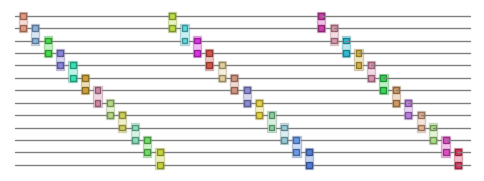

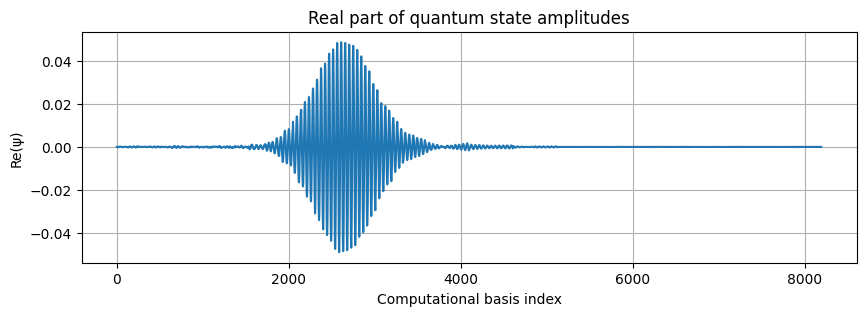

In [ ]:
#Working process for extracting circuit from 
import re  # for extracting numbers

def make_simple_index_dict(gate_list, prefixes=('k', 'z')):
    """
    Create a dict from tensors in gate_list.
    keys are the integer after the prefix (e.g. 'k9' -> 9),
    values are the corresponding 'matrix'.
    Only uses the first matching prefix found in the indices.
    """
    out = {}
    for gate in gate_list:
        # find the first 'simple' index starting with one of the prefixes
        simple_inds = [i for i in gate['indices'] if any(i.startswith(p) for p in prefixes)]
        if not simple_inds:
            continue  # skip if none
        s = simple_inds[0]  # take the first matching one
        # extract the number after the letter
        m = re.match(r'([a-zA-Z]+)(\d+)', s)
        if m:
            num = int(m.group(2))
            out[num] = gate['matrix']  # store the tensor matrix
    return out


def seperate_sort_gate_tensors(gate_list, n_qubits):
    """
    Sorts Tensors into k,z and b layers and pairs them with a number for qubit to be applied to.
    """
    def pick_by_prefix(tensors, prefix):
        return [T for T in tensors if any(i.startswith(prefix) for i in T['indices'])]

    #below will sort tensors out of gate list into an ordered array for each layer. this is all based off the diagram that the tn object output sfor 2 layers and depends on the index choice used there to rebuild the circuit. k z and b layer are to be added in decending order to the circuit.

    # sort the tensors in desired order
    k_tensors = sorted(pick_by_prefix(gate_list, 'k'), key=lambda T: T['indices'][0], reverse=True)
    k_tensor_dict=make_simple_index_dict(k_tensors,'k')
    sorted_k_gates = [v for k, v in sorted(k_tensor_dict.items(), key=lambda item: item[0], reverse=True)]
    sorted_k_gates = [t.numpy() for t in sorted_k_gates]

    #avoid double ups on z tensors
    # --- Z layer (exclude any tensor that has both k and z) ---
    z_tensors_all = pick_by_prefix(gate_list, 'z')
    z_tensors = [T for T in z_tensors_all if not any(i.startswith('k') for i in T['indices'])]  # <- filter out double-ups

    z_tensor_dict=make_simple_index_dict(z_tensors,'z')
    sorted_z_gates = [v for k, v in sorted(z_tensor_dict.items(), key=lambda item: item[0], reverse=True)]
    sorted_z_gates = [t.numpy() for t in sorted_z_gates]
    
    b_tensors = sorted(pick_by_prefix(gate_list, 'b'), key=lambda T: T['indices'][0], reverse=True)
    b_tensor_dict=make_simple_index_dict(b_tensors,'b')
    sorted_b_gates = [v for k, v in sorted(b_tensor_dict.items(), key=lambda item: item[0], reverse=True)]
    sorted_b_gates = [t.numpy() for t in sorted_b_gates]
    

    return sorted_k_gates,sorted_z_gates,sorted_b_gates
def arch_apply_layer(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits-2,-1,-1):
        qc.apply_gate_raw(sorted_gates[gate_count], (idx, idx+1), tags=['SU4'])
        gate_count=gate_count+1
def arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,num_qubits):
    qc=qtn.Circuit(num_qubits)
    
    sorted_k_gates=[U.conj().T for U in sorted_k_gates]
    sorted_z_gates=[U.conj().T for U in sorted_z_gates]
    sorted_b_gates=[U.conj().T for U in sorted_b_gates]

    arch_apply_layer(sorted_k_gates,qc,num_qubits)
    arch_apply_layer(sorted_z_gates,qc,num_qubits)
    arch_apply_layer(sorted_b_gates,qc,num_qubits)
    qc.draw()
    return qc

def rebuild_circ_from_trained_tn(final_tn,num_qubits):
    '''Note this is a very held together function that took like a week to get working and only works in this one specific case as far as i know(basically its pretty rubish but its all i have)'''
    final_tn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    gate_list = []
    for T in final_tn.tensors:
        # filter only 2-qubit SU4 tensors
        if T.shape == (2,2,2,2):
            # store indices with letters
            letter_inds = [i for i in T.inds if any(c.isalpha() for c in i)]
            
            # reshape tensor to 4x4 matrix
            # note: first 2 indices -> input, last 2 -> output
            # For PTensor with parametrized data
            U = T.data.reshape(4,4)  # careful: may need conj transpose if it seems wrong
            
            # store info
            gate_list.append({
                "tensor": T,
                "matrix": U,
                "indices": letter_inds,
                "tags": list(T.tags)
            })
    sorted_k_gates,sorted_z_gates,sorted_b_gates=seperate_sort_gate_tensors(gate_list,num_qubits)
    circ=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,num_qubits)
    return circ
circ=rebuild_circ_from_trained_tn(final_tn,13)
psi=circ.psi.to_dense()
real_part = np.real(psi)
plt.figure(figsize=(10, 3))
plt.plot(real_part)
plt.xlabel("Computational basis index")
plt.ylabel("Re(ψ)")
plt.title("Real part of quantum state amplitudes")
plt.grid(True)
plt.show()

#### Debugging

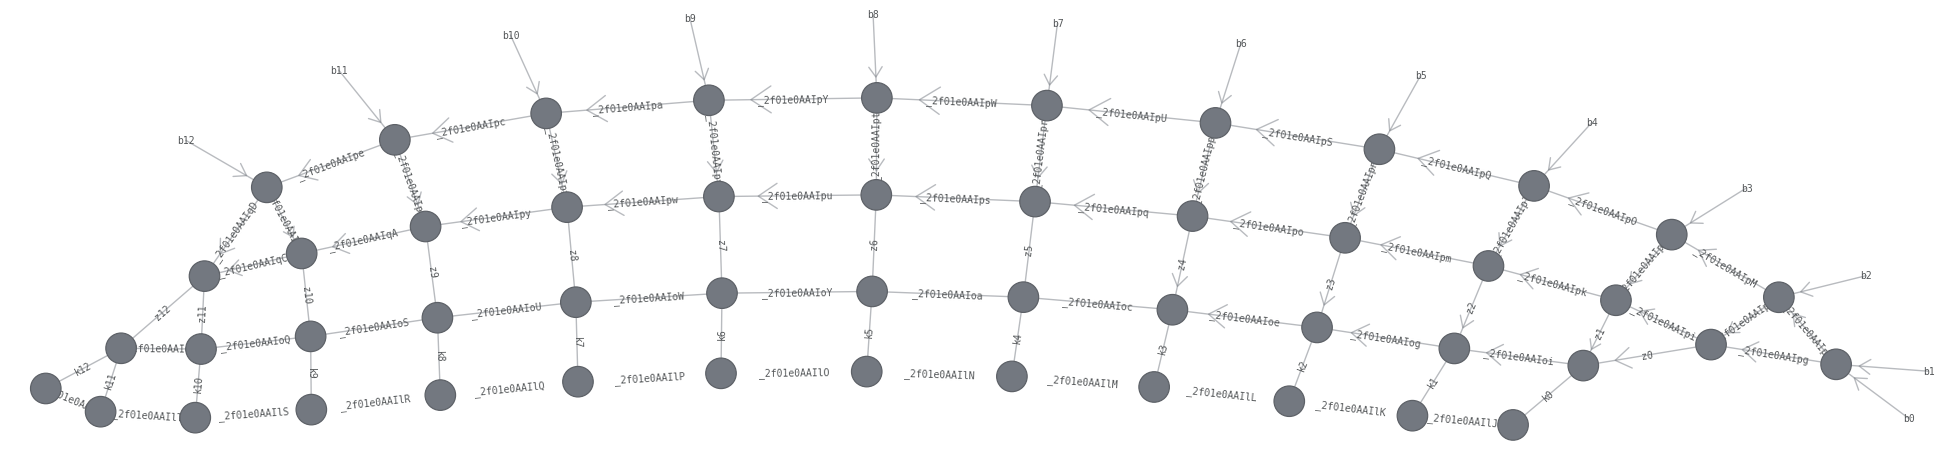

In [9]:
final_tn.draw(show_inds='all',figsize=(25, 25))

In [10]:
list(final_tn.select_tensors(all))


[PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('_2f01e0AAIpg', '_2f01e0AAIpK', 'b0', 'b1'), tags=oset(['SU4', 'GATE_0', 'I0', 'I1']), left_inds=('b0', 'b1')),
 PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('_2f01e0AAIph', '_2f01e0AAIpM', '_2f01e0AAIpK', 'b2'), tags=oset(['SU4', 'GATE_1', 'I1', 'I2']), left_inds=('_2f01e0AAIpK', 'b2')),
 PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('_2f01e0AAIpj', '_2f01e0AAIpO', '_2f01e0AAIpM', 'b3'), tags=oset(['SU4', 'GATE_2', 'I2', 'I3']), left_inds=('_2f01e0AAIpM', 'b3')),
 PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('_2f01e0AAIpl', '_2f01e0AAIpQ', '_2f01e0AAIpO', 'b4'), tags=oset(['SU4', 'GATE_3', 'I3', 'I4']), left_inds=('_2f01e0AAIpO', 'b4')),
 PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('_2f01e0AAIpn', '_2f01e0AAIpS', '_2f01e0AAIpQ', 'b5'), tags=oset(['SU4', 'GATE_4', 'I4', 'I5']), left_inds=('_2f01e0AAIpQ', 'b5')),
 PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('_2f01e0AAIpp', '_2f01e0AAIpU', '_2f01e0AAIpS', 'b6'), tags=oset(['SU4', 'GATE

In [33]:
final_tn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

In [34]:
final_tn.tensors[1]

PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('_2f01e0AAIph', '_2f01e0AAIpM', '_2f01e0AAIpK', 'b2'), tags=oset(['SU4', 'GATE_1', 'I1', 'I2']), left_inds=('_2f01e0AAIpK', 'b2'))

In [35]:
final_tn.tensors[24]

PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('k11', 'k12', '_2f01e0AAIoO', 'z12'), tags=oset(['SU4', 'GATE_0', 'I11', 'I12']))

In [ ]:
final_tn.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
gate_list = []
for T in final_tn.tensors:
    # filter only 2-qubit SU4 tensors
    if T.shape == (2,2,2,2):
        # store indices with letters
        letter_inds = [i for i in T.inds if any(c.isalpha() for c in i)]
        
        # reshape tensor to 4x4 matrix
        # note: first 2 indices -> input, last 2 -> output
        # For PTensor with parametrized data
        U = T.data.reshape(4,4)  # careful: may need conj transpose if it seems wrong
        
        # store info
        gate_list.append({
            "tensor": T,
            "matrix": U,
            "indices": letter_inds,
            "tags": list(T.tags)
        })
        count=count+1


Found 36 2-qubit gates


In [39]:
gate_list[1]

{'tensor': PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('_2f01e0AAIph', '_2f01e0AAIpM', '_2f01e0AAIpK', 'b2'), tags=oset(['SU4', 'GATE_1', 'I1', 'I2']), left_inds=('_2f01e0AAIpK', 'b2')),
 'matrix': tensor([[ 0.3615+0.5118j, -0.5007-0.0980j,  0.2295+0.4785j,  0.2457+0.0707j],
         [-0.2663+0.3522j,  0.0862+0.7259j, -0.2502+0.2609j, -0.0441-0.3717j],
         [ 0.1986-0.4796j, -0.0434-0.2597j, -0.3068+0.5371j, -0.0953-0.5191j],
         [ 0.3694+0.0803j, -0.3458+0.1284j, -0.4149-0.1814j, -0.6853+0.2153j]],
        dtype=torch.complex128),
 'indices': ['_2f01e0AAIph', '_2f01e0AAIpM', '_2f01e0AAIpK', 'b2'],
 'tags': ['SU4', 'GATE_1', 'I1', 'I2']}

KGATES:  [array([[ 0.58202826+0.03064421j,  0.2211523 +0.66589927j,
         0.31456239+0.01467208j, -0.08062462-0.24961722j],
       [ 0.21442015-0.15826631j, -0.38193016-0.07747488j,
        -0.01207216-0.77562583j,  0.34533318-0.2368683j ],
       [ 0.08815743+0.32977098j,  0.09571298+0.29393884j,
        -0.29172782-0.37350674j, -0.06823435+0.74742894j],
       [-0.60646143+0.32398103j,  0.4414201 +0.25570314j,
         0.12592156-0.24212686j,  0.34689456-0.26867738j]]), array([[ 0.44552844+0.15794513j,  0.66797301+0.5592994j ,
        -0.11283244-0.02905615j,  0.03183672+0.05445167j],
       [-0.09733357+0.855663j  ,  0.23246245-0.40912809j,
         0.07423724-0.03686386j, -0.09281805-0.14648249j],
       [ 0.12614157-0.04675024j, -0.08832296+0.07383197j,
        -0.14336369+0.10399472j,  0.22148849-0.94245711j],
       [ 0.04027883-0.12330888j,  0.0781551 +0.01453717j,
         0.6354779 -0.73780368j,  0.019408  -0.16819601j]]), array([[ 0.64828808+0.5747724j , -0.12442896-0.410

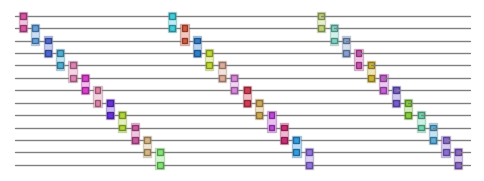

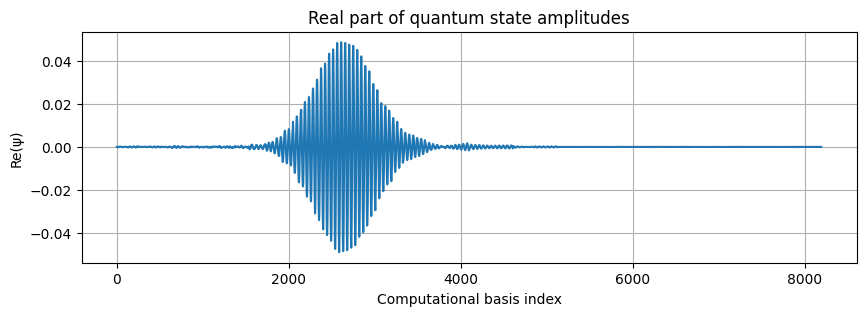

In [93]:
import re  # for extracting numbers

def make_simple_index_dict(gate_list, prefixes=('k', 'z')):
    """
    Create a dict from tensors in gate_list.
    keys are the integer after the prefix (e.g. 'k9' -> 9),
    values are the corresponding 'matrix'.
    Only uses the first matching prefix found in the indices.
    """
    out = {}
    for gate in gate_list:
        # find the first 'simple' index starting with one of the prefixes
        simple_inds = [i for i in gate['indices'] if any(i.startswith(p) for p in prefixes)]
        if not simple_inds:
            continue  # skip if none
        s = simple_inds[0]  # take the first matching one
        # extract the number after the letter
        m = re.match(r'([a-zA-Z]+)(\d+)', s)
        if m:
            num = int(m.group(2))
            out[num] = gate['matrix']  # store the tensor matrix
    return out


def seperate_sort_gate_tensors(gate_list, n_qubits):
    """
    Sorts Tensors into k,z and b layers and pairs them with a number for qubit to be applied to.
    """
    def pick_by_prefix(tensors, prefix):
        return [T for T in tensors if any(i.startswith(prefix) for i in T['indices'])]

    #below will sort tensors out of gate list into an ordered array for each layer. this is all based off the diagram that the tn object output sfor 2 layers and depends on the index choice used there to rebuild the circuit. k z and b layer are to be added in decending order to the circuit.

    # sort the tensors in desired order
    k_tensors = sorted(pick_by_prefix(gate_list, 'k'), key=lambda T: T['indices'][0], reverse=True)
    k_tensor_dict=make_simple_index_dict(k_tensors,'k')
    sorted_k_gates = [v for k, v in sorted(k_tensor_dict.items(), key=lambda item: item[0], reverse=True)]
    sorted_k_gates = [t.numpy() for t in sorted_k_gates]

    #avoid double ups on z tensors
    # --- Z layer (exclude any tensor that has both k and z) ---
    z_tensors_all = pick_by_prefix(gate_list, 'z')
    z_tensors = [T for T in z_tensors_all if not any(i.startswith('k') for i in T['indices'])]  # <- filter out double-ups

    z_tensor_dict=make_simple_index_dict(z_tensors,'z')
    sorted_z_gates = [v for k, v in sorted(z_tensor_dict.items(), key=lambda item: item[0], reverse=True)]
    sorted_z_gates = [t.numpy() for t in sorted_z_gates]
    
    b_tensors = sorted(pick_by_prefix(gate_list, 'b'), key=lambda T: T['indices'][0], reverse=True)
    b_tensor_dict=make_simple_index_dict(b_tensors,'b')
    sorted_b_gates = [v for k, v in sorted(b_tensor_dict.items(), key=lambda item: item[0], reverse=True)]
    sorted_b_gates = [t.numpy() for t in sorted_b_gates]
    

    return sorted_k_gates,sorted_z_gates,sorted_b_gates
def arch_apply_layer(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits-2,-1,-1):
        qc.apply_gate_raw(sorted_gates[gate_count], (idx, idx+1), tags=['SU4'])
        gate_count=gate_count+1
def arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,num_qubits):
    qc=qtn.Circuit(num_qubits)
    
    sorted_k_gates=[U.conj().T for U in sorted_k_gates]
    sorted_z_gates=[U.conj().T for U in sorted_z_gates]
    sorted_b_gates=[U.conj().T for U in sorted_b_gates]

    arch_apply_layer(sorted_k_gates,qc,num_qubits)
    arch_apply_layer(sorted_z_gates,qc,num_qubits)
    arch_apply_layer(sorted_b_gates,qc,num_qubits)
    qc.draw()
    return qc

sorted_k_gates,sorted_z_gates,sorted_b_gates=seperate_sort_gate_tensors(gate_list,13)
print("KGATES: ",sorted_k_gates)
print("ZGATES: ",sorted_z_gates)
print("BGATES: ",sorted_b_gates)
circ=arch_build_circuit_from_kzb(sorted_k_gates,sorted_z_gates,sorted_b_gates,13)
psi=circ.psi.to_dense()
real_part = np.real(psi)
plt.figure(figsize=(10, 3))
plt.plot(real_part)
plt.xlabel("Computational basis index")
plt.ylabel("Re(ψ)")
plt.title("Real part of quantum state amplitudes")
plt.grid(True)
plt.show()

In [85]:
sorted_k_gates[1]@[U.conj().T for U in sorted_k_gates][1]

array([[ 1.00000000e+00+0.00000000e+00j, -6.93889390e-17-1.94289029e-16j,
         6.24500451e-17+1.56125113e-17j, -3.90312782e-17-6.24500451e-17j],
       [-6.93889390e-17+1.94289029e-16j,  1.00000000e+00+0.00000000e+00j,
         8.32667268e-17+2.77555756e-17j, -9.71445147e-17+1.38777878e-17j],
       [ 6.24500451e-17-1.56125113e-17j,  8.32667268e-17-2.77555756e-17j,
         1.00000000e+00+0.00000000e+00j, -2.77555756e-17-1.80411242e-16j],
       [-3.90312782e-17+6.24500451e-17j, -9.71445147e-17-1.38777878e-17j,
        -2.77555756e-17+1.80411242e-16j,  1.00000000e+00+0.00000000e+00j]])

so the gates are unitary, it must be the order that they are applied in that causes problems

#### Old testing

In [75]:
# Make a copy of the network so you don't modify the original
tn_dense = final_tn.copy()

# Apply to all tensors in the network
def force_tensor(tensor):
    # If it's a PTensor, make its data dense
    if hasattr(tensor, 'to_dense'):
        return tensor.to_dense()
    return tensor

# This loops over every tensor and forces evaluation
tn_dense.apply_to_arrays(force_tensor)

# Now you can safely index tensors without triggering lazy evaluation
for i, t in enumerate(tn_dense):
    print(f"Tensor {i}: shape={t.shape}, inds={t.inds}")


Tensor 0: shape=torch.Size([2, 2, 2, 2]), inds=('z0', '_081c81AAFFy', 'b0', 'b1')
Tensor 1: shape=torch.Size([2, 2, 2, 2]), inds=('z1', '_081c81AAFGA', '_081c81AAFFy', 'b2')
Tensor 2: shape=torch.Size([2, 2, 2, 2]), inds=('z2', '_081c81AAFGC', '_081c81AAFGA', 'b3')
Tensor 3: shape=torch.Size([2, 2, 2, 2]), inds=('z3', '_081c81AAFGE', '_081c81AAFGC', 'b4')
Tensor 4: shape=torch.Size([2, 2, 2, 2]), inds=('z4', '_081c81AAFGG', '_081c81AAFGE', 'b5')
Tensor 5: shape=torch.Size([2, 2, 2, 2]), inds=('z5', '_081c81AAFGI', '_081c81AAFGG', 'b6')
Tensor 6: shape=torch.Size([2, 2, 2, 2]), inds=('z6', '_081c81AAFGK', '_081c81AAFGI', 'b7')
Tensor 7: shape=torch.Size([2, 2, 2, 2]), inds=('z7', '_081c81AAFGM', '_081c81AAFGK', 'b8')
Tensor 8: shape=torch.Size([2, 2, 2, 2]), inds=('z8', '_081c81AAFGO', '_081c81AAFGM', 'b9')
Tensor 9: shape=torch.Size([2, 2, 2, 2]), inds=('z9', '_081c81AAFGQ', '_081c81AAFGO', 'b10')
Tensor 10: shape=torch.Size([2, 2, 2, 2]), inds=('z10', '_081c81AAFGS', '_081c81AAFGQ', '

In [ ]:
tn_dense.select_tensors(all)[10]

TypeError: unsupported operand type(s) for *: 'numpy.ndarray' and 'Tensor'

PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('k11', 'k12', '_081c81AAFFC', 'z12'), tags=oset(['SU4', 'GATE_0', 'I11', 'I12']))

24
0
<class 'quimb.tensor.tensor_core.PTensor'>
PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('z0', '_081c81AAFFy', 'b0', 'b1'), tags=oset(['SU4', 'GATE_0', 'I0', 'I1']), left_inds=('b0', 'b1'), backend='numpy', dtype='complex128')
['I0', 'I1']
1
<class 'quimb.tensor.tensor_core.PTensor'>
PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('z1', '_081c81AAFGA', '_081c81AAFFy', 'b2'), tags=oset(['SU4', 'GATE_1', 'I1', 'I2']), left_inds=('_081c81AAFFy', 'b2'), backend='numpy', dtype='complex128')
['I1', 'I2']
2
<class 'quimb.tensor.tensor_core.PTensor'>
PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('z2', '_081c81AAFGC', '_081c81AAFGA', 'b3'), tags=oset(['SU4', 'GATE_2', 'I2', 'I3']), left_inds=('_081c81AAFGA', 'b3'), backend='numpy', dtype='complex128')
['I2', 'I3']
3
<class 'quimb.tensor.tensor_core.PTensor'>
PTensor(shape=torch.Size([2, 2, 2, 2]), inds=('z3', '_081c81AAFGE', '_081c81AAFGC', 'b4'), tags=oset(['SU4', 'GATE_3', 'I3', 'I4']), left_inds=('_081c81AAFGC', 'b4'), backend='numpy', dt

TypeError: unsupported operand type(s) for *: 'numpy.ndarray' and 'Tensor'

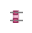

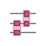

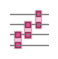

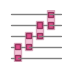

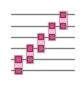

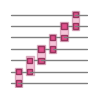

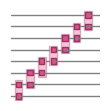

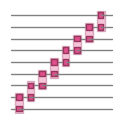

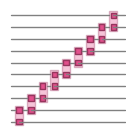

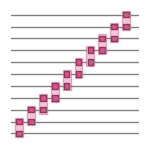

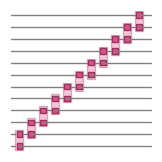

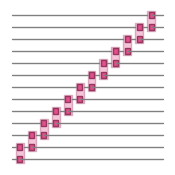

In [65]:
def tn_su4_to_circuit(tn, n_qubits):
    """
    Convert a TN (quimb.TensorNetwork) with SU4 PTensors into a qtn.Circuit.
    
    tn: quimb.TensorNetwork
    n_qubits: int, number of qubits
    """
    qc = qtn.Circuit(n_qubits)

    # Select only SU4 tensors
    su4_tensors = list(tn.select_tensors(tags='SU4'))
    print(len(su4_tensors))
    # Sort by shared indices or name (optional)
    # Here we just trust the TN order
    for tensor_num in range(len(su4_tensors)):
        # Extract qubits from tags (assumes tags like 'I0', 'I1')
        print(tensor_num)
        print(type(su4_tensors[tensor_num]))
        print(su4_tensors[tensor_num])
        qubit_tags = [tag for tag in su4_tensors[tensor_num].tags if tag.startswith('I')]
        print(qubit_tags)
        if len(qubit_tags) != 2:
            raise ValueError(f"Expected 2 qubits for SU4 gate, got {qubit_tags}")
        q0 = int(qubit_tags[0][1:])
        q1 = int(qubit_tags[1][1:])
        qubits = [q0, q1]

        # Extract unitary
        U = su4_tensors[tensor_num].data
        U = U.reshape(4, 4)

        # Apply SU4 to circuit
        qc.apply_gate("SU4", *U.flatten(), qubits[0], qubits[1], tags=["SU4"], parametrize=True)
        qc.draw()

    return qc
tn_su4_to_circuit(final_tn,13)


In [56]:
qc

NameError: name 'qc' is not defined

now try and rebuild the circuit (old stuff, better things above)

In [17]:
def build_parametric_su4_circuit(n, eps=0.0):
    """
    Build the same SU4-parametrized circuit structure.
    """
    qc = qtn.Circuit(n)

    for idx in range(n - 1):
        qc.apply_gate(
            "SU4",
            *(eps * np.zeros(15)),
            idx, idx + 1,
            tags=["SU4"],
            parametrize=True,
        )

    return qc
def flatten_su4_params(best_params, n):
    params = []

    for idx in range(n - 1):
        if idx in best_params and best_params[idx].shape == (15,):
            params.extend(best_params[idx])
        else:
            params.extend(np.zeros(15))

    return np.array(params)



LAYER  0
Fidelity is:  tensor(0.9823, dtype=torch.float64)


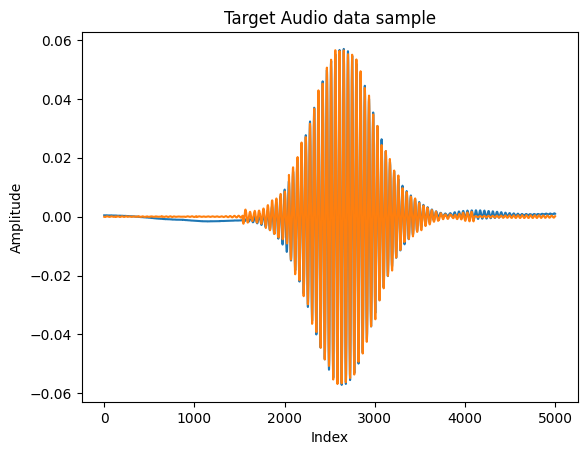

LAYER  1
Fidelity is:  tensor(0.9949, dtype=torch.float64)


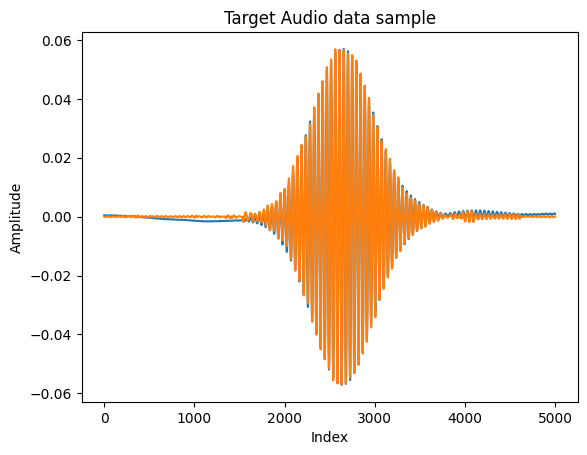

LAYER  2
Fidelity is:  tensor(0.9965, dtype=torch.float64)


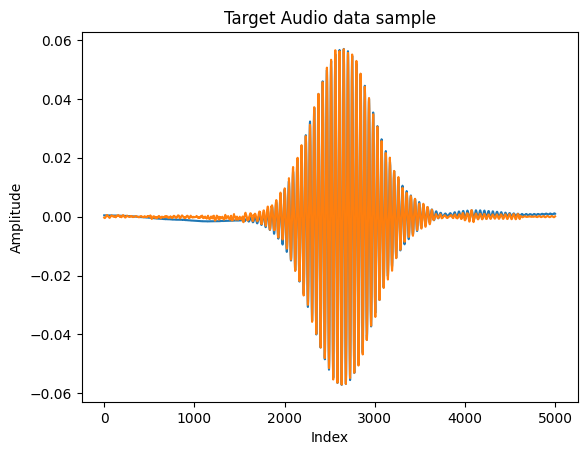

LAYER  3
Fidelity is:  tensor(0.9971, dtype=torch.float64)


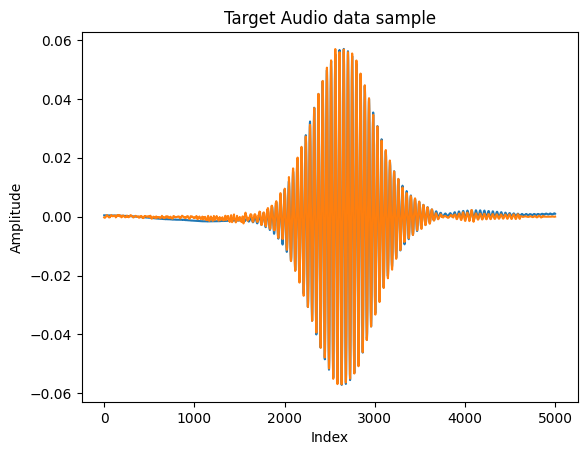

LAYER  4
Fidelity is:  tensor(0.9984, dtype=torch.float64)


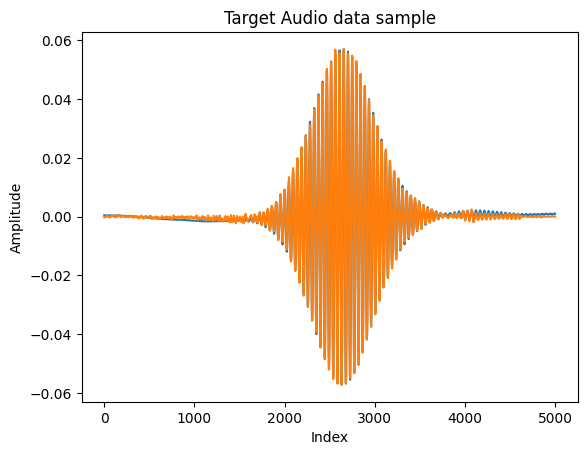

LAYER  5
Fidelity is:  tensor(0.9991, dtype=torch.float64)


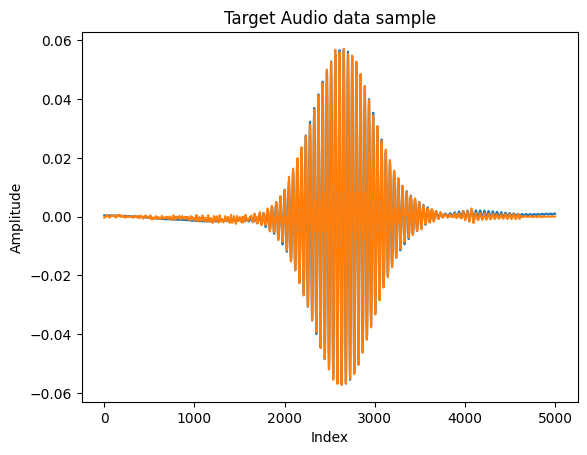

LAYER  6
Fidelity is:  tensor(0.9997, dtype=torch.float64)


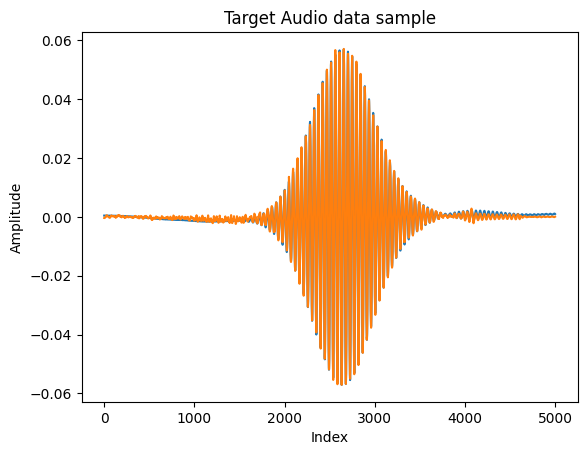

LAYER  7
Fidelity is:  tensor(0.9999, dtype=torch.float64)


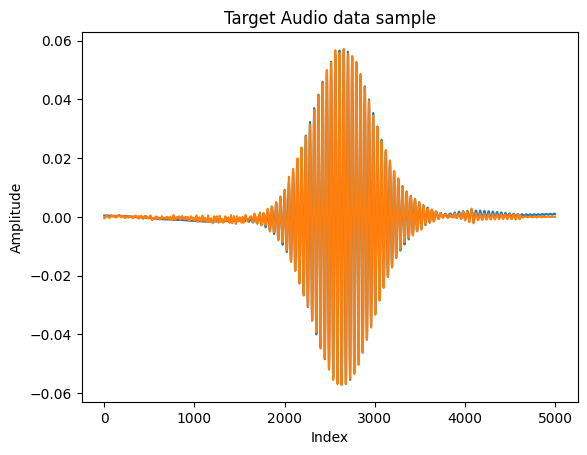

LAYER  8
Fidelity is:  tensor(1.0000, dtype=torch.float64)


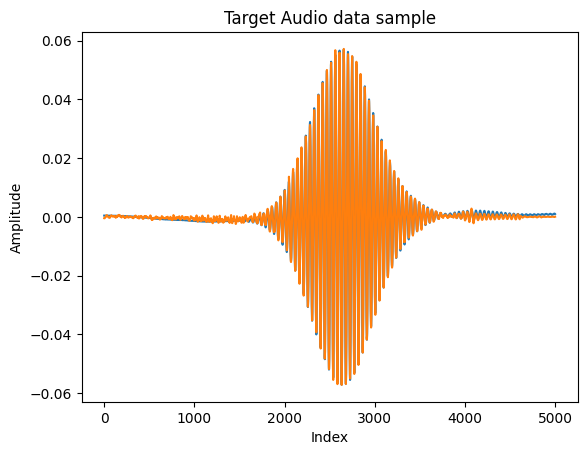

LAYER  9
Fidelity is:  tensor(1.0000, dtype=torch.float64)


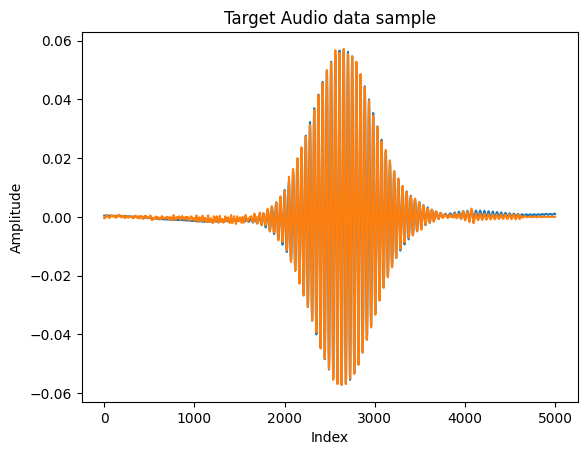

In [ ]:
#this is this stuff i changedf then didnt fix i am sorry future me!
def approx_state_to_audio(approx_state,len):
    """
    Takes an approx state tensor network, and reshapes and gives data.
    """
    extracted_vector=approx_state.contract(all).data.detach().numpy().reshape(-1)

    print(np.real(extracted_vector[:len]))
        
def get_audio_results(approx_states,len,num_layers):
    for i in range(num_layers):
        approx_state_to_audio(approx_states[i],len)
get_audio_results(approx_states,fids,5000)

In [14]:
fids

[tensor(0.9823, dtype=torch.float64),
 tensor(0.9949, dtype=torch.float64),
 tensor(0.9965, dtype=torch.float64),
 tensor(0.9971, dtype=torch.float64),
 tensor(0.9984, dtype=torch.float64),
 tensor(0.9991, dtype=torch.float64),
 tensor(0.9997, dtype=torch.float64),
 tensor(0.9999, dtype=torch.float64),
 tensor(1.0000, dtype=torch.float64),
 tensor(1.0000, dtype=torch.float64),
 tensor(1., dtype=torch.float64)]

## Results

<Figure size 700x500 with 0 Axes>

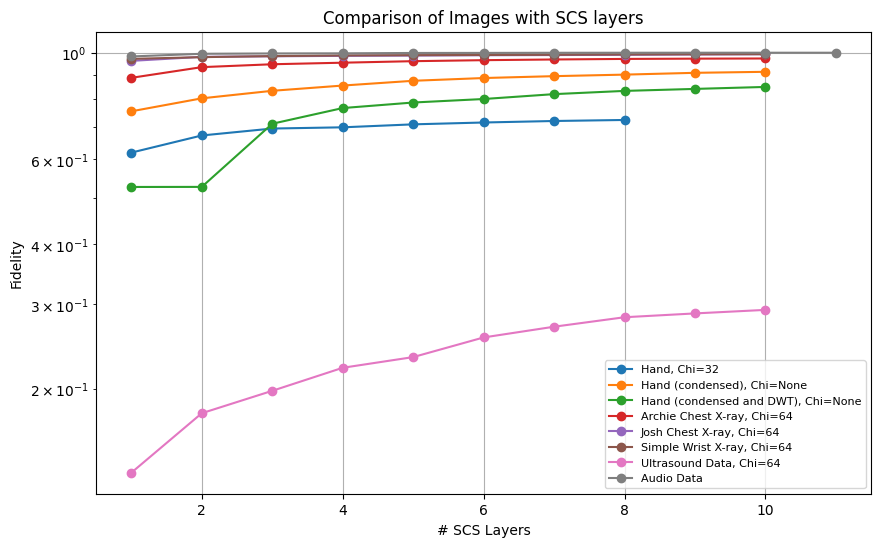

In [15]:
all_fids={"Hand, Chi=32": [0.62,0.673,0.6957,0.6998,0.7098,0.71611,0.72129,0.72484],   
          "Hand (condensed), Chi=None": [0.7555,0.8039089,0.8334,0.8546,0.8743,0.88592,0.8939157,0.9005,0.9083,0.9127],    
          "Hand (condensed and DWT), Chi=None": [0.526,0.5262,0.71185,0.76735,0.78796,0.80129,0.82022,0.833,0.841,0.849], 
          "Archie Chest X-ray, Chi=64": [0.8868,0.933328,0.9463,0.95338,0.9603344,0.96498,0.96818,0.97072,0.972,0.9728], 
          "Josh Chest X-ray, Chi=64": [0.96177155,0.98050335,0.9830746634,0.9851,0.9865,0.988,0.98894,0.99,0.9916,0.9928],
          "Simple Wrist X-ray, Chi=64": [0.971,0.979,0.984,0.98699,0.988384,0.98927777,0.99031,0.99177,0.9927,0.9932], 
          "Ultrasound Data, Chi=64": [0.134,0.178139,0.1983,0.22141,0.233026,0.2560,0.2695,0.2820,0.2872,0.2921],
          "Audio Data":[0.9823,0.9949,0.9965,0.9971,0.99884,0.9991,0.9997,0.9999,1,1,1]}
plt.figure(figsize=(7, 5))

plt.figure(figsize=(10,6))

# Plot each dataset
for label, values in all_fids.items():
    plt.plot(range(1, len(values)+1), values, marker='o', label=label)

# Labels and legend
plt.yscale('log')
plt.xlabel('# SCS Layers')
plt.ylabel('Fidelity')
plt.title('Comparison of Images with SCS layers')
plt.legend(loc='best', fontsize=8)
plt.grid(True)
plt.show()

## DWT Method for compressing/storing Image Data

In [79]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
import quimb.tensor as qtn
import torch

def dwt_image_to_mps(img, wavelet='haar', level=None, max_bond=None):
    original_shape = img.shape

    # --- 2D DWT ---
    coeffs = pywt.wavedec2(img, wavelet=wavelet, level=level)
    arr, slices = pywt.coeffs_to_array(coeffs)
    
    # Flatten
    arr_flat = arr.flatten()
    
    # --- Normalize and create MPS ---
    mps = qtn.MatrixProductState.from_dense(arr_flat)
    mps /= mps.norm()
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    
    # Optional compression
    if max_bond is not None:
        mps.compress(max_bond=max_bond)
    
    # Store original DWT array shape for reconstruction
    return mps, arr.shape, slices, original_shape

def mps_to_image(mps, arr_shape, slices, original_shape):
    # Get dense vector
    vec = mps.to_dense().real

    # Truncate/pad to match the original array size
    vec = vec[:np.prod(arr_shape)]          # truncate if MPS compress lost some entries
    vec = vec.reshape(arr_shape)            # reshape to original DWT array

    # Convert back to coeffs
    coeffs = pywt.array_to_coeffs(vec, slices, output_format='wavedec2')

    # Inverse DWT
    img_rec = pywt.waverec2(coeffs, wavelet='haar')

    # Crop to original image shape
    img_rec = img_rec[:original_shape[0], :original_shape[1]]
    
    return img_rec


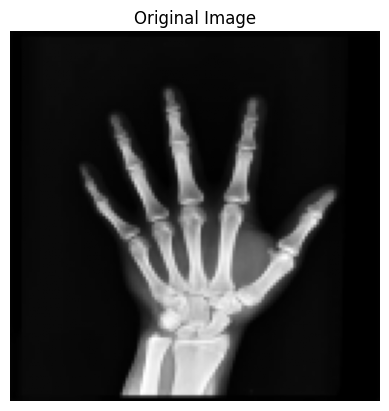

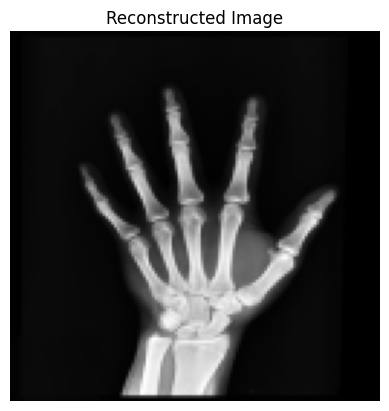

In [128]:
plt.imshow(img_condense, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

# Encode
mps, arr_shape, slices, shape = dwt_image_to_mps(img_condense)

# Decode
img_rec = mps_to_image(mps, arr_shape, slices, shape)

plt.imshow(img_rec, cmap='gray')
plt.title("Reconstructed Image")
plt.axis('off')
plt.show()

MPS ENTANGLEMENT ANALYSIS: 
Central schmidt coefficients (first 128)


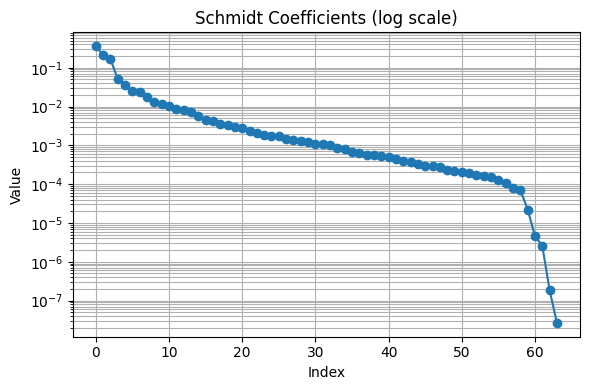

Central purity (renyi-2 anti-entropy) = 0.20677336256366177
 bond 2 = 0.5240452699396358
 bond 4 = 0.7587236068886639
 bond 6 = 0.81183470209971


In [129]:
schmidt_analysis(mps)

Okay this looks better than before (not as good as the sorted coefficients), and when compressing to bond dimensions it looks better aswell.

## Image entangelment analysis

In [90]:
def schmidt_analysis(targ_mps):
        targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
        print("MPS ENTANGLEMENT ANALYSIS: ")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        schmidt=schmidt_coeffs_from_ind(targ_mps,ind)
        print(f'Central schmidt coefficients (first 128)')
        # Convert to numpy for matplotlib
        s = schmidt.numpy()[:128]

        plt.figure(figsize=(6,4))
        plt.semilogy(s, marker='o')
        plt.title("Schmidt Coefficients (log scale)")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.grid(True, which='both')  # grid on major + minor ticks
        plt.tight_layout()
        plt.show()
        
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

In [42]:
def img_entanglement_analyse(img):   
        targ_mps = image_to_mps(img)
        targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
        print("MPS ENTANGLEMENT ANALYSIS: ")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        schmidt=schmidt_coeffs_from_ind(targ_mps,ind)
        print(f'Central schmidt coefficients (first 128)')
        # Convert to numpy for matplotlib
        s = schmidt.numpy()[:128]

        plt.figure(figsize=(6,4))
        plt.semilogy(s, marker='o')
        plt.title("Schmidt Coefficients (log scale)")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.grid(True, which='both')  # grid on major + minor ticks
        plt.tight_layout()
        plt.show()
        
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

MPS ENTANGLEMENT ANALYSIS: 
Central schmidt coefficients (first 128)


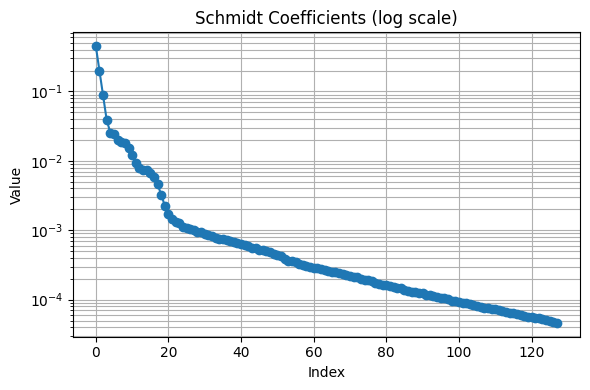

Central purity (renyi-2 anti-entropy) = 0.2525360268228145
 bond 2 = 0.3400314784963782
 bond 4 = 0.6461575269474907
 bond 6 = 0.7399927752809796


In [43]:
img_entanglement_analyse(img)


Ill try condense down the hand image now to less pizels, Josh used 128 by 128 so maybe this will work?

In [8]:
from skimage.transform import resize
# Load the image
img = mpimg.imread("handxray.jpg")[:, :, 0]
img_condense = resize(img, (128, 128), anti_aliasing=True)


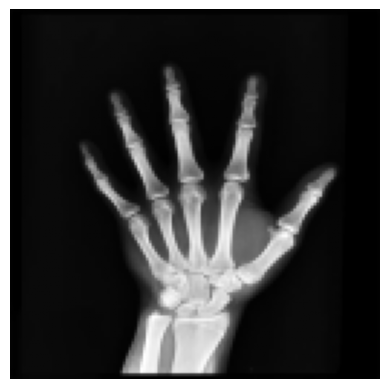

In [9]:
plt.imshow(img_condense, cmap='gray')   # `cmap='gray'` for black/white images
plt.axis('off')                # Optional: hide axis ticks
plt.show()

okay this has way less data than before so maybe at lower entanglement we will do better.

In [10]:
img_padded = pad_to_next_power_of_two(img_condense.reshape(-1), pad_value=0).astype(float)
image_condensemps = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(


In [11]:
def compress_image(imagemps: qtn.MatrixProductState,n,height,width):
    imagemps10 = imagemps.copy()
    imagemps10.compress(max_bond = n)
    image10data=imagemps10.to_dense()[:len(img.reshape(-1))]
    # Display compressed image
    print("Bond dimension: ",n)
    print("Fideltiy is:" ,(imagemps|imagemps10).contract()**2)
    plt.imshow(image10data.reshape(height,width), cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()

In [52]:
image_condensemps

MatrixProductState(tensors=14, indices=27, L=14, max_bond=115)

Bond dimension:  64
Fideltiy is: 0.999840158760564


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:36: UserWarning: Couldn't import `kahypar` - skipping from default hyper optimizer and using basic `labels` method instead. `kahypar` is highly recommended for the best quality contraction paths.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:75: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality hyper-optimization.
  warnings.warn(


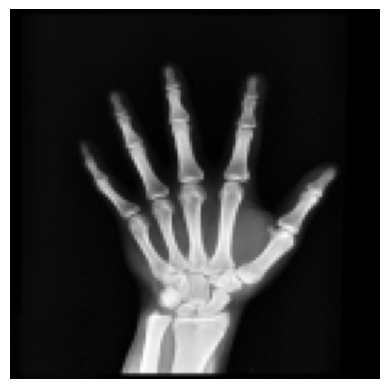

In [12]:
compress_image(image_condensemps,64,128,128)

MPS ENTANGLEMENT ANALYSIS: 
Central schmidt coefficients (first 128)


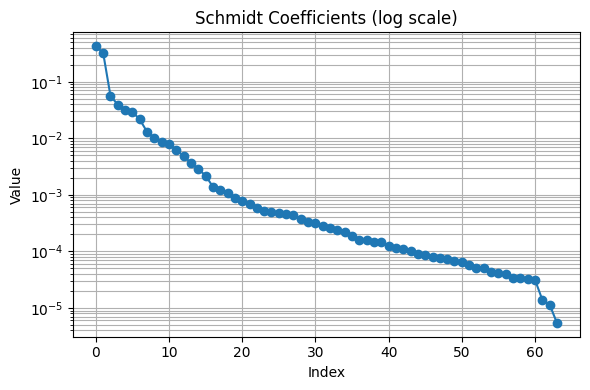

Central purity (renyi-2 anti-entropy) = 0.29337020239520206
 bond 2 = 0.716492374161534
 bond 4 = 0.8075895932923183
 bond 6 = 0.8743014743728521


In [44]:
img_entanglement_analyse(img_condense)

This is way more promising!

## My pixel ordering storage system.

### Sorting image in pixel order and looking at copression

In [70]:
def sort_pixels_and_store_order(img_array):
    """
    img_array : 1D numpy array of pixels (flattened image)
    
    Returns:
        sorted_pixels : array of sorted pixel values
        order         : array of original indices after sorting
    """
    # argsort gives the indices that would sort the array
    order = np.argsort(img_array)

    # apply the permutation
    sorted_pixels = img_array[order]

    return sorted_pixels, order


def undo_sort(sorted_pixels, order):
    """
    Reconstruct the original pixel array from sorted array + permutation.
    """
    # Create array to hold original pixels
    original = np.empty_like(sorted_pixels)

    # Undo: place each sorted pixel back at its original index
    original[order] = sorted_pixels

    return original


def sort_compress_construct(img, compression=None):
    """
    Takes an image, sorts its pixels in ascending order, MPS-encodes them,
    optionally compresses, and reconstructs.
    """

    # ---- Show original image ----
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.show()

    original_size = img.size  # number of pixels

    # ---- Pad & Sort ----
    img_flat = img.reshape(-1)
    img_padded = pad_to_next_power_of_two(img_flat, pad_value=0).astype(float)

    img_sort, order = sort_pixels_and_store_order(img_padded)

    plt.figure(figsize=(8,4))
    plt.plot(img_sort)
    plt.title("Sorted Pixel Values")
    plt.grid(True)
    plt.show()

    # ---- Build MPS ----
    targ_mps = qtn.MatrixProductState.from_dense(img_sort)
    targ_mps /= targ_mps.norm()
    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    # ---- Entanglement ----
    mid = targ_mps.L // 2
    ind = targ_mps.inner_inds()[mid]
    schmidt = schmidt_coeffs_from_ind(targ_mps, ind).numpy()

    plt.figure(figsize=(6,4))
    plt.semilogy(schmidt, marker='o')
    plt.title("Schmidt coefficients (log scale)")
    plt.grid(True, which='both')
    plt.show()

    # ---- Compression ----
    if compression is None:
        print("No compression")
        final_mps = targ_mps.copy()
    else:
        print(f"Compressing to χ = {compression}")
        final_mps = targ_mps.copy()
        final_mps.compress(max_bond=compression)

    fidelity = (final_mps | targ_mps).contract()**2
    print("Fidelity =", fidelity)

    # ---- Recover vector ----
    final_vec = final_mps.to_dense().real  # still padded order
    unsorted = undo_sort(final_vec, order)  # recover original positions

    # take the FIRST original_size pixels, not the last!
    recovered = np.abs(unsorted[:original_size])

    # ---- Show reconstructed image ----
    plt.imshow(recovered.reshape(img.shape), cmap='gray')
    plt.axis('off')
    plt.show()





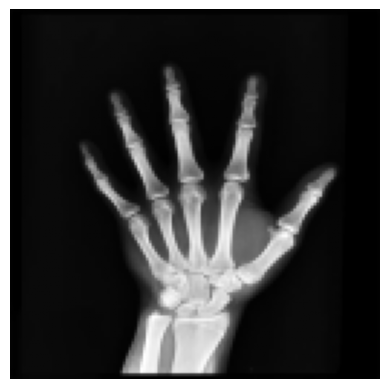

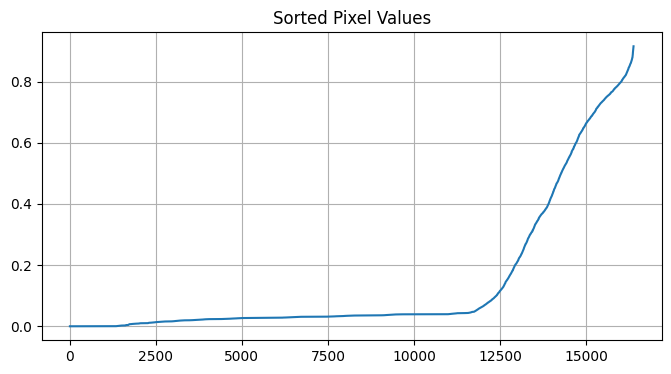

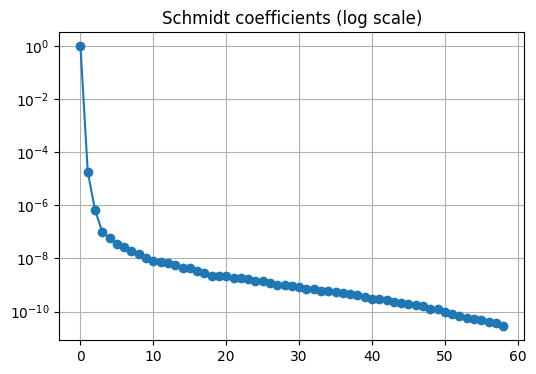

Compressing to χ = 2
Fidelity = tensor(0.9994+0.j, dtype=torch.complex128)


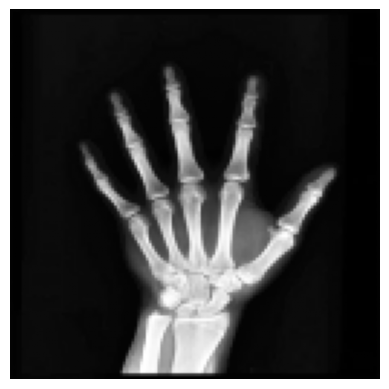

In [127]:
sort_compress_construct(img_condense,compression=2)

In [49]:
img_sort,order=sort_pixels_and_store_order(img_padded)
img_sort

array([0.        , 0.        , 0.        , ..., 0.91423003, 0.91469402,
       0.91525123], shape=(16384,))

MPS ENTANGLEMENT ANALYSIS: 
Central schmidt coefficients (first 128)


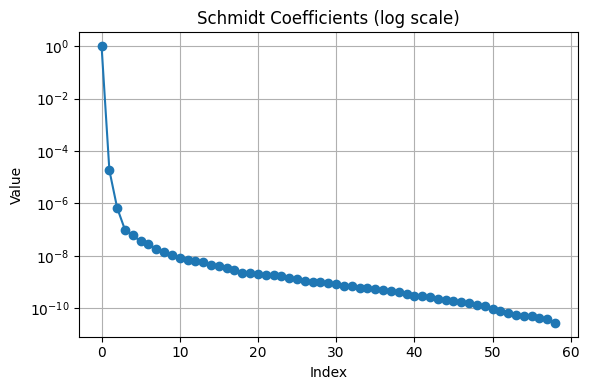

Central purity (renyi-2 anti-entropy) = 0.9999614672310612
 bond 2 = 0.9997197212784283
 bond 4 = 0.9999948938453492
 bond 6 = 0.9999990712308151


In [53]:
targ_mps=qtn.MatrixProductState.from_dense(img_sort)/qtn.MatrixProductState.from_dense(img_sort).norm()
targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
print("MPS ENTANGLEMENT ANALYSIS: ")
mid_idx = int(targ_mps.L//2)
#Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
ind = targ_mps.inner_inds()[mid_idx]
schmidt=schmidt_coeffs_from_ind(targ_mps,ind)
print(f'Central schmidt coefficients (first 128)')
# Convert to numpy for matplotlib
s = schmidt.numpy()[:128]

plt.figure(figsize=(6,4))
plt.semilogy(s, marker='o')
plt.title("Schmidt Coefficients (log scale)")
plt.xlabel("Index")
plt.ylabel("Value")
plt.grid(True, which='both')  # grid on major + minor ticks
plt.tight_layout()
plt.show()
print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

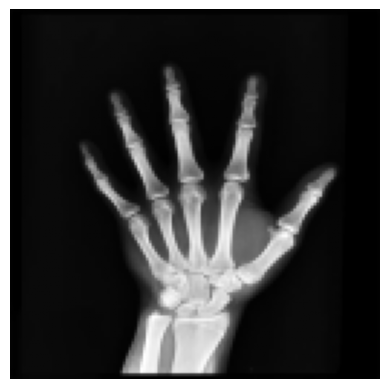

In [51]:
recovered=undo_sort(img_sort,order)
plt.imshow(recovered[:128*128].reshape(128,128), cmap='gray')   # `cmap='gray'` for black/white images
plt.axis('off')                # Optional: hide axis ticks
plt.show()

## Random

### Working out what mps_states is

In [ ]:
#A Funciton Archie made which replicates what happens at start of josh's code.
def mps_entanglement_analyse(mps):       
        targ_mps = mps.copy() 
        print("MPS ENTANGLEMENT ANALYSIS: ")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

In [ ]:
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
#need this above to make sure it can do its duty.
mps_entanglement_analyse(target_mps)

MPS ENTANGLEMENT ANALYSIS: 
2. Central schmidt coefficients = tensor([0.7931, 0.1045, 0.0722, 0.0302], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.6460319514199275
 bond 2 = 0.8814326884274276
 bond 4 = 0.9999999999999989
 bond 6 = 0.9999999999999989


In [80]:
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
#need this above to make sure it can do its duty.
mps_entanglement_analyse(mps_states[0])

MPS ENTANGLEMENT ANALYSIS: 
2. Central schmidt coefficients = tensor([8.6016e-01, 1.3840e-01, 9.2812e-04, 5.0913e-04], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.7590345321201456
 bond 2 = 0.9946507228443489
 bond 4 = 1.0000000000000022
 bond 6 = 1.0000000000000022


In [81]:
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
#need this above to make sure it can do its duty.
mps_entanglement_analyse(mps_states[1])

MPS ENTANGLEMENT ANALYSIS: 
2. Central schmidt coefficients = tensor([0.8239, 0.1761], dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.7097829999131053
 bond 2 = 1.0
 bond 4 = 1.0
 bond 6 = 1.0


Okay so the mps_states are definitily decreasing in entanglement, supporting that these are the psi(L) layers. I think to get the approx state I will have to go from the start and build the circuit with parameters, maybe this is the best way anyways. Note that at each layer there is a global optimisation being done then i cant use parameters for any subset of the layers, only the last one with the full set. Josh Green confirmed that the mps_states in indeed the disentangled states denoted psi_L in the paper, not the approximations. The approximations are calculated using the parameter set that has been commented out in the main loop, I'll now try edit the main loop function to add these states in a sperate output.